In [1]:
import pandas as pd # Data analysis tools
import numpy as np #  It provides a high-performance multidimensional array object, and tools for working with these arrays
import math as ma # Extends the list of mathematical functions
import matplotlib.pyplot as plt # Matplotlib is an amazing visualization library in Python for 2D plots of arrays
import seaborn as sns # Data visualization library based on matplotlib
import time # Various time-related functions
import matplotlib.patches as mpatches
import math  
import sklearn.metrics  
from itertools import combinations
from IPython.display import Image # Package for insert image in Python

"""There is an options function in Pandas that allows us to customize some aspects of its behavior, with the display-related 
options being the ones that the user is most likely to adjust for columns and rows being the most common."""

#pd.options.display.max_rows = 180

pd.options.display.max_columns = 9

pd.set_option('display.float_format', lambda x: '%.5f' % x)

C:\Users\muham\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\muham\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


**-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------**

**Minor variations in computed values across different implementations may occur due to differences in rounding conventions and data preprocessing procedures; however, all analyses consistently yield results indicating no statistically significant difference.**

**-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------**

# 1. Data Processing & Preparations

Uploading a CSV file with all of the countries' EPI scores and ranks.

In [2]:
"""Open the file in Python using the CSV import command."""

start = time.time()
epi2022results = pd.read_csv('EPI_data/epi2022results05302022.csv')
epi2022results.index += 1
end = time.time()
print("CSV:", end - start)
epi2022results

CSV: 0.016804933547973633


,code,iso,country,region,...,GHN.rnk.old,LCB.rnk.old,GIB.rnk.old,GHP.rnk.old
1,4,AFG,Afghanistan,Southern Asia,...,112,12.00000,129,1
2,24,AGO,Angola,Sub-Saharan Africa,...,119,135.00000,1,87
3,8,ALB,Albania,Eastern Europe,...,39,37.00000,25,67
4,784,ARE,United Arab Emirates,Greater Middle East,...,157,162.00000,141,173
5,32,ARG,Argentina,Latin America & Caribbean,...,160,128.00000,93,134
...,...,...,...,...,...,...,...,...,...
176,548,VUT,Vanuatu,Asia-Pacific,...,16,130.00000,137,67
177,882,WSM,Samoa,Asia-Pacific,...,12,NaN,90,48
178,710,ZAF,South Africa,Sub-Saharan Africa,...,170,30.00000,125,155
179,894,ZMB,Zambia,Sub-Saharan Africa,...,84,160.00000,18,53


This is a list of all 180 countries that were in the previous uploaded CSV file.

In [3]:
countries_all180 = epi2022results['country'].tolist()

The raw datasets for all 40 indicators have been uploaded. We then transferred the most recent year from each raw dataset to a new dataframe for 180 countries. 

Comprehensive details regarding each indicator are accessible in the Technical Appendix, which can be found on the official website at the following link: https://sedac.ciesin.columbia.edu/downloads/data/epi/epi-environmental-performance-index-2022/2022-epi-technical-appendix.pdf. 

In [4]:
#1 GNN

epi2022results_GHN_all = epi2022results[['code','iso','country','GHN.new','GHN.old','GHN.change','GHN.rnk.new','GHN.rnk.old']]
epi2022results_GHN_all_sorted = epi2022results_GHN_all.sort_values("GHN.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_GHN = pd.read_csv('EPI_data/2022 EPI Raw Data/GHN_raw_na.csv')
epi2022_GHN_180 = epi2022_GHN[~epi2022_GHN.country.isin(countries_all180) != True]
epi2022_GHN_10y = epi2022_GHN_180.drop(epi2022_GHN_180.iloc[:, 3:14],axis = 1)
GHN_sorted = epi2022results_GHN_all_sorted['country'].unique().tolist()
epi2022_GHN_10y.country = epi2022_GHN_10y.country.astype("category")
epi2022_GHN_10y.country = epi2022_GHN_10y.country.cat.set_categories(GHN_sorted)
epi2022_GHN_10y_sorted = epi2022_GHN_10y.sort_values(["country"])
epi2022_GHN_10y_sorted = epi2022_GHN_10y_sorted.set_index(epi2022results_GHN_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_GHN_10y_sorted = epi2022_GHN_10y_sorted.set_index(["country","code","iso"])
new_epi2022_GHN_latest_year = new_epi2022_GHN_10y_sorted.drop(new_epi2022_GHN_10y_sorted.iloc[:, 0:9],axis = 1)

#2 CDA

epi2022results_CDA_all = epi2022results[['code','iso','country','CDA.new','CDA.old','CDA.change','CDA.rnk.new','CDA.rnk.old']]
epi2022results_CDA_all_sorted = epi2022results_CDA_all.sort_values("CDA.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_CDA = pd.read_csv('EPI_data/2022 EPI Raw Data/CDA_raw_na.csv')
epi2022_CDA_180 = epi2022_CDA[~epi2022_CDA.country.isin(countries_all180) != True]
epi2022_CDA_10y = epi2022_CDA_180.drop(epi2022_CDA_180.iloc[:, 3:14],axis = 1)
CDA_sorted = epi2022results_CDA_all_sorted['country'].unique().tolist()
epi2022_CDA_10y.country = epi2022_CDA_10y.country.astype("category")
epi2022_CDA_10y.country = epi2022_CDA_10y.country.cat.set_categories(CDA_sorted)
epi2022_CDA_10y_sorted = epi2022_CDA_10y.sort_values(["country"])
epi2022_CDA_10y_sorted = epi2022_CDA_10y_sorted.set_index(epi2022results_CDA_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_CDA_10y_sorted = epi2022_CDA_10y_sorted.set_index(["country","code","iso"])
new_epi2022_CDA_latest_year = new_epi2022_CDA_10y_sorted.drop(new_epi2022_CDA_10y_sorted.iloc[:, 0:9],axis = 1)

#3 CHA

epi2022results_CHA_all = epi2022results[['code','iso','country','CHA.new','CHA.old','CHA.change','CHA.rnk.new','CHA.rnk.old']]
epi2022results_CHA_all_sorted = epi2022results_CHA_all.sort_values("CHA.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_CHA = pd.read_csv('EPI_data/2022 EPI Raw Data/CHA_raw_na.csv')
epi2022_CHA_180 = epi2022_CHA[~epi2022_CHA.country.isin(countries_all180) != True]
epi2022_CHA_10y = epi2022_CHA_180.drop(epi2022_CHA_180.iloc[:, 3:14],axis = 1)
CHA_sorted = epi2022results_CHA_all_sorted['country'].unique().tolist()
epi2022_CHA_10y.country = epi2022_CHA_10y.country.astype("category")
epi2022_CHA_10y.country = epi2022_CHA_10y.country.cat.set_categories(CHA_sorted)
epi2022_CHA_10y_sorted = epi2022_CHA_10y.sort_values(["country"])
epi2022_CHA_10y_sorted = epi2022_CHA_10y_sorted.set_index(epi2022results_CHA_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_CHA_10y_sorted = epi2022_CHA_10y_sorted.set_index(["country","code","iso"])
new_epi2022_CHA_latest_year = new_epi2022_CHA_10y_sorted.drop(new_epi2022_CHA_10y_sorted.iloc[:, 0:9],axis = 1)

#4 LCB

epi2022results_LCB_all = epi2022results[['code','iso','country','LCB.new','LCB.old','LCB.change','LCB.rnk.new','LCB.rnk.old']]
epi2022results_LCB_all_sorted = epi2022results_LCB_all.sort_values("LCB.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_LCB = pd.read_csv('EPI_data/2022 EPI Raw Data/LCB_raw_na.csv')
epi2022_LCB_180 = epi2022_LCB[~epi2022_LCB.country.isin(countries_all180) != True]
epi2022_LCB_10y = epi2022_LCB_180.drop(epi2022_LCB_180.iloc[:, 3:5],axis = 1)
LCB_sorted = epi2022results_LCB_all_sorted['country'].unique().tolist()
epi2022_LCB_10y.country = epi2022_LCB_10y.country.astype("category")
epi2022_LCB_10y.country = epi2022_LCB_10y.country.cat.set_categories(LCB_sorted)
epi2022_LCB_10y_sorted = epi2022_LCB_10y.sort_values(["country"])
epi2022_LCB_10y_sorted = epi2022_LCB_10y_sorted.set_index(epi2022results_LCB_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_LCB_10y_sorted = epi2022_LCB_10y_sorted.set_index(["country","code","iso"])
new_epi2022_LCB_latest_year = new_epi2022_LCB_10y_sorted.drop(new_epi2022_LCB_10y_sorted.iloc[:, 0:5],axis = 1)

#5 GIB

epi2022results_GIB_all = epi2022results[['code','iso','country','GIB.new','GIB.old','GIB.change','GIB.rnk.new','GIB.rnk.old']]
epi2022results_GIB_all_sorted = epi2022results_GIB_all.sort_values("GIB.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_GIB = pd.read_csv('EPI_data/2022 EPI Raw Data/GIB_raw_na.csv')
epi2022_GIB_180 = epi2022_GIB[~epi2022_GIB.country.isin(countries_all180) != True]
epi2022_GIB_10y = epi2022_GIB_180.drop(epi2022_GIB_180.iloc[:, 3:14],axis = 1)
GIB_sorted = epi2022results_GIB_all_sorted['country'].unique().tolist()
epi2022_GIB_10y.country = epi2022_GIB_10y.country.astype("category")
epi2022_GIB_10y.country = epi2022_GIB_10y.country.cat.set_categories(GIB_sorted)
epi2022_GIB_10y_sorted = epi2022_GIB_10y.sort_values(["country"])
epi2022_GIB_10y_sorted = epi2022_GIB_10y_sorted.set_index(epi2022results_GIB_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_GIB_10y_sorted = epi2022_GIB_10y_sorted.set_index(["country","code","iso"])
new_epi2022_GIB_latest_year = new_epi2022_GIB_10y_sorted.drop(new_epi2022_GIB_10y_sorted.iloc[:, 0:9],axis = 1)

#6 FGA

epi2022results_FGA_all = epi2022results[['code','iso','country','FGA.new','FGA.old','FGA.change','FGA.rnk.new','FGA.rnk.old']]
epi2022results_FGA_all_sorted = epi2022results_FGA_all.sort_values("FGA.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_FGA = pd.read_csv('EPI_data/2022 EPI Raw Data/FGA_raw_na.csv')
epi2022_FGA_180 = epi2022_FGA[~epi2022_FGA.country.isin(countries_all180) != True]
epi2022_FGA_10y = epi2022_FGA_180.drop(epi2022_FGA_180.iloc[:, 3:14],axis = 1)
FGA_sorted = epi2022results_FGA_all_sorted['country'].unique().tolist()
epi2022_FGA_10y.country = epi2022_FGA_10y.country.astype("category")
epi2022_FGA_10y.country = epi2022_FGA_10y.country.cat.set_categories(FGA_sorted)
epi2022_FGA_10y_sorted = epi2022_FGA_10y.sort_values(["country"])
epi2022_FGA_10y_sorted = epi2022_FGA_10y_sorted.set_index(epi2022results_FGA_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_FGA_10y_sorted = epi2022_FGA_10y_sorted.set_index(["country","code","iso"])
new_epi2022_FGA_latest_year = new_epi2022_FGA_10y_sorted.drop(new_epi2022_FGA_10y_sorted.iloc[:, 0:9],axis = 1)

#7 BCA

epi2022results_BCA_all = epi2022results[['code','iso','country','BCA.new','BCA.old','BCA.change','BCA.rnk.new','BCA.rnk.old']]
epi2022results_BCA_all_sorted = epi2022results_BCA_all.sort_values("BCA.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_BCA = pd.read_csv('EPI_data/2022 EPI Raw Data/BCA_raw_na.csv')
epi2022_BCA_180 = epi2022_BCA[~epi2022_BCA.country.isin(countries_all180) != True]
epi2022_BCA_10y = epi2022_BCA_180.drop(epi2022_BCA_180.iloc[:, 3:14],axis = 1)
BCA_sorted = epi2022results_BCA_all_sorted['country'].unique().tolist()
epi2022_BCA_10y.country = epi2022_BCA_10y.country.astype("category")
epi2022_BCA_10y.country = epi2022_BCA_10y.country.cat.set_categories(BCA_sorted)
epi2022_BCA_10y_sorted = epi2022_BCA_10y.sort_values(["country"])
epi2022_BCA_10y_sorted = epi2022_BCA_10y_sorted.set_index(epi2022results_BCA_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_BCA_10y_sorted = epi2022_BCA_10y_sorted.set_index(["country","code","iso"])
new_epi2022_BCA_latest_year = new_epi2022_BCA_10y_sorted.drop(new_epi2022_BCA_10y_sorted.iloc[:, 0:9],axis = 1)

#8 GHP

epi2022results_GHP_all = epi2022results[['code','iso','country','GHP.new','GHP.old','GHP.change','GHP.rnk.new','GHP.rnk.old']]
epi2022results_GHP_all_sorted = epi2022results_GHP_all.sort_values("GHP.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_GHP = pd.read_csv('EPI_data/2022 EPI Raw Data/GHP_raw_na.csv')
epi2022_GHP_180 = epi2022_GHP[~epi2022_GHP.country.isin(countries_all180) != True]
epi2022_GHP_10y = epi2022_GHP_180.drop(epi2022_GHP_180.iloc[:, 3:263],axis = 1)
GHP_sorted = epi2022results_GHP_all_sorted['country'].unique().tolist()
epi2022_GHP_10y.country = epi2022_GHP_10y.country.astype("category")
epi2022_GHP_10y.country = epi2022_GHP_10y.country.cat.set_categories(GHP_sorted)
epi2022_GHP_10y_sorted = epi2022_GHP_10y.sort_values(["country"])
epi2022_GHP_10y_sorted = epi2022_GHP_10y_sorted.set_index(epi2022results_GHP_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_GHP_10y_sorted = epi2022_GHP_10y_sorted.set_index(["country","code","iso"])
new_epi2022_GHP_latest_year = new_epi2022_GHP_10y_sorted.drop(new_epi2022_GHP_10y_sorted.iloc[:, 0:9],axis = 1)

#9 NDA

epi2022results_NDA_all = epi2022results[['code','iso','country','NDA.new','NDA.old','NDA.change','NDA.rnk.new','NDA.rnk.old']]
epi2022results_NDA_all_sorted = epi2022results_NDA_all.sort_values("NDA.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_NDA = pd.read_csv('EPI_data/2022 EPI Raw Data/NDA_raw_na.csv')
epi2022_NDA_180 = epi2022_NDA[~epi2022_NDA.country.isin(countries_all180) != True]
epi2022_NDA_10y = epi2022_NDA_180.drop(epi2022_NDA_180.iloc[:, 3:14],axis = 1)
NDA_sorted = epi2022results_NDA_all_sorted['country'].unique().tolist()
epi2022_NDA_10y.country = epi2022_NDA_10y.country.astype("category")
epi2022_NDA_10y.country = epi2022_NDA_10y.country.cat.set_categories(NDA_sorted)
epi2022_NDA_10y_sorted = epi2022_NDA_10y.sort_values(["country"])
epi2022_NDA_10y_sorted = epi2022_NDA_10y_sorted.set_index(epi2022results_NDA_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_NDA_10y_sorted = epi2022_NDA_10y_sorted.set_index(["country","code","iso"])
new_epi2022_NDA_latest_year = new_epi2022_NDA_10y_sorted.drop(new_epi2022_NDA_10y_sorted.iloc[:, 0:9],axis = 1)

#10 PMD

epi2022results_PMD_all = epi2022results[['code','iso','country','PMD.new','PMD.old','PMD.change','PMD.rnk.new','PMD.rnk.old']]
epi2022results_PMD_all_sorted = epi2022results_PMD_all.sort_values("PMD.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_PMD = pd.read_csv('EPI_data/2022 EPI Raw Data/PMD_raw_na.csv')
epi2022_PMD_180 = epi2022_PMD[~epi2022_PMD.country.isin(countries_all180) != True]
epi2022_PMD_10y = epi2022_PMD_180.drop(epi2022_PMD_180.iloc[:, 3:14],axis = 1)
PMD_sorted = epi2022results_PMD_all_sorted['country'].unique().tolist()
epi2022_PMD_10y.country = epi2022_PMD_10y.country.astype("category")
epi2022_PMD_10y.country = epi2022_PMD_10y.country.cat.set_categories(PMD_sorted)
epi2022_PMD_10y_sorted = epi2022_PMD_10y.sort_values(["country"])
epi2022_PMD_10y_sorted = epi2022_PMD_10y_sorted.set_index(epi2022results_PMD_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_PMD_10y_sorted = epi2022_PMD_10y_sorted.set_index(["country","code","iso"])
new_epi2022_PMD_latest_year = new_epi2022_PMD_10y_sorted.drop(new_epi2022_PMD_10y_sorted.iloc[:, 0:18],axis = 1)

#11 HAD

epi2022results_HAD_all = epi2022results[['code','iso','country','HAD.new','HAD.old','HAD.change','HAD.rnk.new','HAD.rnk.old']]
epi2022results_HAD_all_sorted = epi2022results_HAD_all.sort_values("HAD.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_HAD = pd.read_csv('EPI_data/2022 EPI Raw Data/HAD_raw_na.csv')
epi2022_HAD_180 = epi2022_HAD[~epi2022_HAD.country.isin(countries_all180) != True]
epi2022_HAD_10y = epi2022_HAD_180.drop(epi2022_HAD_180.iloc[:, 3:14],axis = 1)
HAD_sorted = epi2022results_HAD_all_sorted['country'].unique().tolist()
epi2022_HAD_10y.country = epi2022_HAD_10y.country.astype("category")
epi2022_HAD_10y.country = epi2022_HAD_10y.country.cat.set_categories(HAD_sorted)
epi2022_HAD_10y_sorted = epi2022_HAD_10y.sort_values(["country"])
epi2022_HAD_10y_sorted = epi2022_HAD_10y_sorted.set_index(epi2022results_HAD_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_HAD_10y_sorted = epi2022_HAD_10y_sorted.set_index(["country","code","iso"])
new_epi2022_HAD_latest_year = new_epi2022_HAD_10y_sorted.drop(new_epi2022_HAD_10y_sorted.iloc[:, 0:18],axis = 1)

#12 OZD

epi2022results_OZD_all = epi2022results[['code','iso','country','OZD.new','OZD.old','OZD.change','OZD.rnk.new','OZD.rnk.old']]
epi2022results_OZD_all_sorted = epi2022results_OZD_all.sort_values("OZD.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_OZD = pd.read_csv('EPI_data/2022 EPI Raw Data/OZD_raw_na.csv')
epi2022_OZD_180 = epi2022_OZD[~epi2022_OZD.country.isin(countries_all180) != True]
epi2022_OZD_10y = epi2022_OZD_180.drop(epi2022_OZD_180.iloc[:, 3:14],axis = 1)
OZD_sorted = epi2022results_OZD_all_sorted['country'].unique().tolist()
epi2022_OZD_10y.country = epi2022_OZD_10y.country.astype("category")
epi2022_OZD_10y.country = epi2022_OZD_10y.country.cat.set_categories(OZD_sorted)
epi2022_OZD_10y_sorted = epi2022_OZD_10y.sort_values(["country"])
epi2022_OZD_10y_sorted = epi2022_OZD_10y_sorted.set_index(epi2022results_OZD_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_OZD_10y_sorted = epi2022_OZD_10y_sorted.set_index(["country","code","iso"])
new_epi2022_OZD_latest_year = new_epi2022_OZD_10y_sorted.drop(new_epi2022_OZD_10y_sorted.iloc[:, 0:18],axis = 1)

#13 NOE

epi2022results_NOE_all = epi2022results[['code','iso','country','NOE.new','NOE.old','NOE.change','NOE.rnk.new','NOE.rnk.old']]
epi2022results_NOE_all_sorted = epi2022results_NOE_all.sort_values("NOE.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_NOE = pd.read_csv('EPI_data/2022 EPI Raw Data/NOE_raw_na.csv')
epi2022_NOE_180 = epi2022_NOE[~epi2022_NOE.country.isin(countries_all180) != True]
epi2022_NOE_10y = epi2022_NOE_180.drop(epi2022_NOE_180.iloc[:, 3:14],axis = 1)
NOE_sorted = epi2022results_NOE_all_sorted['country'].unique().tolist()
epi2022_NOE_10y.country = epi2022_NOE_10y.country.astype("category")
epi2022_NOE_10y.country = epi2022_NOE_10y.country.cat.set_categories(NOE_sorted)
epi2022_NOE_10y_sorted = epi2022_NOE_10y.sort_values(["country"])
epi2022_NOE_10y_sorted = epi2022_NOE_10y_sorted.set_index(epi2022results_NOE_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_NOE_10y_sorted = epi2022_NOE_10y_sorted.set_index(["country","code","iso"])
new_epi2022_NOE_latest_year = new_epi2022_NOE_10y_sorted.drop(new_epi2022_NOE_10y_sorted.iloc[:, 0:5],axis = 1)

#14 SOE

epi2022results_SOE_all = epi2022results[['code','iso','country','SOE.new','SOE.old','SOE.change','SOE.rnk.new','SOE.rnk.old']]
epi2022results_SOE_all_sorted = epi2022results_SOE_all.sort_values("SOE.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_SOE = pd.read_csv('EPI_data/2022 EPI Raw Data/SOE_raw_na.csv')
epi2022_SOE_180 = epi2022_SOE[~epi2022_SOE.country.isin(countries_all180) != True]
epi2022_SOE_10y = epi2022_SOE_180.drop(epi2022_SOE_180.iloc[:, 3:14],axis = 1)
SOE_sorted = epi2022results_SOE_all_sorted['country'].unique().tolist()
epi2022_SOE_10y.country = epi2022_SOE_10y.country.astype("category")
epi2022_SOE_10y.country = epi2022_SOE_10y.country.cat.set_categories(SOE_sorted)
epi2022_SOE_10y_sorted = epi2022_SOE_10y.sort_values(["country"])
epi2022_SOE_10y_sorted = epi2022_SOE_10y_sorted.set_index(epi2022results_SOE_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_SOE_10y_sorted = epi2022_SOE_10y_sorted.set_index(["country","code","iso"])
new_epi2022_SOE_latest_year = new_epi2022_SOE_10y_sorted.drop(new_epi2022_SOE_10y_sorted.iloc[:, 0:5],axis = 1)

#15 COE

epi2022results_COE_all = epi2022results[['code','iso','country','COE.new','COE.old','COE.change','COE.rnk.new','COE.rnk.old']]
epi2022results_COE_all_sorted = epi2022results_COE_all.sort_values("COE.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_COE = pd.read_csv('EPI_data/2022 EPI Raw Data/COE_raw_na.csv')
epi2022_COE_180 = epi2022_COE[~epi2022_COE.country.isin(countries_all180) != True]
epi2022_COE_10y = epi2022_COE_180.drop(epi2022_COE_180.iloc[:, 3:14],axis = 1)
COE_sorted = epi2022results_COE_all_sorted['country'].unique().tolist()
epi2022_COE_10y.country = epi2022_COE_10y.country.astype("category")
epi2022_COE_10y.country = epi2022_COE_10y.country.cat.set_categories(COE_sorted)
epi2022_COE_10y_sorted = epi2022_COE_10y.sort_values(["country"])
epi2022_COE_10y_sorted = epi2022_COE_10y_sorted.set_index(epi2022results_COE_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_COE_10y_sorted = epi2022_COE_10y_sorted.set_index(["country","code","iso"])
new_epi2022_COE_latest_year = new_epi2022_COE_10y_sorted.drop(new_epi2022_COE_10y_sorted.iloc[:, 0:5],axis = 1)

#16 VOE

epi2022results_VOE_all = epi2022results[['code','iso','country','VOE.new','VOE.old','VOE.change','VOE.rnk.new','VOE.rnk.old']]
epi2022results_VOE_all_sorted = epi2022results_VOE_all.sort_values("VOE.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_VOE = pd.read_csv('EPI_data/2022 EPI Raw Data/VOE_raw_na.csv')
epi2022_VOE_180 = epi2022_VOE[~epi2022_VOE.country.isin(countries_all180) != True]
epi2022_VOE_10y = epi2022_VOE_180.drop(epi2022_VOE_180.iloc[:, 3:14],axis = 1)
VOE_sorted = epi2022results_VOE_all_sorted['country'].unique().tolist()
epi2022_VOE_10y.country = epi2022_VOE_10y.country.astype("category")
epi2022_VOE_10y.country = epi2022_VOE_10y.country.cat.set_categories(VOE_sorted)
epi2022_VOE_10y_sorted = epi2022_VOE_10y.sort_values(["country"])
epi2022_VOE_10y_sorted = epi2022_VOE_10y_sorted.set_index(epi2022results_VOE_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_VOE_10y_sorted = epi2022_VOE_10y_sorted.set_index(["country","code","iso"])
new_epi2022_VOE_latest_year = new_epi2022_VOE_10y_sorted.drop(new_epi2022_VOE_10y_sorted.iloc[:, 0:5],axis = 1)

#17 UWD

epi2022results_UWD_all = epi2022results[['code','iso','country','UWD.new','UWD.old','UWD.change','UWD.rnk.new','UWD.rnk.old']]
epi2022results_UWD_all_sorted = epi2022results_UWD_all.sort_values("UWD.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_UWD = pd.read_csv('EPI_data/2022 EPI Raw Data/UWD_raw_na.csv')
epi2022_UWD_180 = epi2022_UWD[~epi2022_UWD.country.isin(countries_all180) != True]
epi2022_UWD_10y = epi2022_UWD_180.drop(epi2022_UWD_180.iloc[:, 3:14],axis = 1)
UWD_sorted = epi2022results_UWD_all_sorted['country'].unique().tolist()
epi2022_UWD_10y.country = epi2022_UWD_10y.country.astype("category")
epi2022_UWD_10y.country = epi2022_UWD_10y.country.cat.set_categories(UWD_sorted)
epi2022_UWD_10y_sorted = epi2022_UWD_10y.sort_values(["country"])
epi2022_UWD_10y_sorted = epi2022_UWD_10y_sorted.set_index(epi2022results_UWD_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_UWD_10y_sorted = epi2022_UWD_10y_sorted.set_index(["country","code","iso"])
new_epi2022_UWD_latest_year = new_epi2022_UWD_10y_sorted.drop(new_epi2022_UWD_10y_sorted.iloc[:, 0:18],axis = 1)

#18 USD

epi2022results_USD_all = epi2022results[['code','iso','country','USD.new','USD.old','USD.change','USD.rnk.new','USD.rnk.old']]
epi2022results_USD_all_sorted = epi2022results_USD_all.sort_values("USD.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_USD = pd.read_csv('EPI_data/2022 EPI Raw Data/USD_raw_na.csv')
epi2022_USD_180 = epi2022_USD[~epi2022_USD.country.isin(countries_all180) != True]
epi2022_USD_10y = epi2022_USD_180.drop(epi2022_USD_180.iloc[:, 3:14],axis = 1)
USD_sorted = epi2022results_USD_all_sorted['country'].unique().tolist()
epi2022_USD_10y.country = epi2022_USD_10y.country.astype("category")
epi2022_USD_10y.country = epi2022_USD_10y.country.cat.set_categories(USD_sorted)
epi2022_USD_10y_sorted = epi2022_USD_10y.sort_values(["country"])
epi2022_USD_10y_sorted = epi2022_USD_10y_sorted.set_index(epi2022results_USD_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_USD_10y_sorted = epi2022_USD_10y_sorted.set_index(["country","code","iso"])
new_epi2022_USD_latest_year = new_epi2022_USD_10y_sorted.drop(new_epi2022_USD_10y_sorted.iloc[:, 0:18],axis = 1)

#19 PBD

epi2022results_PBD_all = epi2022results[['code','iso','country','PBD.new','PBD.old','PBD.change','PBD.rnk.new','PBD.rnk.old']]
epi2022results_PBD_all_sorted = epi2022results_PBD_all.sort_values("PBD.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_PBD = pd.read_csv('EPI_data/2022 EPI Raw Data/PBD_raw_na.csv')
epi2022_PBD_180 = epi2022_PBD[~epi2022_PBD.country.isin(countries_all180) != True]
epi2022_PBD_10y = epi2022_PBD_180.drop(epi2022_PBD_180.iloc[:, 3:14],axis = 1)
PBD_sorted = epi2022results_PBD_all_sorted['country'].unique().tolist()
epi2022_PBD_10y.country = epi2022_PBD_10y.country.astype("category")
epi2022_PBD_10y.country = epi2022_PBD_10y.country.cat.set_categories(PBD_sorted)
epi2022_PBD_10y_sorted = epi2022_PBD_10y.sort_values(["country"])
epi2022_PBD_10y_sorted = epi2022_PBD_10y_sorted.set_index(epi2022results_PBD_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_PBD_10y_sorted = epi2022_PBD_10y_sorted.set_index(["country","code","iso"])
new_epi2022_PBD_latest_year = new_epi2022_PBD_10y_sorted.drop(new_epi2022_PBD_10y_sorted.iloc[:, 0:18],axis = 1)

#20 MSW

epi2022results_MSW_all = epi2022results[['code','iso','country','MSW.new','MSW.old','MSW.change','MSW.rnk.new','MSW.rnk.old']]
epi2022results_MSW_all_sorted = epi2022results_MSW_all.sort_values("MSW.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_MSW = pd.read_csv('EPI_data/2022 EPI Raw Data/MSW_raw_na.csv')
epi2022_MSW_180 = epi2022_MSW[~epi2022_MSW.country.isin(countries_all180) != True]
epi2022_MSW_10y = epi2022_MSW_180#.drop(epi2022_MSW_180.iloc[:, 3:14],axis = 1)
MSW_sorted = epi2022results_MSW_all_sorted['country'].unique().tolist()
epi2022_MSW_10y.country = epi2022_MSW_10y.country.astype("category")
epi2022_MSW_10y.country = epi2022_MSW_10y.country.cat.set_categories(MSW_sorted)
epi2022_MSW_10y_sorted = epi2022_MSW_10y.sort_values(["country"])
epi2022_MSW_10y_sorted = epi2022_MSW_10y_sorted.set_index(epi2022results_MSW_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_MSW_10y_sorted = epi2022_MSW_10y_sorted.set_index(["country","code","iso"])
new_epi2022_MSW_latest_year = new_epi2022_MSW_10y_sorted#.drop(new_epi2022_MSW_10y_sorted.iloc[:, 0:9],axis = 1)

#21 REC

epi2022results_REC_all = epi2022results[['code','iso','country','REC.new','REC.old','REC.change','REC.rnk.new','REC.rnk.old']]
epi2022results_REC_all_sorted = epi2022results_REC_all.sort_values("REC.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_REC = pd.read_csv('EPI_data/2022 EPI Raw Data/REC_raw_na.csv')
epi2022_REC_180 = epi2022_REC[~epi2022_REC.country.isin(countries_all180) != True]
epi2022_REC_10y = epi2022_REC_180.drop(epi2022_REC_180.iloc[:, 3:5],axis = 1)
REC_sorted = epi2022results_REC_all_sorted['country'].unique().tolist()
epi2022_REC_10y.country = epi2022_REC_10y.country.astype("category")
epi2022_REC_10y.country = epi2022_REC_10y.country.cat.set_categories(REC_sorted)
epi2022_REC_10y_sorted = epi2022_REC_10y.sort_values(["country"])
epi2022_REC_10y_sorted = epi2022_REC_10y_sorted.set_index(epi2022results_REC_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_REC_10y_sorted = epi2022_REC_10y_sorted.set_index(["country","code","iso"])
new_epi2022_REC_latest_year = new_epi2022_REC_10y_sorted.drop(new_epi2022_REC_10y_sorted.iloc[:, 0:4],axis = 1)

#22 OCP

epi2022results_OCP_all = epi2022results[['code','iso','country','OCP.new','OCP.old','OCP.change','OCP.rnk.new','OCP.rnk.old']]
epi2022results_OCP_all_sorted = epi2022results_OCP_all.sort_values("OCP.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_OCP = pd.read_csv('EPI_data/2022 EPI Raw Data/OCP_raw_na.csv')
epi2022_OCP_180 = epi2022_OCP[~epi2022_OCP.country.isin(countries_all180) != True]
epi2022_OCP_10y = epi2022_OCP_180.drop(epi2022_OCP_180.iloc[:, 3:5],axis = 1)
OCP_sorted = epi2022results_OCP_all_sorted['country'].unique().tolist()
epi2022_OCP_10y.country = epi2022_OCP_10y.country.astype("category")
epi2022_OCP_10y.country = epi2022_OCP_10y.country.cat.set_categories(OCP_sorted)
epi2022_OCP_10y_sorted = epi2022_OCP_10y.sort_values(["country"])
epi2022_OCP_10y_sorted = epi2022_OCP_10y_sorted.set_index(epi2022results_OCP_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_OCP_10y_sorted = epi2022_OCP_10y_sorted.set_index(["country","code","iso"])
new_epi2022_OCP_latest_year = new_epi2022_OCP_10y_sorted.drop(new_epi2022_OCP_10y_sorted.iloc[:, 0:4],axis = 1)

#23 TBN

epi2022results_TBN_all = epi2022results[['code','iso','country','TBN.new','TBN.old','TBN.change','TBN.rnk.new','TBN.rnk.old']]
epi2022results_TBN_all_sorted = epi2022results_TBN_all.sort_values("TBN.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_TBN = pd.read_csv('EPI_data/2022 EPI Raw Data/TBN_raw_na.csv')
epi2022_TBN_180 = epi2022_TBN[~epi2022_TBN.country.isin(countries_all180) != True]
epi2022_TBN_10y = epi2022_TBN_180.drop(epi2022_TBN_180.iloc[:, 3:14],axis = 1)
TBN_sorted = epi2022results_TBN_all_sorted['country'].unique().tolist()
epi2022_TBN_10y.country = epi2022_TBN_10y.country.astype("category")
epi2022_TBN_10y.country = epi2022_TBN_10y.country.cat.set_categories(TBN_sorted)
epi2022_TBN_10y_sorted = epi2022_TBN_10y.sort_values(["country"])
epi2022_TBN_10y_sorted = epi2022_TBN_10y_sorted.set_index(epi2022results_TBN_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_TBN_10y_sorted = epi2022_TBN_10y_sorted.set_index(["country","code","iso"])
new_epi2022_TBN_latest_year = new_epi2022_TBN_10y_sorted.drop(new_epi2022_TBN_10y_sorted.iloc[:, 0:21],axis = 1)

#24 TBG

epi2022results_TBG_all = epi2022results[['code','iso','country','TBG.new','TBG.old','TBG.change','TBG.rnk.new','TBG.rnk.old']]
epi2022results_TBG_all_sorted = epi2022results_TBG_all.sort_values("TBG.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_TBG = pd.read_csv('EPI_data/2022 EPI Raw Data/TBG_raw_na.csv')
epi2022_TBG_180 = epi2022_TBG[~epi2022_TBG.country.isin(countries_all180) != True]
epi2022_TBG_10y = epi2022_TBG_180.drop(epi2022_TBG_180.iloc[:, 3:14],axis = 1)
TBG_sorted = epi2022results_TBG_all_sorted['country'].unique().tolist()
epi2022_TBG_10y.country = epi2022_TBG_10y.country.astype("category")
epi2022_TBG_10y.country = epi2022_TBG_10y.country.cat.set_categories(TBG_sorted)
epi2022_TBG_10y_sorted = epi2022_TBG_10y.sort_values(["country"])
epi2022_TBG_10y_sorted = epi2022_TBG_10y_sorted.set_index(epi2022results_TBG_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_TBG_10y_sorted = epi2022_TBG_10y_sorted.set_index(["country","code","iso"])
new_epi2022_TBG_latest_year = new_epi2022_TBG_10y_sorted.drop(new_epi2022_TBG_10y_sorted.iloc[:, 0:21],axis = 1)

#25 MPA 

epi2022results_MPA_all = epi2022results[['code','iso','country','MPA.new','MPA.old','MPA.change','MPA.rnk.new','MPA.rnk.old']]
epi2022results_MPA_all_sorted = epi2022results_MPA_all.sort_values("MPA.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_MPA = pd.read_csv('EPI_data/2022 EPI Raw Data/MPA_raw_na.csv')
epi2022_MPA_180 = epi2022_MPA[~epi2022_MPA.country.isin(countries_all180) != True]
epi2022_MPA_10y = epi2022_MPA_180.drop(epi2022_MPA_180.iloc[:, 3:14],axis = 1)
MPA_sorted = epi2022results_MPA_all_sorted['country'].unique().tolist()
epi2022_MPA_10y.country = epi2022_MPA_10y.country.astype("category")
epi2022_MPA_10y.country = epi2022_MPA_10y.country.cat.set_categories(MPA_sorted)
epi2022_MPA_10y_sorted = epi2022_MPA_10y.sort_values(["country"])
epi2022_MPA_10y_sorted = epi2022_MPA_10y_sorted.set_index(epi2022results_MPA_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_MPA_10y_sorted = epi2022_MPA_10y_sorted.set_index(["country","code","iso"])
new_epi2022_MPA_latest_year = new_epi2022_MPA_10y_sorted.drop(new_epi2022_MPA_10y_sorted.iloc[:, 0:21],axis = 1)

#26 PAR

epi2022results_PAR_all = epi2022results[['code','iso','country','PAR.new','PAR.old','PAR.change','PAR.rnk.new','PAR.rnk.old']]
epi2022results_PAR_all_sorted = epi2022results_PAR_all.sort_values("PAR.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_PAR = pd.read_csv('EPI_data/2022 EPI Raw Data/PAR_raw_na.csv')
epi2022_PAR_180 = epi2022_PAR[~epi2022_PAR.country.isin(countries_all180) != True]
epi2022_PAR_10y = epi2022_PAR_180.drop(epi2022_PAR_180.iloc[:, 3:10],axis = 1)
PAR_sorted = epi2022results_PAR_all_sorted['country'].unique().tolist()
epi2022_PAR_10y.country = epi2022_PAR_10y.country.astype("category")
epi2022_PAR_10y.country = epi2022_PAR_10y.country.cat.set_categories(PAR_sorted)
epi2022_PAR_10y_sorted = epi2022_PAR_10y.sort_values(["country"])
epi2022_PAR_10y_sorted = epi2022_PAR_10y_sorted.set_index(epi2022results_PAR_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_PAR_10y_sorted = epi2022_PAR_10y_sorted.set_index(["country","code","iso"])
new_epi2022_PAR_latest_year = new_epi2022_PAR_10y_sorted.drop(new_epi2022_PAR_10y_sorted.iloc[:, 0:2],axis = 1)

#27 SHI

epi2022results_SHI_all = epi2022results[['code','iso','country','SHI.new','SHI.old','SHI.change','SHI.rnk.new','SHI.rnk.old']]
epi2022results_SHI_all_sorted = epi2022results_SHI_all.sort_values("SHI.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_SHI = pd.read_csv('EPI_data/2022 EPI Raw Data/SHI_raw_na.csv')
epi2022_SHI_180 = epi2022_SHI[~epi2022_SHI.country.isin(countries_all180) != True]
epi2022_SHI_10y = epi2022_SHI_180.drop(epi2022_SHI_180.iloc[:, 3:10],axis = 1)
SHI_sorted = epi2022results_SHI_all_sorted['country'].unique().tolist()
epi2022_SHI_10y.country = epi2022_SHI_10y.country.astype("category")
epi2022_SHI_10y.country = epi2022_SHI_10y.country.cat.set_categories(SHI_sorted)
epi2022_SHI_10y_sorted = epi2022_SHI_10y.sort_values(["country"])
epi2022_SHI_10y_sorted = epi2022_SHI_10y_sorted.set_index(epi2022results_SHI_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_SHI_10y_sorted = epi2022_SHI_10y_sorted.set_index(["country","code","iso"])
new_epi2022_SHI_latest_year = new_epi2022_SHI_10y_sorted.drop(new_epi2022_SHI_10y_sorted.iloc[:, 0:6],axis = 1)

#28 SPI

epi2022results_SPI_all = epi2022results[['code','iso','country','SPI.new','SPI.old','SPI.change','SPI.rnk.new','SPI.rnk.old']]
epi2022results_SPI_all_sorted = epi2022results_SPI_all.sort_values("SPI.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_SPI = pd.read_csv('EPI_data/2022 EPI Raw Data/SPI_raw_na.csv')
epi2022_SPI_180 = epi2022_SPI[~epi2022_SPI.country.isin(countries_all180) != True]
epi2022_SPI_10y = epi2022_SPI_180.drop(epi2022_SPI_180.iloc[:, 3:10],axis = 1)
SPI_sorted = epi2022results_SPI_all_sorted['country'].unique().tolist()
epi2022_SPI_10y.country = epi2022_SPI_10y.country.astype("category")
epi2022_SPI_10y.country = epi2022_SPI_10y.country.cat.set_categories(SPI_sorted)
epi2022_SPI_10y_sorted = epi2022_SPI_10y.sort_values(["country"])
epi2022_SPI_10y_sorted = epi2022_SPI_10y_sorted.set_index(epi2022results_SPI_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_SPI_10y_sorted = epi2022_SPI_10y_sorted.set_index(["country","code","iso"])
new_epi2022_SPI_latest_year = new_epi2022_SPI_10y_sorted.drop(new_epi2022_SPI_10y_sorted.iloc[:, 0:34],axis = 1)

#29 BHV

epi2022results_BHV_all = epi2022results[['code','iso','country','BHV.new','BHV.old','BHV.change','BHV.rnk.new','BHV.rnk.old']]
epi2022results_BHV_all_sorted = epi2022results_BHV_all.sort_values("BHV.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_BHV = pd.read_csv('EPI_data/2022 EPI Raw Data/BHV_raw_na.csv')
epi2022_BHV_180 = epi2022_BHV[~epi2022_BHV.country.isin(countries_all180) != True]
epi2022_BHV_10y = epi2022_BHV_180 #.drop(epi2022_BHV_180.iloc[:, 3:10],axis = 1)
BHV_sorted = epi2022results_BHV_all_sorted['country'].unique().tolist()
epi2022_BHV_10y.country = epi2022_BHV_10y.country.astype("category")
epi2022_BHV_10y.country = epi2022_BHV_10y.country.cat.set_categories(BHV_sorted)
epi2022_BHV_10y_sorted = epi2022_BHV_10y.sort_values(["country"])
epi2022_BHV_10y_sorted = epi2022_BHV_10y_sorted.set_index(epi2022results_BHV_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_BHV_10y_sorted = epi2022_BHV_10y_sorted.set_index(["country","code","iso"])
new_epi2022_BHV_latest_year = new_epi2022_BHV_10y_sorted #.drop(new_epi2022_BHV_10y_sorted.iloc[:, 0:9],axis = 1)

#30 TCL

epi2022results_TCL_all = epi2022results[['code','iso','country','TCL.new','TCL.old','TCL.change','TCL.rnk.new','TCL.rnk.old']]
epi2022results_TCL_all_sorted = epi2022results_TCL_all.sort_values("TCL.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_TCL = pd.read_csv('EPI_data/2022 EPI Raw Data/TCL_raw_na.csv')
epi2022_TCL_180 = epi2022_TCL[~epi2022_TCL.country.isin(countries_all180) != True]
epi2022_TCL_10y = epi2022_TCL_180.drop(epi2022_TCL_180.iloc[:, 3:10],axis = 1)
TCL_sorted = epi2022results_TCL_all_sorted['country'].unique().tolist()
epi2022_TCL_10y.country = epi2022_TCL_10y.country.astype("category")
epi2022_TCL_10y.country = epi2022_TCL_10y.country.cat.set_categories(TCL_sorted)
epi2022_TCL_10y_sorted = epi2022_TCL_10y.sort_values(["country"])
epi2022_TCL_10y_sorted = epi2022_TCL_10y_sorted.set_index(epi2022results_TCL_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_TCL_10y_sorted = epi2022_TCL_10y_sorted.set_index(["country","code","iso"])
new_epi2022_TCL_latest_year = new_epi2022_TCL_10y_sorted.drop(new_epi2022_TCL_10y_sorted.iloc[:, 0:7],axis = 1)

#31 GRL

epi2022results_GRL_all = epi2022results[['code','iso','country','GRL.new','GRL.old','GRL.change','GRL.rnk.new','GRL.rnk.old']]
epi2022results_GRL_all_sorted = epi2022results_GRL_all.sort_values("GRL.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_GRL = pd.read_csv('EPI_data/2022 EPI Raw Data/GRL_raw_na.csv')
epi2022_GRL_180 = epi2022_GRL[~epi2022_GRL.country.isin(countries_all180) != True]
epi2022_GRL_10y = epi2022_GRL_180.drop(epi2022_GRL_180.iloc[:, 3:10],axis = 1)
GRL_sorted = epi2022results_GRL_all_sorted['country'].unique().tolist()
epi2022_GRL_10y.country = epi2022_GRL_10y.country.astype("category")
epi2022_GRL_10y.country = epi2022_GRL_10y.country.cat.set_categories(GRL_sorted)
epi2022_GRL_10y_sorted = epi2022_GRL_10y.sort_values(["country"])
epi2022_GRL_10y_sorted = epi2022_GRL_10y_sorted.set_index(epi2022results_GRL_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_GRL_10y_sorted = epi2022_GRL_10y_sorted.set_index(["country","code","iso"])
new_epi2022_GRL_latest_year = new_epi2022_GRL_10y_sorted.drop(new_epi2022_GRL_10y_sorted.iloc[:, 0:16],axis = 1)

#32 WTL

epi2022results_WTL_all = epi2022results[['code','iso','country','WTL.new','WTL.old','WTL.change','WTL.rnk.new','WTL.rnk.old']]
epi2022results_WTL_all_sorted = epi2022results_WTL_all.sort_values("WTL.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_WTL = pd.read_csv('EPI_data/2022 EPI Raw Data/WTL_raw_na.csv')
epi2022_WTL_180 = epi2022_WTL[~epi2022_WTL.country.isin(countries_all180) != True]
epi2022_WTL_10y = epi2022_WTL_180.drop(epi2022_WTL_180.iloc[:, 3:10],axis = 1)
WTL_sorted = epi2022results_WTL_all_sorted['country'].unique().tolist()
epi2022_WTL_10y.country = epi2022_WTL_10y.country.astype("category")
epi2022_WTL_10y.country = epi2022_WTL_10y.country.cat.set_categories(WTL_sorted)
epi2022_WTL_10y_sorted = epi2022_WTL_10y.sort_values(["country"])
epi2022_WTL_10y_sorted = epi2022_WTL_10y_sorted.set_index(epi2022results_WTL_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_WTL_10y_sorted = epi2022_WTL_10y_sorted.set_index(["country","code","iso"])
new_epi2022_WTL_latest_year = new_epi2022_WTL_10y_sorted.drop(new_epi2022_WTL_10y_sorted.iloc[:, 0:16],axis = 1)

#33 FSS

epi2022results_FSS_all = epi2022results[['code','iso','country','FSS.new','FSS.old','FSS.change','FSS.rnk.new','FSS.rnk.old']]
epi2022results_FSS_all_sorted = epi2022results_FSS_all.sort_values("FSS.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_FSS = pd.read_csv('EPI_data/2022 EPI Raw Data/FSS_raw_na.csv')
epi2022_FSS_180 = epi2022_FSS[~epi2022_FSS.country.isin(countries_all180) != True]
epi2022_FSS_10y = epi2022_FSS_180.drop(epi2022_FSS_180.iloc[:, 3:10],axis = 1)
FSS_sorted = epi2022results_FSS_all_sorted['country'].unique().tolist()
epi2022_FSS_10y.country = epi2022_FSS_10y.country.astype("category")
epi2022_FSS_10y.country = epi2022_FSS_10y.country.cat.set_categories(FSS_sorted)
epi2022_FSS_10y_sorted = epi2022_FSS_10y.sort_values(["country"])
epi2022_FSS_10y_sorted = epi2022_FSS_10y_sorted.set_index(epi2022results_FSS_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_FSS_10y_sorted = epi2022_FSS_10y_sorted.set_index(["country","code","iso"])
new_epi2022_FSS_latest_year = new_epi2022_FSS_10y_sorted.drop(new_epi2022_FSS_10y_sorted.iloc[:, 0:61],axis = 1)

#34 RMS

epi2022results_RMS_all = epi2022results[['code','iso','country','RMS.new','RMS.old','RMS.change','RMS.rnk.new','RMS.rnk.old']]
epi2022results_RMS_all_sorted = epi2022results_RMS_all.sort_values("RMS.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_RMS = pd.read_csv('EPI_data/2022 EPI Raw Data/RMS_raw_na.csv')
epi2022_RMS_180 = epi2022_RMS[~epi2022_RMS.country.isin(countries_all180) != True]
epi2022_RMS_10y = epi2022_RMS_180 #.drop(epi2022_RMS_180.iloc[:, 3:10],axis = 1)
RMS_sorted = epi2022results_RMS_all_sorted['country'].unique().tolist()
epi2022_RMS_10y.country = epi2022_RMS_10y.country.astype("category")
epi2022_RMS_10y.country = epi2022_RMS_10y.country.cat.set_categories(RMS_sorted)
epi2022_RMS_10y_sorted = epi2022_RMS_10y.sort_values(["country"])
epi2022_RMS_10y_sorted = epi2022_RMS_10y_sorted.set_index(epi2022results_RMS_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_RMS_10y_sorted = epi2022_RMS_10y_sorted.set_index(["country","code","iso"])
new_epi2022_RMS_latest_year = new_epi2022_RMS_10y_sorted #.drop(new_epi2022_RMS_10y_sorted.iloc[:, 0:9],axis = 1)

#35 FTD

epi2022results_FTD_all = epi2022results[['code','iso','country','FTD.new','FTD.old','FTD.change','FTD.rnk.new','FTD.rnk.old']]
epi2022results_FTD_all_sorted = epi2022results_FTD_all.sort_values("FTD.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_FTD = pd.read_csv('EPI_data/2022 EPI Raw Data/FTD_raw_na.csv')
epi2022_FTD_180 = epi2022_FTD[~epi2022_FTD.country.isin(countries_all180) != True]
epi2022_FTD_10y = epi2022_FTD_180.drop(epi2022_FTD_180.iloc[:, 3:10],axis = 1)
FTD_sorted = epi2022results_FTD_all_sorted['country'].unique().tolist()
epi2022_FTD_10y.country = epi2022_FTD_10y.country.astype("category")
epi2022_FTD_10y.country = epi2022_FTD_10y.country.cat.set_categories(FTD_sorted)
epi2022_FTD_10y_sorted = epi2022_FTD_10y.sort_values(["country"])
epi2022_FTD_10y_sorted = epi2022_FTD_10y_sorted.set_index(epi2022results_FTD_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_FTD_10y_sorted = epi2022_FTD_10y_sorted.set_index(["country","code","iso"])
new_epi2022_FTD_latest_year = new_epi2022_FTD_10y_sorted.drop(new_epi2022_FTD_10y_sorted.iloc[:, 0:61],axis = 1)

#36 SDA

epi2022results_SDA_all = epi2022results[['code','iso','country','SDA.new','SDA.old','SDA.change','SDA.rnk.new','SDA.rnk.old']]
epi2022results_SDA_all_sorted = epi2022results_SDA_all.sort_values("SDA.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_SDA = pd.read_csv('EPI_data/2022 EPI Raw Data/SDA_raw_na.csv')
epi2022_SDA_180 = epi2022_SDA[~epi2022_SDA.country.isin(countries_all180) != True]
epi2022_SDA_10y = epi2022_SDA_180.drop(epi2022_SDA_180.iloc[:, 3:10],axis = 1)
SDA_sorted = epi2022results_SDA_all_sorted['country'].unique().tolist()
epi2022_SDA_10y.country = epi2022_SDA_10y.country.astype("category")
epi2022_SDA_10y.country = epi2022_SDA_10y.country.cat.set_categories(SDA_sorted)
epi2022_SDA_10y_sorted = epi2022_SDA_10y.sort_values(["country"])
epi2022_SDA_10y_sorted = epi2022_SDA_10y_sorted.set_index(epi2022results_SDA_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_SDA_10y_sorted = epi2022_SDA_10y_sorted.set_index(["country","code","iso"])
new_epi2022_SDA_latest_year = new_epi2022_SDA_10y_sorted.drop(new_epi2022_SDA_10y_sorted.iloc[:, 0:22],axis = 1)

#37 NXA

epi2022results_NXA_all = epi2022results[['code','iso','country','NXA.new','NXA.old','NXA.change','NXA.rnk.new','NXA.rnk.old']]
epi2022results_NXA_all_sorted = epi2022results_NXA_all.sort_values("NXA.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_NXA = pd.read_csv('EPI_data/2022 EPI Raw Data/NXA_raw_na.csv')
epi2022_NXA_180 = epi2022_NXA[~epi2022_NXA.country.isin(countries_all180) != True]
epi2022_NXA_10y = epi2022_NXA_180.drop(epi2022_NXA_180.iloc[:, 3:10],axis = 1)
NXA_sorted = epi2022results_NXA_all_sorted['country'].unique().tolist()
epi2022_NXA_10y.country = epi2022_NXA_10y.country.astype("category")
epi2022_NXA_10y.country = epi2022_NXA_10y.country.cat.set_categories(NXA_sorted)
epi2022_NXA_10y_sorted = epi2022_NXA_10y.sort_values(["country"])
epi2022_NXA_10y_sorted = epi2022_NXA_10y_sorted.set_index(epi2022results_NXA_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_NXA_10y_sorted = epi2022_NXA_10y_sorted.set_index(["country","code","iso"])
new_epi2022_NXA_latest_year = new_epi2022_NXA_10y_sorted.drop(new_epi2022_NXA_10y_sorted.iloc[:, 0:22],axis = 1)

#38 SNM

epi2022results_SNM_all = epi2022results[['code','iso','country','SNM.new','SNM.old','SNM.change','SNM.rnk.new','SNM.rnk.old']]
epi2022results_SNM_all_sorted = epi2022results_SNM_all.sort_values("SNM.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_SNM = pd.read_csv('EPI_data/2022 EPI Raw Data/SNM_raw_na.csv')
epi2022_SNM_180 = epi2022_SNM[~epi2022_SNM.country.isin(countries_all180) != True]
epi2022_SNM_10y = epi2022_SNM_180.drop(epi2022_SNM_180.iloc[:, 3:10],axis = 1)
SNM_sorted = epi2022results_SNM_all_sorted['country'].unique().tolist()
epi2022_SNM_10y.country = epi2022_SNM_10y.country.astype("category")
epi2022_SNM_10y.country = epi2022_SNM_10y.country.cat.set_categories(SNM_sorted)
epi2022_SNM_10y_sorted = epi2022_SNM_10y.sort_values(["country"])
epi2022_SNM_10y_sorted = epi2022_SNM_10y_sorted.set_index(epi2022results_SNM_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_SNM_10y_sorted = epi2022_SNM_10y_sorted.set_index(["country","code","iso"])
new_epi2022_SNM_latest_year = new_epi2022_SNM_10y_sorted.drop(new_epi2022_SNM_10y_sorted.iloc[:, 0:47],axis = 1)

#39 SPU

epi2022results_SPU_all = epi2022results[['code','iso','country','SPU.new','SPU.old','SPU.change','SPU.rnk.new','SPU.rnk.old']]
epi2022results_SPU_all_sorted = epi2022results_SPU_all.sort_values("SPU.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_SPU = pd.read_csv('EPI_data/2022 EPI Raw Data/SPU_raw_na.csv')
epi2022_SPU_180 = epi2022_SPU[~epi2022_SPU.country.isin(countries_all180) != True]
epi2022_SPU_10y = epi2022_SPU_180 #.drop(epi2022_SPU_180.iloc[:, 3:10],axis = 1)
SPU_sorted = epi2022results_SPU_all_sorted['country'].unique().tolist()
epi2022_SPU_10y.country = epi2022_SPU_10y.country.astype("category")
epi2022_SPU_10y.country = epi2022_SPU_10y.country.cat.set_categories(SPU_sorted)
epi2022_SPU_10y_sorted = epi2022_SPU_10y.sort_values(["country"])
epi2022_SPU_10y_sorted = epi2022_SPU_10y_sorted.set_index(epi2022results_SPU_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_SPU_10y_sorted = epi2022_SPU_10y_sorted.set_index(["country","code","iso"])
new_epi2022_SPU_latest_year = new_epi2022_SPU_10y_sorted #.drop(new_epi2022_SPU_10y_sorted.iloc[:, 0:9],axis = 1)

#40 WWT

epi2022results_WWT_all = epi2022results[['code','iso','country','WWT.new','WWT.old','WWT.change','WWT.rnk.new','WWT.rnk.old']]
epi2022results_WWT_all_sorted = epi2022results_WWT_all.sort_values("WWT.rnk.new")

"""Open the file in Python using the CSV import command."""
start = time.time()
epi2022_WWT = pd.read_csv('EPI_data/2022 EPI Raw Data/WWT_raw_na.csv')
epi2022_WWT_180 = epi2022_WWT[~epi2022_WWT.country.isin(countries_all180) != True]
epi2022_WWT_10y = epi2022_WWT_180 #.drop(epi2022_WWT_180.iloc[:, 3:10],axis = 1)
WWT_sorted = epi2022results_WWT_all_sorted['country'].unique().tolist()
epi2022_WWT_10y.country = epi2022_WWT_10y.country.astype("category")
epi2022_WWT_10y.country = epi2022_WWT_10y.country.cat.set_categories(WWT_sorted)
epi2022_WWT_10y_sorted = epi2022_WWT_10y.sort_values(["country"])
epi2022_WWT_10y_sorted = epi2022_WWT_10y_sorted.set_index(epi2022results_WWT_all_sorted.index)
print("CSV:", end - start)
end = time.time()
new_epi2022_WWT_10y_sorted = epi2022_WWT_10y_sorted.set_index(["country","code","iso"])
new_epi2022_WWT_latest_year = new_epi2022_WWT_10y_sorted #.drop(new_epi2022_WWT_10y_sorted.iloc[:, 0:7],axis = 1)



epi2022_latest = pd.concat(
            [new_epi2022_GHN_latest_year, new_epi2022_CDA_latest_year, new_epi2022_CHA_latest_year, new_epi2022_LCB_latest_year,
            new_epi2022_GIB_latest_year, new_epi2022_FGA_latest_year, new_epi2022_BCA_latest_year, new_epi2022_GHP_latest_year,
            new_epi2022_NDA_latest_year, new_epi2022_PMD_latest_year, new_epi2022_HAD_latest_year, new_epi2022_OZD_latest_year,
            new_epi2022_NOE_latest_year, new_epi2022_SOE_latest_year, new_epi2022_COE_latest_year, new_epi2022_VOE_latest_year,
            new_epi2022_UWD_latest_year, new_epi2022_USD_latest_year, new_epi2022_PBD_latest_year, new_epi2022_MSW_latest_year,
            new_epi2022_REC_latest_year, new_epi2022_OCP_latest_year, new_epi2022_TBN_latest_year, new_epi2022_TBG_latest_year,
            new_epi2022_MPA_latest_year, new_epi2022_PAR_latest_year, new_epi2022_SHI_latest_year, new_epi2022_SPI_latest_year,
            new_epi2022_BHV_latest_year, new_epi2022_TCL_latest_year, new_epi2022_GRL_latest_year, new_epi2022_WTL_latest_year,
            new_epi2022_FSS_latest_year, new_epi2022_RMS_latest_year, new_epi2022_FTD_latest_year, new_epi2022_SDA_latest_year,
            new_epi2022_NXA_latest_year, new_epi2022_SNM_latest_year, new_epi2022_SPU_latest_year, new_epi2022_WWT_latest_year],
            axis = 1)
epi2022_latest

CSV: -0.09822750091552734
CSV: -0.0020034313201904297
CSV: -0.002038240432739258
CSV: -0.00151824951171875
CSV: -0.0025365352630615234
CSV: -0.001504659652709961
CSV: -0.002000093460083008
CSV: -0.0020017623901367188
CSV: -0.0020465850830078125
CSV: -0.0021326541900634766
CSV: -0.0035369396209716797
CSV: -0.0034630298614501953
CSV: -0.06996965408325195
CSV: -0.0020008087158203125
CSV: -0.002002239227294922
CSV: -0.0030465126037597656
CSV: -0.002000093460083008
CSV: -0.0030374526977539062
CSV: -0.0010042190551757812
CSV: -0.002106189727783203
CSV: -0.0010800361633300781
CSV: -0.0022988319396972656
CSV: -0.0020275115966796875
CSV: -0.0020437240600585938
CSV: -0.0021271705627441406
CSV: -0.0020003318786621094
CSV: -0.0009996891021728516
CSV: -0.0020172595977783203
CSV: -0.002239704132080078
CSV: -0.002210378646850586
CSV: -0.002064943313598633
CSV: -0.002612590789794922
CSV: -0.002418994903564453
CSV: -0.0033485889434814453
CSV: -0.0010142326354980469
CSV: -0.0030736923217773438
CSV: -0.0

,,,GHN.raw.2019,CDA.raw.2019,CHA.raw.2019,LCB.raw.2017,...,NXA.raw.2019,SNM.raw.2015,SPU.raw.2020,WWT.raw.2020
country,code,iso,,,,,,,,,
United Kingdom,826,GBR,0.00000,-0.07208,-0.02178,0.02411,...,-0.09074,0.62400,2.89000,0.99000
Namibia,516,NAM,0.00000,0.04754,-0.09529,-0.04969,...,0.00486,1.20666,3.69000,0.05000
Botswana,72,BWA,0.00000,0.05961,-0.21151,-0.10161,...,0.05747,1.29909,3.75000,0.00950
Denmark,208,DNK,0.00000,-0.09155,-0.00752,-0.03326,...,-0.08840,0.36810,0.97000,1.00000
Dominica,212,DMA,251.72215,-0.00073,0.00548,0.06519,...,-0.01004,1.12169,NaN,0.00914
...,...,...,...,...,...,...,...,...,...,...,...
Brazil,76,BRA,1571194.45455,0.01080,0.00564,0.10031,...,-0.00449,0.47740,2.34000,0.52409
Canada,124,CAN,1133630.83636,0.01399,0.01234,0.03885,...,-0.04084,0.44615,3.74000,0.67440
Russia,643,RUS,3276290.07879,0.00348,0.01258,0.08792,...,-0.02339,0.53894,2.82000,0.18500


Obtaining the new EPI scores for all countries from that CSV file and converting them into a new dataframe that will be used for comparison during analysis.

In [5]:
epi2022results_new = epi2022results[['country','code','iso','GHN.new','CDA.new','CHA.new','LCB.new','GIB.new','FGA.new',
                                    'BCA.new','GHP.new','NDA.new','PMD.new','HAD.new','OZD.new',
                                    'NOE.new','SOE.new','COE.new','VOE.new','UWD.new','USD.new',
                                    'PBD.new','MSW.new','REC.new','OCP.new','TBN.new','TBG.new',
                                    'MPA.new','PAR.new','SHI.new','SPI.new','BHV.new','TCL.new',
                                    'GRL.new','WTL.new','FSS.new','RMS.new','FTD.new','SDA.new',
                                    'NXA.new','SNM.new','SPU.new','WWT.new','CCH.new','AIR.new','H2O.new',
                                    'HMT.new','WMG.new','BDH.new','ECS.new','FSH.new','ACD.new','AGR.new','WRS.new',
                                    'PCC.new','HLT.new','ECO.new','EPI.new']].set_index((["country","code","iso"])).reindex(epi2022_latest.index)
epi2022results_new

,,,GHN.new,CDA.new,CHA.new,LCB.new,...,PCC.new,HLT.new,ECO.new,EPI.new
country,code,iso,,,,,,,,,
United Kingdom,826,GBR,100.00000,97.50000,71.80000,55.30000,...,91.50000,83.90000,62.30000,77.70000
Namibia,516,NAM,100.00000,18.70000,100.00000,76.80000,...,64.60000,24.20000,51.30000,50.90000
Botswana,72,BWA,100.00000,10.70000,100.00000,91.90000,...,63.10000,21.30000,61.40000,54.00000
Denmark,208,DNK,100.00000,100.00000,57.50000,72.00000,...,92.40000,85.50000,61.30000,77.90000
Dominica,212,DMA,99.20000,50.50000,44.50000,43.40000,...,68.80000,46.20000,37.60000,51.20000
...,...,...,...,...,...,...,...,...,...,...,...
Brazil,76,BRA,0.00000,42.90000,44.40000,33.10000,...,29.60000,46.00000,55.20000,43.60000
Canada,124,CAN,0.00000,40.80000,37.70000,51.00000,...,28.20000,85.90000,52.50000,50.00000
Russia,643,RUS,0.00000,47.70000,37.40000,36.70000,...,29.10000,50.60000,39.00000,37.50000


# 2. Imputation Method

The methodology employed in this investigation involves multiple imputations to tackle the issue of incomplete data, thereby increasing the robustness and reliability of the dataset used for EPI evaluation. A study by Nor et al. (2025), which was previously imputed using various multiple-imputation methods, including MICEForest, kNN, and MissForest. Prior investigations indicated that the absence of data in the EPI dataset was associated with a missing at random mechanism, as evidenced by the imputed data closely matching with the original dataset. Among the available imputed versions, the MissForest-imputed dataset was chosen as the primary input, as it demonstrated the lowest RMSE in prior validation. Furthermore, it was determined that minor alterations in the data would not significantly affect the outcomes. Thus, the dataset encompassed all 40 indicators instead of selectively determining which indicators to utilize for this analysis. 

Reference:

Nor, M.H.M., Bakar, M.A.A., Arif, N.M., Mohtar, W.H.M., & Bang, B.L.K. (2025). Navigating the missing data maze: exploring multiple imputation techniques for environmental performance index data. Environmental Research Communications, 7(5), 055026. https://doi.org/10.1088/2515-7620/add8e7

==============================================================================================================================

Inspect the new dataframe to see if any values are missing.

In [6]:
print(epi2022_latest.isnull().sum().sort_values(ascending = False))
print("\nTotal number of missing values : " + str(epi2022_latest.isnull().sum().sum()))

FTD.raw.2018    94
FSS.raw.2018    70
FGA.raw.2019    62
RMS.raw.2018    40
MPA.raw.2022    36
SPU.raw.2020    24
SHI.raw.2014    24
WTL.raw.2020    23
GRL.raw.2020    19
LCB.raw.2017    13
TCL.raw.2020    12
WWT.raw.2020     3
SPI.raw.2021     2
SNM.raw.2015     2
OCP.raw.2020     0
SDA.raw.2019     0
BHV.raw.2020     0
NXA.raw.2019     0
PAR.raw.2020     0
TBG.raw.2022     0
TBN.raw.2022     0
GHN.raw.2019     0
CDA.raw.2019     0
MSW.raw.2019     0
CHA.raw.2019     0
GIB.raw.2019     0
BCA.raw.2019     0
GHP.raw.2019     0
NDA.raw.2019     0
PMD.raw.2019     0
HAD.raw.2019     0
OZD.raw.2019     0
NOE.raw.2019     0
SOE.raw.2019     0
COE.raw.2019     0
VOE.raw.2019     0
UWD.raw.2019     0
USD.raw.2019     0
PBD.raw.2019     0
REC.raw.2020     0
dtype: int64

Total number of missing values : 424


In [7]:
percent_missing = epi2022_latest.isnull().sum() * 100 / len(epi2022_latest)
missing_value_df = pd.DataFrame({'percent_missing': percent_missing})
missing_value_df.sort_values('percent_missing', inplace=True)
missing_value_df

,percent_missing
GHN.raw.2019,0.00000
NXA.raw.2019,0.00000
SDA.raw.2019,0.00000
BHV.raw.2020,0.00000
PAR.raw.2020,0.00000
TBG.raw.2022,0.00000
TBN.raw.2022,0.00000
OCP.raw.2020,0.00000
REC.raw.2020,0.00000
PBD.raw.2019,0.00000


The MissForest Imputation imputes missing values using 50 as the number of estimators and a random state of 0.

In [8]:
from sklearn.experimental import enable_iterative_imputer 
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

epi2022_latest_mf_copied = epi2022_latest.copy()

In [9]:
SEED = 0

# Keep the input unchanged.
X_imputation = epi2022_latest_mf_copied.copy(deep=True)

# Check for entirely missing indicators before fitting.
if X_imputation.isna().all().any():
    empty_columns = X_imputation.columns[
        X_imputation.isna().all()
    ].tolist()

    raise ValueError(
        f"Entirely missing indicator columns found: {empty_columns}"
    )

start = time.time()

mf = IterativeImputer(
    estimator=RandomForestRegressor(
        n_estimators=50,
        random_state=SEED,
        n_jobs=1
    ),
    random_state=SEED,
    max_iter=10,
    tol=0.001,
    initial_strategy="mean",
    imputation_order="ascending",
    sample_posterior=False
)

mf.fit(X_imputation)

epi2022_mf_imputed = mf.transform(X_imputation)

epi2022_latest_mf_df_50 = pd.DataFrame(
    epi2022_mf_imputed,
    columns=X_imputation.columns,
    index=X_imputation.index
)

end = time.time()

assert epi2022_latest_mf_df_50.shape == X_imputation.shape

assert epi2022_latest_mf_df_50.index.equals(
    X_imputation.index
)

assert epi2022_latest_mf_df_50.columns.equals(
    X_imputation.columns
)

assert not epi2022_latest_mf_df_50.isna().any().any()

print(f"Random-forest imputation: {end - start:.2f} seconds")
print(f"Random seed: {SEED}")
print(f"Imputation iterations: {mf.n_iter_}")

epi2022_latest_mf_df_50

Random-forest imputation: 20.10 seconds
Random seed: 0
Imputation iterations: 1


,,,GHN.raw.2019,CDA.raw.2019,CHA.raw.2019,LCB.raw.2017,...,NXA.raw.2019,SNM.raw.2015,SPU.raw.2020,WWT.raw.2020
country,code,iso,,,,,,,,,
United Kingdom,826,GBR,0.00000,-0.07208,-0.02178,0.02411,...,-0.09074,0.62400,2.89000,0.99000
Namibia,516,NAM,0.00000,0.04754,-0.09529,-0.04969,...,0.00486,1.20666,3.69000,0.05000
Botswana,72,BWA,0.00000,0.05961,-0.21151,-0.10161,...,0.05747,1.29909,3.75000,0.00950
Denmark,208,DNK,0.00000,-0.09155,-0.00752,-0.03326,...,-0.08840,0.36810,0.97000,1.00000
Dominica,212,DMA,251.72215,-0.00073,0.00548,0.06519,...,-0.01004,1.12169,3.13340,0.00914
...,...,...,...,...,...,...,...,...,...,...,...
Brazil,76,BRA,1571194.45455,0.01080,0.00564,0.10031,...,-0.00449,0.47740,2.34000,0.52409
Canada,124,CAN,1133630.83636,0.01399,0.01234,0.03885,...,-0.04084,0.44615,3.74000,0.67440
Russia,643,RUS,3276290.07879,0.00348,0.01258,0.08792,...,-0.02339,0.53894,2.82000,0.18500


Check once more to see if there are any values that are still missing.

In [10]:
print(epi2022_latest_mf_df_50.isnull().sum().sort_values(ascending = False))
print("\nTotal number of missing values : " + str(epi2022_latest_mf_df_50.isnull().sum().sum()))

GHN.raw.2019    0
CDA.raw.2019    0
TBN.raw.2022    0
TBG.raw.2022    0
MPA.raw.2022    0
PAR.raw.2020    0
SHI.raw.2014    0
SPI.raw.2021    0
BHV.raw.2020    0
TCL.raw.2020    0
GRL.raw.2020    0
WTL.raw.2020    0
FSS.raw.2018    0
RMS.raw.2018    0
FTD.raw.2018    0
SDA.raw.2019    0
NXA.raw.2019    0
SNM.raw.2015    0
SPU.raw.2020    0
OCP.raw.2020    0
REC.raw.2020    0
MSW.raw.2019    0
PMD.raw.2019    0
CHA.raw.2019    0
LCB.raw.2017    0
GIB.raw.2019    0
FGA.raw.2019    0
BCA.raw.2019    0
GHP.raw.2019    0
NDA.raw.2019    0
HAD.raw.2019    0
PBD.raw.2019    0
OZD.raw.2019    0
NOE.raw.2019    0
SOE.raw.2019    0
COE.raw.2019    0
VOE.raw.2019    0
UWD.raw.2019    0
USD.raw.2019    0
WWT.raw.2020    0
dtype: int64

Total number of missing values : 0


# 3. Weights Combination

Expert-assigned weights from the EPI 2022 report were normalized by dividing each indicator's weight by the total sum of weights, so that the sum equaled one.

To combine weights in Python for a dataset with a hierarchical structure (main criteria, 1st sub-criteria, 2nd sub-criteria), the general approach involves aggregating weights from lower levels up to the main criteria level, typically through multiplication or weighted sums.

Combine weights by multiplying the weights along the hierarchy path:

Example:

Combined weight = (weight of main criterion) * (weight of 1st sub-criterion) * (weight of 2nd sub-criterion)

In [11]:
main_weights = pd.DataFrame({
    'main_criteria': ['PCC', 'HLT','ECO'],
    'main_weight': [0.38, 0.2, 0.42]
})

sub1_weights = pd.DataFrame({
    'main_criteria': ['PCC',
                      'HLT', 'HLT', 'HLT', 'HLT',
                      'ECO', 'ECO', 'ECO', 'ECO', 'ECO', 'ECO'],
    'sub1_criteria': ['CCH', 'AIR', 'H2O', 'HMT', 'WMG', 
                      'BDH', 'ECS', 'FSH', 'ACD', 'AGR', 'WRS'],
    'sub1_weight': [1.0, 0.55, 0.25, 0.10, 0.10, 0.43, 0.19, 0.119, 0.095, 0.095, 0.071]
})

sub2_weights = pd.DataFrame({
    'sub1_criteria': ['CCH', 'CCH', 'CCH', 'CCH', 'CCH', 'CCH', 'CCH', 'CCH', 'CCH',
                      'AIR', 'AIR', 'AIR', 'AIR', 'AIR', 'AIR', 'AIR',
                      'H2O', 'H2O',
                      'HMT', 
                      'WMG', 'WMG', 'WMG',
                      'BDH', 'BDH', 'BDH', 'BDH', 'BDH', 'BDH', 'BDH',
                      'ECS', 'ECS', 'ECS',
                      'FSH', 'FSH', 'FSH',
                      'ACD', 'ACD',
                      'AGR', 'AGR',
                      'WRS'],
    'sub2_criteria': ['GHN', 'CDA', 'CHA', 'LCB','GIB','FGA','BCA', 'GHP', 'NDA',
                      'PMD', 'HAD', 'OZD', 'NOE', 'SOE', 'COE', 'VOE',
                      'UWD','USD', 
                      'PBD', 
                      'MSW', 'REC', 'OCP',
                      'TBN','TBG', 'MPA', 'PAR', 'SHI', 'SPI', 'BHV',
                      'TCL','GRL','WTL', 
                      'FSS', 'RMS', 'FTD', 
                      'SDA','NXA',
                      'SNM','SPU',
                      'WWT'],
    'sub2_weight': [0.363, 0.363, 0.087, 0.039, 0.039, 0.037, 0.026, 0.026, 0.018,
                    0.47, 0.38, 0.05, 0.05, 0.02, 0.02, 0.02,
                    0.60, 0.40, 1.0, 0.50, 0.25, 0.25,
                    0.222, 0.222, 0.222, 0.14, 0.083, 0.083, 0.03,
                    0.75, 0.125, 0.125, 0.36, 0.36, 0.28,
                    0.50, 0.50, 0.50, 0.50, 1.0]
})

# Merge the dataframes to align criteria
df = sub2_weights.merge(sub1_weights, on='sub1_criteria')
df = df.merge(main_weights, on='main_criteria')

# Calculate combined weight
df['combined_weight'] = df['main_weight'] * df['sub1_weight'] * df['sub2_weight']

print(df[['main_criteria', 'sub1_criteria', 'sub2_criteria', 'combined_weight']])

   main_criteria sub1_criteria sub2_criteria  combined_weight
0            PCC           CCH           GHN          0.13794
1            PCC           CCH           CDA          0.13794
2            PCC           CCH           CHA          0.03306
3            PCC           CCH           LCB          0.01482
4            PCC           CCH           GIB          0.01482
5            PCC           CCH           FGA          0.01406
6            PCC           CCH           BCA          0.00988
7            PCC           CCH           GHP          0.00988
8            PCC           CCH           NDA          0.00684
9            HLT           AIR           PMD          0.05170
10           HLT           AIR           HAD          0.04180
11           HLT           AIR           OZD          0.00550
12           HLT           AIR           NOE          0.00550
13           HLT           AIR           SOE          0.00220
14           HLT           AIR           COE          0.00220
15      

Make sure the total sum of weights is equal to 1.

In [12]:
df['combined_weight'].sum()

1.0007012

# 4. Implementation of VIKOR technique.

The VIKOR method can be used to check if the ranking for the EPI score is more reliable than the one from the EPI 2022 report once MissForest imputation has filled in all the missing values. We will apply this method to all 40 indicators from 2022 EPI report. The comprehensive procedures or algorithms for the VIKOR approach can be found from a study by Taherdoost & Madanchian (2023).

Reference:
    
Taherdoost, H., & Madanchian, M. (2023). An Effective Compromising Ranking Technique for Decision Making. Macro Management & Public Policies, 5(2), 27–33. https://doi.org/10.30564/mmpp.v5i2.5578

=============================================================================================================================

In MCDM methods, normalization generally involves checking if the criterion is a benefit criterion (where a higher value indicates better performance) or a cost criterion (where a lower value indicates better performance).

<span style="color: red;">a) Benefit criterion formula:</span>

$r_{ij} = \frac{f^*_{ij} - f_{ij}}{f^*_{ij} - f^-_{ij}}$

where $f^*_{ij} = max_jf_{ij}$ (best value) and $f^-_{ij} = min_jf_{ij}$ (worst value).

<span style="color: red;">b) Cost criterion formula:

$r_{ij} = \frac{f_{ij} - f^*_{ij}}{f^-_{ij} - f^*_{ij}}$

where $f^*_{ij} = min_jf_{ij}$ (best value) and $f^-_{ij} = max_jf_{ij}$ (worst value). 

In [13]:
vikor_epi_MF50 = epi2022_latest_mf_df_50.copy()

#Normallizing r:

# GHN (Cost)
vikor_epi_MF50['GHN.raw.2019'] = (vikor_epi_MF50['GHN.raw.2019']-vikor_epi_MF50['GHN.raw.2019'].min())/(vikor_epi_MF50['GHN.raw.2019'].max()-vikor_epi_MF50['GHN.raw.2019'].min())

# CDA (Cost)
vikor_epi_MF50['CDA.raw.2019'] = (vikor_epi_MF50['CDA.raw.2019']-vikor_epi_MF50['CDA.raw.2019'].min())/(vikor_epi_MF50['CDA.raw.2019'].max()-vikor_epi_MF50['CDA.raw.2019'].min())

# CHA (Cost)
vikor_epi_MF50['CHA.raw.2019'] = (vikor_epi_MF50['CHA.raw.2019']-vikor_epi_MF50['CHA.raw.2019'].min())/(vikor_epi_MF50['CHA.raw.2019'].max()-vikor_epi_MF50['CHA.raw.2019'].min())

# LCB (Cost)
vikor_epi_MF50['LCB.raw.2017'] = (vikor_epi_MF50['LCB.raw.2017']-vikor_epi_MF50['LCB.raw.2017'].min())/(vikor_epi_MF50['LCB.raw.2017'].max()-vikor_epi_MF50['LCB.raw.2017'].min())

# GIB (Cost)
vikor_epi_MF50['GIB.raw.2019'] = (vikor_epi_MF50['GIB.raw.2019']-vikor_epi_MF50['GIB.raw.2019'].min())/(vikor_epi_MF50['GIB.raw.2019'].max()-vikor_epi_MF50['GIB.raw.2019'].min())

# FGA (Cost)
vikor_epi_MF50['FGA.raw.2019'] = (vikor_epi_MF50['FGA.raw.2019']-vikor_epi_MF50['FGA.raw.2019'].min())/(vikor_epi_MF50['FGA.raw.2019'].max()-vikor_epi_MF50['FGA.raw.2019'].min())

# BCA (Cost)
vikor_epi_MF50['BCA.raw.2019'] = (vikor_epi_MF50['BCA.raw.2019']-vikor_epi_MF50['BCA.raw.2019'].min())/(vikor_epi_MF50['BCA.raw.2019'].max()-vikor_epi_MF50['BCA.raw.2019'].min())

# GHP (Cost)
vikor_epi_MF50['GHP.raw.2019'] = (vikor_epi_MF50['GHP.raw.2019']-vikor_epi_MF50['GHP.raw.2019'].min())/(vikor_epi_MF50['GHP.raw.2019'].max()-vikor_epi_MF50['GHP.raw.2019'].min())

# NDA (Cost)
vikor_epi_MF50['NDA.raw.2019'] = (vikor_epi_MF50['NDA.raw.2019']-vikor_epi_MF50['NDA.raw.2019'].min())/(vikor_epi_MF50['NDA.raw.2019'].max()-vikor_epi_MF50['NDA.raw.2019'].min())

# PMD (Cost)
vikor_epi_MF50['PMD.raw.2019'] = (vikor_epi_MF50['PMD.raw.2019']-vikor_epi_MF50['PMD.raw.2019'].min())/(vikor_epi_MF50['PMD.raw.2019'].max()-vikor_epi_MF50['PMD.raw.2019'].min())

# HAD (Cost)
vikor_epi_MF50['HAD.raw.2019'] = (vikor_epi_MF50['HAD.raw.2019']-vikor_epi_MF50['HAD.raw.2019'].min())/(vikor_epi_MF50['HAD.raw.2019'].max()-vikor_epi_MF50['HAD.raw.2019'].min())

# OZD (Cost)
vikor_epi_MF50['OZD.raw.2019'] = (vikor_epi_MF50['OZD.raw.2019']-vikor_epi_MF50['OZD.raw.2019'].min())/(vikor_epi_MF50['OZD.raw.2019'].max()-vikor_epi_MF50['OZD.raw.2019'].min())

# NOE (Cost)
vikor_epi_MF50['NOE.raw.2019'] = (vikor_epi_MF50['NOE.raw.2019']-vikor_epi_MF50['NOE.raw.2019'].min())/(vikor_epi_MF50['NOE.raw.2019'].max()-vikor_epi_MF50['NOE.raw.2019'].min())

# SOE (Cost)
vikor_epi_MF50['SOE.raw.2019'] = (vikor_epi_MF50['SOE.raw.2019']-vikor_epi_MF50['SOE.raw.2019'].min())/(vikor_epi_MF50['SOE.raw.2019'].max()-vikor_epi_MF50['SOE.raw.2019'].min())

# COE (Cost)
vikor_epi_MF50['COE.raw.2019'] = (vikor_epi_MF50['COE.raw.2019']-vikor_epi_MF50['COE.raw.2019'].min())/(vikor_epi_MF50['COE.raw.2019'].max()-vikor_epi_MF50['COE.raw.2019'].min())

# VOE (Cost)
vikor_epi_MF50['VOE.raw.2019'] = (vikor_epi_MF50['VOE.raw.2019']-vikor_epi_MF50['VOE.raw.2019'].min())/(vikor_epi_MF50['VOE.raw.2019'].max()-vikor_epi_MF50['VOE.raw.2019'].min())

# UWD (Cost)
vikor_epi_MF50['UWD.raw.2019'] = (vikor_epi_MF50['UWD.raw.2019']-vikor_epi_MF50['UWD.raw.2019'].min())/(vikor_epi_MF50['UWD.raw.2019'].max()-vikor_epi_MF50['UWD.raw.2019'].min())

# USD (Cost)
vikor_epi_MF50['USD.raw.2019'] = (vikor_epi_MF50['USD.raw.2019']-vikor_epi_MF50['USD.raw.2019'].min())/(vikor_epi_MF50['USD.raw.2019'].max()-vikor_epi_MF50['USD.raw.2019'].min())

# PBD (Cost)
vikor_epi_MF50['PBD.raw.2019'] = (vikor_epi_MF50['PBD.raw.2019']-vikor_epi_MF50['PBD.raw.2019'].min())/(vikor_epi_MF50['PBD.raw.2019'].max()-vikor_epi_MF50['PBD.raw.2019'].min())

# MSW (Benefit)
vikor_epi_MF50['MSW.raw.2019'] = (vikor_epi_MF50['MSW.raw.2019'].max()-vikor_epi_MF50['MSW.raw.2019'])/(vikor_epi_MF50['MSW.raw.2019'].max()-vikor_epi_MF50['MSW.raw.2019'].min())

# REC (Benefit)
vikor_epi_MF50['REC.raw.2020'] = (vikor_epi_MF50['REC.raw.2020'].max()-vikor_epi_MF50['REC.raw.2020'])/(vikor_epi_MF50['REC.raw.2020'].max()-vikor_epi_MF50['REC.raw.2020'].min())

# OCP (Cost)
vikor_epi_MF50['OCP.raw.2020'] = (vikor_epi_MF50['OCP.raw.2020']-vikor_epi_MF50['OCP.raw.2020'].min())/(vikor_epi_MF50['OCP.raw.2020'].max()-vikor_epi_MF50['OCP.raw.2020'].min())

# TBN (Benefit)
vikor_epi_MF50['TBN.raw.2022'] = (vikor_epi_MF50['TBN.raw.2022'].max()-vikor_epi_MF50['TBN.raw.2022'])/(vikor_epi_MF50['TBN.raw.2022'].max()-vikor_epi_MF50['TBN.raw.2022'].min())

# TBG (Benefit)
vikor_epi_MF50['TBG.raw.2022'] = (vikor_epi_MF50['TBG.raw.2022'].max()-vikor_epi_MF50['TBG.raw.2022'])/(vikor_epi_MF50['TBG.raw.2022'].max()-vikor_epi_MF50['TBG.raw.2022'].min())

# MPA (Benefit)
vikor_epi_MF50['MPA.raw.2022'] = (vikor_epi_MF50['MPA.raw.2022'].max()-vikor_epi_MF50['MPA.raw.2022'])/(vikor_epi_MF50['MPA.raw.2022'].max()-vikor_epi_MF50['MPA.raw.2022'].min())

# PAR (Benefit)
vikor_epi_MF50['PAR.raw.2020'] = (vikor_epi_MF50['PAR.raw.2020'].max()-vikor_epi_MF50['PAR.raw.2020'])/(vikor_epi_MF50['PAR.raw.2020'].max()-vikor_epi_MF50['PAR.raw.2020'].min())

# SHI (Benefit)
vikor_epi_MF50['SHI.raw.2014'] = (vikor_epi_MF50['SHI.raw.2014'].max()-vikor_epi_MF50['SHI.raw.2014'])/(vikor_epi_MF50['SHI.raw.2014'].max()-vikor_epi_MF50['SHI.raw.2014'].min())

# SPI (Benefit)
vikor_epi_MF50['SPI.raw.2021'] = (vikor_epi_MF50['SPI.raw.2021'].max()-vikor_epi_MF50['SPI.raw.2021'])/(vikor_epi_MF50['SPI.raw.2021'].max()-vikor_epi_MF50['SPI.raw.2021'].min())

# BHV (Benefit)
vikor_epi_MF50['BHV.raw.2020'] = (vikor_epi_MF50['BHV.raw.2020'].max()-vikor_epi_MF50['BHV.raw.2020'])/(vikor_epi_MF50['BHV.raw.2020'].max()-vikor_epi_MF50['BHV.raw.2020'].min())

# TCL (Cost)
vikor_epi_MF50['TCL.raw.2020'] = (vikor_epi_MF50['TCL.raw.2020']-vikor_epi_MF50['TCL.raw.2020'].min())/(vikor_epi_MF50['TCL.raw.2020'].max()-vikor_epi_MF50['TCL.raw.2020'].min())

# GRL (Cost)
vikor_epi_MF50['GRL.raw.2020'] = (vikor_epi_MF50['GRL.raw.2020']-vikor_epi_MF50['GRL.raw.2020'].min())/(vikor_epi_MF50['GRL.raw.2020'].max()-vikor_epi_MF50['GRL.raw.2020'].min())

# WTL (Cost)
vikor_epi_MF50['WTL.raw.2020'] = (vikor_epi_MF50['WTL.raw.2020']-vikor_epi_MF50['WTL.raw.2020'].min())/(vikor_epi_MF50['WTL.raw.2020'].max()-vikor_epi_MF50['WTL.raw.2020'].min())

# FSS (Cost)
vikor_epi_MF50['FSS.raw.2018'] = (vikor_epi_MF50['FSS.raw.2018']-vikor_epi_MF50['FSS.raw.2018'].min())/(vikor_epi_MF50['FSS.raw.2018'].max()-vikor_epi_MF50['FSS.raw.2018'].min())

# RMS (Cost)
vikor_epi_MF50['RMS.raw.2018'] = (vikor_epi_MF50['RMS.raw.2018']-vikor_epi_MF50['RMS.raw.2018'].min())/(vikor_epi_MF50['RMS.raw.2018'].max()-vikor_epi_MF50['RMS.raw.2018'].min())

# FTD (Cost)
vikor_epi_MF50['FTD.raw.2018'] = (vikor_epi_MF50['FTD.raw.2018']-vikor_epi_MF50['FTD.raw.2018'].min())/(vikor_epi_MF50['FTD.raw.2018'].max()-vikor_epi_MF50['FTD.raw.2018'].min())

# SDA (Cost)
vikor_epi_MF50['SDA.raw.2019'] = (vikor_epi_MF50['SDA.raw.2019']-vikor_epi_MF50['SDA.raw.2019'].min())/(vikor_epi_MF50['SDA.raw.2019'].max()-vikor_epi_MF50['SDA.raw.2019'].min())

# NXA (Cost)
vikor_epi_MF50['NXA.raw.2019'] = (vikor_epi_MF50['NXA.raw.2019']-vikor_epi_MF50['NXA.raw.2019'].min())/(vikor_epi_MF50['NXA.raw.2019'].max()-vikor_epi_MF50['NXA.raw.2019'].min())

# SNM (Cost)
vikor_epi_MF50['SNM.raw.2015'] = (vikor_epi_MF50['SNM.raw.2015']-vikor_epi_MF50['SNM.raw.2015'].min())/(vikor_epi_MF50['SNM.raw.2015'].max()-vikor_epi_MF50['SNM.raw.2015'].min())

# SPU (Cost)
vikor_epi_MF50['SPU.raw.2020'] = (vikor_epi_MF50['SPU.raw.2020']-vikor_epi_MF50['SPU.raw.2020'].min())/(vikor_epi_MF50['SPU.raw.2020'].max()-vikor_epi_MF50['SPU.raw.2020'].min())

# WWT (Cost)
vikor_epi_MF50['WWT.raw.2020'] = (vikor_epi_MF50['WWT.raw.2020']-vikor_epi_MF50['WWT.raw.2020'].min())/(vikor_epi_MF50['WWT.raw.2020'].max()-vikor_epi_MF50['WWT.raw.2020'].min())


Calculate the utility measure, $S_{j}$ (the weighted and normalized sum) and regret measure $R_{j}$  (the maximum weighted and normalized difference) for each country $j$ .

$S_{j} = \sum_{i=1}^{n} w_{i}r_{ij}$

$R_{j} = max_i(w_{i}r_{ij})$

In [14]:
#Compute the S (utility measure):

vikor_epi_MF50['GHN.raw.2019'] = vikor_epi_MF50['GHN.raw.2019']*0.13794
vikor_epi_MF50['CDA.raw.2019'] = vikor_epi_MF50['CDA.raw.2019']*0.13794
vikor_epi_MF50['CHA.raw.2019'] = vikor_epi_MF50['CHA.raw.2019']*0.03306
vikor_epi_MF50['LCB.raw.2017'] = vikor_epi_MF50['LCB.raw.2017']*0.01482
vikor_epi_MF50['GIB.raw.2019'] = vikor_epi_MF50['GIB.raw.2019']*0.01482
vikor_epi_MF50['FGA.raw.2019'] = vikor_epi_MF50['FGA.raw.2019']*0.01406
vikor_epi_MF50['BCA.raw.2019'] = vikor_epi_MF50['BCA.raw.2019']*0.00988
vikor_epi_MF50['GHP.raw.2019'] = vikor_epi_MF50['GHP.raw.2019']*0.00988
vikor_epi_MF50['NDA.raw.2019'] = vikor_epi_MF50['NDA.raw.2019']*0.00684
vikor_epi_MF50['PMD.raw.2019'] = vikor_epi_MF50['PMD.raw.2019']*0.05170
vikor_epi_MF50['HAD.raw.2019'] = vikor_epi_MF50['HAD.raw.2019']*0.04180
vikor_epi_MF50['OZD.raw.2019'] = vikor_epi_MF50['OZD.raw.2019']*0.00550
vikor_epi_MF50['NOE.raw.2019'] = vikor_epi_MF50['NOE.raw.2019']*0.00550
vikor_epi_MF50['SOE.raw.2019'] = vikor_epi_MF50['SOE.raw.2019']*0.00220
vikor_epi_MF50['COE.raw.2019'] = vikor_epi_MF50['COE.raw.2019']*0.00220
vikor_epi_MF50['VOE.raw.2019'] = vikor_epi_MF50['VOE.raw.2019']*0.00220
vikor_epi_MF50['UWD.raw.2019'] = vikor_epi_MF50['UWD.raw.2019']*0.03000
vikor_epi_MF50['USD.raw.2019'] = vikor_epi_MF50['USD.raw.2019']*0.02000
vikor_epi_MF50['PBD.raw.2019'] = vikor_epi_MF50['PBD.raw.2019']*0.02000
vikor_epi_MF50['MSW.raw.2019'] = vikor_epi_MF50['MSW.raw.2019']*0.01000
vikor_epi_MF50['REC.raw.2020'] = vikor_epi_MF50['REC.raw.2020']*0.00500
vikor_epi_MF50['OCP.raw.2020'] = vikor_epi_MF50['OCP.raw.2020']*0.00500
vikor_epi_MF50['TBN.raw.2022'] = vikor_epi_MF50['TBN.raw.2022']*0.04009
vikor_epi_MF50['TBG.raw.2022'] = vikor_epi_MF50['TBG.raw.2022']*0.04009
vikor_epi_MF50['MPA.raw.2022'] = vikor_epi_MF50['MPA.raw.2022']*0.04009
vikor_epi_MF50['PAR.raw.2020'] = vikor_epi_MF50['PAR.raw.2020']*0.02528
vikor_epi_MF50['SHI.raw.2014'] = vikor_epi_MF50['SHI.raw.2014']*0.01499
vikor_epi_MF50['SPI.raw.2021'] = vikor_epi_MF50['SPI.raw.2021']*0.01499
vikor_epi_MF50['BHV.raw.2020'] = vikor_epi_MF50['BHV.raw.2020']*0.00542
vikor_epi_MF50['TCL.raw.2020'] = vikor_epi_MF50['TCL.raw.2020']*0.05985
vikor_epi_MF50['GRL.raw.2020'] = vikor_epi_MF50['GRL.raw.2020']*0.00997
vikor_epi_MF50['WTL.raw.2020'] = vikor_epi_MF50['WTL.raw.2020']*0.00997
vikor_epi_MF50['FSS.raw.2018'] = vikor_epi_MF50['FSS.raw.2018']*0.01799
vikor_epi_MF50['RMS.raw.2018'] = vikor_epi_MF50['RMS.raw.2018']*0.01799
vikor_epi_MF50['FTD.raw.2018'] = vikor_epi_MF50['FTD.raw.2018']*0.01399
vikor_epi_MF50['SDA.raw.2019'] = vikor_epi_MF50['SDA.raw.2019']*0.01995
vikor_epi_MF50['NXA.raw.2019'] = vikor_epi_MF50['NXA.raw.2019']*0.01995
vikor_epi_MF50['SNM.raw.2015'] = vikor_epi_MF50['SNM.raw.2015']*0.01995
vikor_epi_MF50['SPU.raw.2020'] = vikor_epi_MF50['SPU.raw.2020']*0.01995
vikor_epi_MF50['WWT.raw.2020'] = vikor_epi_MF50['WWT.raw.2020']*0.02982

vikor_epi_MF50['S_i'] = (vikor_epi_MF50['GHN.raw.2019'] + vikor_epi_MF50['CDA.raw.2019'] + vikor_epi_MF50['CHA.raw.2019'] +   
                             vikor_epi_MF50['LCB.raw.2017'] + vikor_epi_MF50['GIB.raw.2019'] + vikor_epi_MF50['FGA.raw.2019'] +
                             vikor_epi_MF50['BCA.raw.2019'] + vikor_epi_MF50['GHP.raw.2019'] + vikor_epi_MF50['NDA.raw.2019'] +
                             vikor_epi_MF50['PMD.raw.2019'] + vikor_epi_MF50['HAD.raw.2019'] + vikor_epi_MF50['OZD.raw.2019'] + 
                             vikor_epi_MF50['NOE.raw.2019'] + vikor_epi_MF50['SOE.raw.2019'] + vikor_epi_MF50['COE.raw.2019'] + 
                             vikor_epi_MF50['VOE.raw.2019'] + vikor_epi_MF50['UWD.raw.2019'] + vikor_epi_MF50['USD.raw.2019'] + 
                             vikor_epi_MF50['PBD.raw.2019'] + vikor_epi_MF50['MSW.raw.2019'] + vikor_epi_MF50['REC.raw.2020'] + 
                             vikor_epi_MF50['OCP.raw.2020'] + vikor_epi_MF50['TBN.raw.2022'] + vikor_epi_MF50['TBG.raw.2022'] + 
                             vikor_epi_MF50['MPA.raw.2022'] + vikor_epi_MF50['PAR.raw.2020'] + vikor_epi_MF50['SHI.raw.2014'] + 
                             vikor_epi_MF50['SPI.raw.2021'] + vikor_epi_MF50['BHV.raw.2020'] + vikor_epi_MF50['TCL.raw.2020'] + 
                             vikor_epi_MF50['GRL.raw.2020'] + vikor_epi_MF50['WTL.raw.2020'] + vikor_epi_MF50['FSS.raw.2018'] + 
                             vikor_epi_MF50['RMS.raw.2018'] + vikor_epi_MF50['FTD.raw.2018'] + vikor_epi_MF50['SDA.raw.2019'] + 
                             vikor_epi_MF50['NXA.raw.2019'] + vikor_epi_MF50['SNM.raw.2015'] + vikor_epi_MF50['SPU.raw.2020'] + 
                             vikor_epi_MF50['WWT.raw.2020'])

vikor_epi_MF50['R_i'] = vikor_epi_MF50.drop(['S_i'],axis=1).max(axis=1)
                                

vikor_epi_MF50

,,,GHN.raw.2019,CDA.raw.2019,CHA.raw.2019,LCB.raw.2017,...,SPU.raw.2020,WWT.raw.2020,S_i,R_i
country,code,iso,,,,,,,,,
United Kingdom,826,GBR,0.00000,0.00664,0.01593,0.00311,...,0.01020,0.02952,0.16598,0.02952
Namibia,516,NAM,0.00000,0.04746,0.00976,0.00249,...,0.01376,0.00149,0.23643,0.04746
Botswana,72,BWA,0.00000,0.05158,0.00000,0.00206,...,0.01403,0.00028,0.22928,0.05158
Denmark,208,DNK,0.00000,0.00000,0.01713,0.00263,...,0.00165,0.02982,0.19275,0.03092
Dominica,212,DMA,0.00000,0.03099,0.01822,0.00346,...,0.01128,0.00027,0.30245,0.05985
...,...,...,...,...,...,...,...,...,...,...,...
Brazil,76,BRA,0.01133,0.03493,0.01823,0.00375,...,0.00775,0.01563,0.24116,0.03493
Canada,124,CAN,0.00818,0.03601,0.01879,0.00324,...,0.01398,0.02011,0.26280,0.03675
Russia,643,RUS,0.02363,0.03243,0.01881,0.00365,...,0.00989,0.00552,0.28087,0.04004


Calculate the VIKOR index, Q_j which is a composite index combining S_j and R_j to reflect a compromise between group utility and individual regret:

$Q_{j}=v( \frac{S_{j}-S^*}{S^--S^*})+(1-v)(\frac{R_{j}-R^*}{R^--R^*})$

where $S^*=min_{j}S_{j}$, $S^-=max_{j}S_{j}$, $R^*=min_{j}{R}$, $R^-=max_{j}R_{j}$ and $v$ is the weight for the strategy of majority criteria (usually between 0 and 1, often set to 0.5). For initial analysis, we will using 0.5 as the parameter $v$.


In [15]:
#Compute the Q:

vikor_epi_MF50['Q_i'] = (((0.5*((vikor_epi_MF50['S_i']-vikor_epi_MF50['S_i'].min())/(vikor_epi_MF50['S_i'].max()-vikor_epi_MF50['S_i'].min()))))
                             +(((1-0.5)*((vikor_epi_MF50['R_i']-vikor_epi_MF50['R_i'].min())/(vikor_epi_MF50['R_i'].max()-vikor_epi_MF50['R_i'].min())))))
vikor_epi_MF50

,,,GHN.raw.2019,CDA.raw.2019,CHA.raw.2019,LCB.raw.2017,...,WWT.raw.2020,S_i,R_i,Q_i
country,code,iso,,,,,,,,,
United Kingdom,826,GBR,0.00000,0.00664,0.01593,0.00311,...,0.02952,0.16598,0.02952,0.01468
Namibia,516,NAM,0.00000,0.04746,0.00976,0.00249,...,0.00149,0.23643,0.04746,0.20712
Botswana,72,BWA,0.00000,0.05158,0.00000,0.00206,...,0.00028,0.22928,0.05158,0.21418
Denmark,208,DNK,0.00000,0.00000,0.01713,0.00263,...,0.02982,0.19275,0.03092,0.06354
Dominica,212,DMA,0.00000,0.03099,0.01822,0.00346,...,0.00027,0.30245,0.05985,0.36768
...,...,...,...,...,...,...,...,...,...,...,...
Brazil,76,BRA,0.01133,0.03493,0.01823,0.00375,...,0.01563,0.24116,0.03493,0.15854
Canada,124,CAN,0.00818,0.03601,0.01879,0.00324,...,0.02011,0.26280,0.03675,0.20114
Russia,643,RUS,0.02363,0.03243,0.01881,0.00365,...,0.00552,0.28087,0.04004,0.24467


Rank the alternatives according to $Q_{j}$ by sorting all alternatives based on increasing values of $Q_{j}$.

Then combine all $S_{j}$, $R_{j}$, $Q_{j}$, VIKOR rank and EPI rank based on their baseline EPI scores for all 180 countries. The difference in rank changes between VIKOR rank and EPI rank are also calculated.

In [16]:
vikor_epi_MF50_Qi = vikor_epi_MF50.copy()[['S_i','R_i','Q_i']]
vikor_epi_MF50_Qi['Rank_Based_On_Q_i'] = vikor_epi_MF50_Qi['Q_i'].rank().astype(int)


compare_Qi = epi2022results_new.copy()[['EPI.new']]
compare_Qi['Rank'] = compare_Qi['EPI.new'].rank(ascending=False).astype(int)
compare_Qi_Rank = compare_Qi.sort_values("Rank")

compare_Qi_Rank_MF50 = pd.concat([vikor_epi_MF50_Qi, compare_Qi_Rank], axis=1).sort_values("Rank_Based_On_Q_i")

# Calculate the difference between original ranks and calculated ranks
compare_Qi_Rank_MF50['Changes_In_Rank'] = compare_Qi_Rank_MF50['Rank'] - compare_Qi_Rank_MF50['Rank_Based_On_Q_i']

compare_Qi_Rank_MF50.head(20)

,,,S_i,R_i,Q_i,Rank_Based_On_Q_i,EPI.new,Rank,Changes_In_Rank
country,code,iso,,,,,,,
United Kingdom,826,GBR,0.16598,0.02952,0.01468,1,77.70000,2,1
France,250,FRA,0.17756,0.02624,0.01843,2,62.50000,12,10
Luxembourg,442,LUX,0.18191,0.02922,0.03871,3,72.30000,6,3
Germany,276,DEU,0.18539,0.02893,0.04291,4,62.40000,13,9
Malta,470,MLT,0.16965,0.03610,0.04996,5,75.20000,4,-1
Austria,40,AUT,0.19383,0.02900,0.05669,6,66.50000,8,2
Romania,642,ROU,0.19332,0.02937,0.05752,7,56.00000,30,23
Denmark,208,DNK,0.19275,0.03092,0.06354,8,77.90000,1,-7
Belgium,56,BEL,0.20650,0.02840,0.07418,9,58.20000,21,12


# 5. Visualization

For the visualization, we will be using a package called $px.choropleth$, which can be accessed at the following link: https://plotly.com/python/choropleth-maps/. You can find the function reference for px.choropleth at https://plotly.com/python-api-reference/generated/plotly.express.choropleth for more information.

A choropleth map is a map made up of colored polygons. It is used to represent spatial variations of a quantity by utilizing built-in country and state geometries from the following sources:

1. UN data for country borders, coastlines, land, and ocean layers; 
2. Natural Earth data for lakes, rivers, and subunit layers.

To use the built-in country geometries, provide locations as three-letter ISO country codes. More information can be found at https://plotly.com/python/outline-map-locations/#supported-iso-codes.

## Heatmap for World with all regions (if applicable) for comparison between original EPI rankings and VIKOR rankings.

In [17]:
import plotly.express as px

compare_Qi_Rank_MF50_reset = compare_Qi_Rank_MF50.reset_index()

## World Global

# EPI Score
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'EPI.new',
        color_continuous_scale = "OrRd",
        range_color = (0,100),
        hover_name = 'country',
        labels={'EPI.new':'EPI Score', 'iso':'ISO'},
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# EPI Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank':'EPI Rank', 'iso':'ISO'},
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# VIKOR Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank_Based_On_Q_i',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank_Based_On_Q_i':'VIKOR Rank', 'iso':'ISO'},
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# Change in Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Changes_In_Rank',
        color_continuous_scale = "Viridis",
        hover_name = 'country',
        labels={'Changes_In_Rank':'Changes in Rank', 'iso':'ISO'},
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

In [18]:
## Asia Region

# EPI Score
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'EPI.new',
        color_continuous_scale = "OrRd",
        range_color = (0,100),
        hover_name = 'country',
        labels={'EPI.new':'EPI Score', 'iso':'ISO'},
        scope = 'asia'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# EPI Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank':'EPI Rank', 'iso':'ISO'},
        scope = 'asia'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# VIKOR Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank_Based_On_Q_i',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank_Based_On_Q_i':'VIKOR Rank', 'iso':'ISO'},
        scope = 'asia'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# Change in Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Changes_In_Rank',
        color_continuous_scale = "Viridis",
        hover_name = 'country',
        labels={'Changes_In_Rank':'Changes in Rank', 'iso':'ISO'},
        scope = 'asia'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

In [19]:
## North America Region

# EPI Score
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'EPI.new',
        color_continuous_scale = "OrRd",
        range_color = (0,100),
        hover_name = 'country',
        labels={'EPI.new':'EPI Score', 'iso':'ISO'},
        scope = 'north america'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# EPI Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank':'EPI Rank', 'iso':'ISO'},
        scope = 'north america'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# VIKOR Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank_Based_On_Q_i',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank_Based_On_Q_i':'VIKOR Rank', 'iso':'ISO'},
        scope = 'north america'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# Change in Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Changes_In_Rank',
        color_continuous_scale = "Viridis",
        hover_name = 'country',
        labels={'Changes_In_Rank':'Changes in Rank', 'iso':'ISO'},
        scope = 'north america'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

In [20]:
## South America Region

# EPI Score
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'EPI.new',
        color_continuous_scale = "OrRd",
        range_color = (0,100),
        hover_name = 'country',
        labels={'EPI.new':'EPI Score', 'iso':'ISO'},
        scope = 'south america'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# EPI Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank':'EPI Rank', 'iso':'ISO'},
        scope = 'south america'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# VIKOR Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank_Based_On_Q_i',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank_Based_On_Q_i':'VIKOR Rank', 'iso':'ISO'},
        scope = 'south america'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# Change in Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Changes_In_Rank',
        color_continuous_scale = "Viridis",
        hover_name = 'country',
        labels={'Changes_In_Rank':'Changes in Rank', 'iso':'ISO'},
        scope = 'south america'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

In [21]:
## Africa Region

# EPI Score
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'EPI.new',
        color_continuous_scale = "OrRd",
        range_color = (0,100),
        hover_name = 'country',
        labels={'EPI.new':'EPI Score', 'iso':'ISO'},
        scope = 'africa'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# EPI Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank':'EPI Rank', 'iso':'ISO'},
        scope = 'africa'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# VIKOR Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank_Based_On_Q_i',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank_Based_On_Q_i':'VIKOR Rank', 'iso':'ISO'},
        scope = 'africa'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# Change in Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Changes_In_Rank',
        color_continuous_scale = "Viridis",
        hover_name = 'country',
        labels={'Changes_In_Rank':'Changes in Rank', 'iso':'ISO'},
        scope = 'africa'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

In [22]:
## Europe Region

# EPI Score
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'EPI.new',
        color_continuous_scale = "OrRd",
        range_color = (0,100),
        hover_name = 'country',
        labels={'EPI.new':'EPI Score', 'iso':'ISO'},
        scope = 'europe'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# EPI Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank':'EPI Rank', 'iso':'ISO'},
        scope = 'europe'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# VIKOR Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Rank_Based_On_Q_i',
        color_continuous_scale = "RdPu",
        range_color = (0,180),
        hover_name = 'country',
        labels={'Rank_Based_On_Q_i':'VIKOR Rank', 'iso':'ISO'},
        scope = 'europe'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

# Change in Rank
fig = px.choropleth(
        compare_Qi_Rank_MF50_reset,
        locations = 'iso',
        color = 'Changes_In_Rank',
        color_continuous_scale = "Viridis",
        hover_name = 'country',
        labels={'Changes_In_Rank':'Changes in Rank', 'iso':'ISO'},
        scope = 'europe'
        )
fig.update_layout(margin = {"r":0,"t":0,"l":0,"b":0}, coloraxis_colorbar=dict(tickfont=dict(size=20)))
fig.show()

## Heatmap for Low Income / High Income / Upper Middle Income / Lower Middle Income Countries for comparison between original EPI rankings and VIKOR rankings.

A file of income level for all countries can be found from the World Bank's World Development Indicators (WDI) website, https://data.worldbank.org/. Specifically, it contains the time-series metadata for a country's Gross Domestic Product (GDP) in current U.S. dollars.

In [23]:
"""Open the file in Python using the CSV import command."""
    
gdp_income = pd.read_csv('EPI_data/Metadata_Country_API_NY.GDP.MKTP.CD_DS2_en_csv_v2_502782.csv').rename({'Country Code': 'ISO'}, axis='columns')
gdp_income.index += 1

iso_all180 = epi2022results['iso'].tolist()

gdp_income_selected = gdp_income[['ISO', 'IncomeGroup']]
gdp_income_180country = gdp_income_selected[~gdp_income_selected.ISO.isin(iso_all180) != True]
gdp_income_180country

,ISO,IncomeGroup
3,AFG,Low income
5,AGO,Lower middle income
6,ALB,Upper middle income
9,ARE,High income
10,ARG,Upper middle income
...,...,...
258,VUT,Lower middle income
260,WSM,Upper middle income
263,ZAF,Upper middle income
264,ZMB,Lower middle income


In [24]:
# Set 'ID' as index for both DataFrames
compare_Qi_Rank_MF50_reset_indexed = compare_Qi_Rank_MF50_reset.set_index('iso')
gdp_income_180country_indexed = gdp_income_180country.set_index('ISO')

# Concatenate horizontally based on the 'ISO' index
result_concat_indexed = pd.concat([compare_Qi_Rank_MF50_reset_indexed, gdp_income_180country_indexed], axis=1)
result_concat_indexed.loc['VEN'] = result_concat_indexed.loc['VEN'].fillna('Upper middle income')
result_concat_indexed.loc['TWN'] = result_concat_indexed.loc['TWN'].fillna('High income')
result_concat_indexed.loc['ETH'] = result_concat_indexed.loc['ETH'].fillna('Low income')
result_concat_indexed

,country,code,S_i,R_i,...,EPI.new,Rank,Changes_In_Rank,IncomeGroup
GBR,United Kingdom,826,0.16598,0.02952,...,77.70000,2,1,High income
FRA,France,250,0.17756,0.02624,...,62.50000,12,10,High income
LUX,Luxembourg,442,0.18191,0.02922,...,72.30000,6,3,High income
DEU,Germany,276,0.18539,0.02893,...,62.40000,13,9,High income
MLT,Malta,470,0.16965,0.03610,...,75.20000,4,-1,High income
...,...,...,...,...,...,...,...,...,...
MMR,Myanmar,104,0.37663,0.07030,...,19.40000,179,3,Lower middle income
NPL,Nepal,524,0.35784,0.08065,...,28.30000,162,-15,Lower middle income
IND,India,356,0.44652,0.05325,...,18.90000,180,2,Lower middle income
LAO,Laos,418,0.38710,0.13794,...,30.70000,149,-30,Lower middle income


In [25]:
# Make sure there is no missing data while the datasets is merged.
result_concat_indexed_missing = result_concat_indexed[result_concat_indexed.isnull().any(axis=1)]

print(result_concat_indexed_missing.isnull().sum().sort_values(ascending = False))
print("\nTotal number of missing values : " + str(result_concat_indexed_missing.isnull().sum().sum()))

country              0
code                 0
S_i                  0
R_i                  0
Q_i                  0
Rank_Based_On_Q_i    0
EPI.new              0
Rank                 0
Changes_In_Rank      0
IncomeGroup          0
dtype: int64

Total number of missing values : 0


##### Low Income Countries

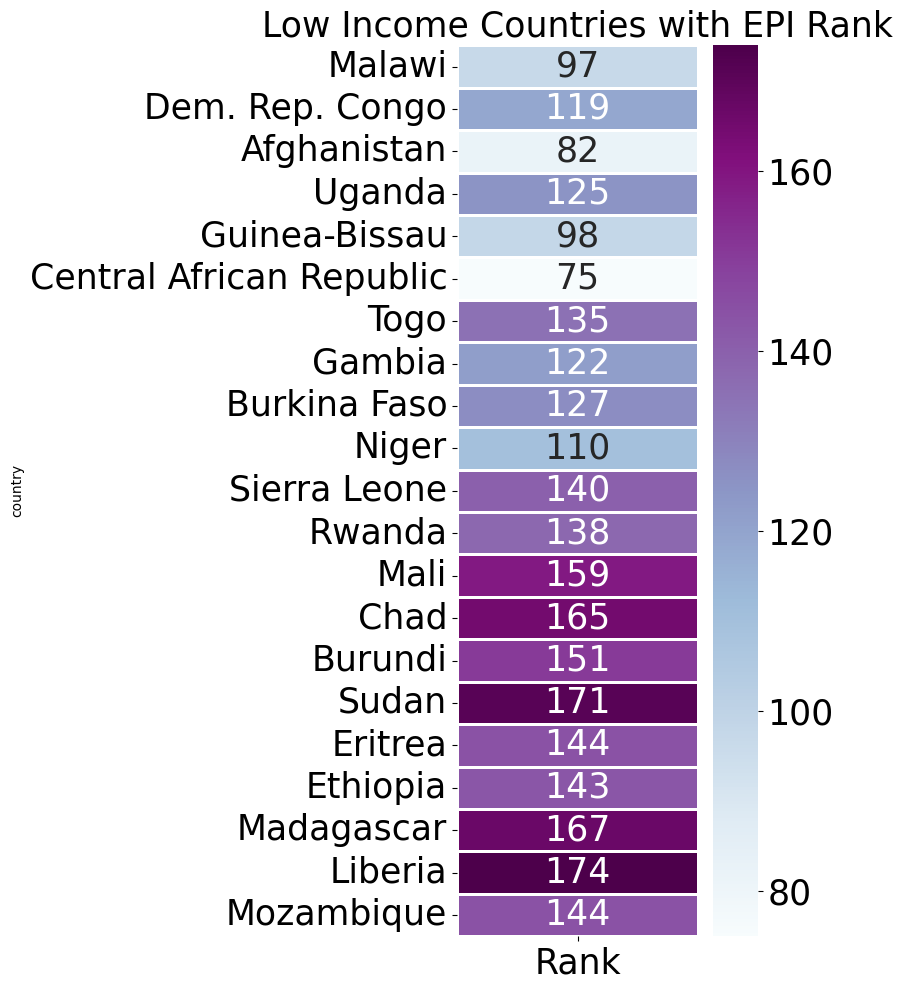

In [26]:
# Low Income Countries for EPI ranks

low_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "Low income"].reset_index()

heatmap_low_income_epi = low_income[['Rank', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_low_income_epinew  = heatmap_low_income_epi.set_index('country')

plt.figure(figsize=(8, 10))
ax = sns.heatmap(heatmap_low_income_epinew, annot=True, cmap='BuPu', fmt='.0f', annot_kws={"size": 25}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=25)
ax.tick_params(axis='y', labelsize=25)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 25
cbar.ax.tick_params(labelsize=25)

# Add a title to the heatmap
plt.title('Low Income Countries with EPI Rank', fontsize=25)
plt.tight_layout()

plt.savefig("heatmap low income epi.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

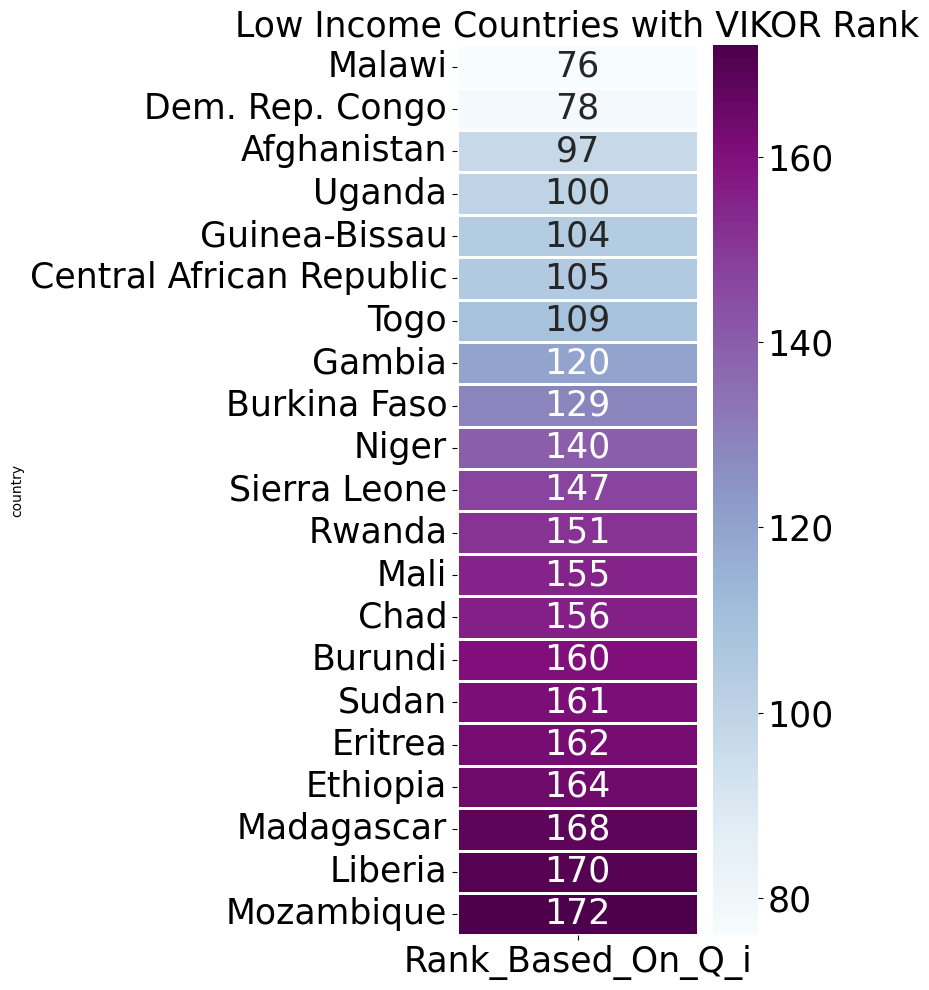

In [27]:
# Low Income Countries for VIKOR ranks

low_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "Low income"].reset_index()

heatmap_low_income_Qi = low_income[['Rank_Based_On_Q_i', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_low_income_Qinew  = heatmap_low_income_Qi.set_index('country')

plt.figure(figsize=(8, 10))
ax = sns.heatmap(heatmap_low_income_Qinew, annot=True, cmap='BuPu', fmt='.0f', annot_kws={"size": 25}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=25)
ax.tick_params(axis='y', labelsize=25)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 25
cbar.ax.tick_params(labelsize=25)

# Add a title to the heatmap
plt.title('Low Income Countries with VIKOR Rank', fontsize=25)
plt.tight_layout()

plt.savefig("heatmap low income vikor.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

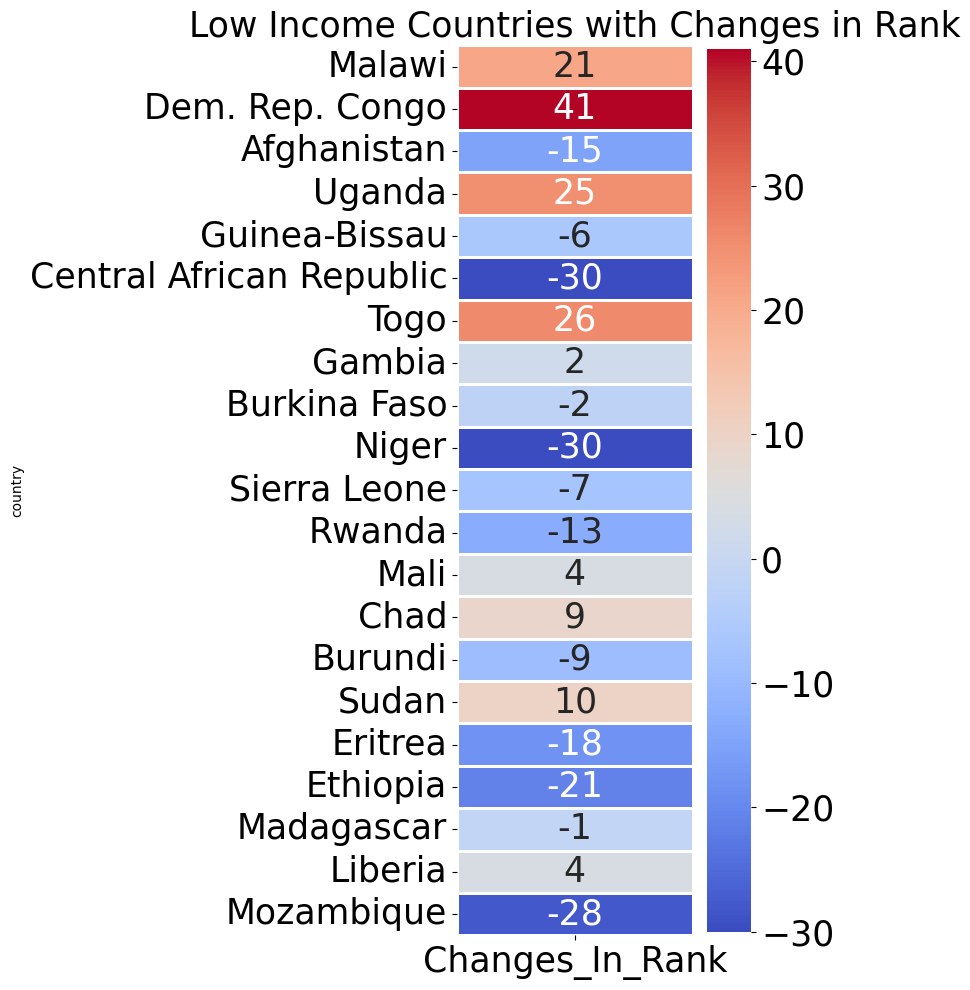

In [28]:
# Low Income Countries for rank changes

low_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "Low income"].reset_index()

heatmap_low_income = low_income[['Changes_In_Rank', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_low_incomenew  = heatmap_low_income.set_index('country')

plt.figure(figsize=(8, 10))
ax = sns.heatmap(heatmap_low_incomenew, annot=True, cmap='coolwarm', annot_kws={"size": 25}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=25)
ax.tick_params(axis='y', labelsize=25)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 25
cbar.ax.tick_params(labelsize=25)

# Add a title to the heatmap
plt.title('Low Income Countries with Changes in Rank', fontsize=25)
plt.tight_layout()

plt.savefig("heatmap low income.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

##### High Income Countries

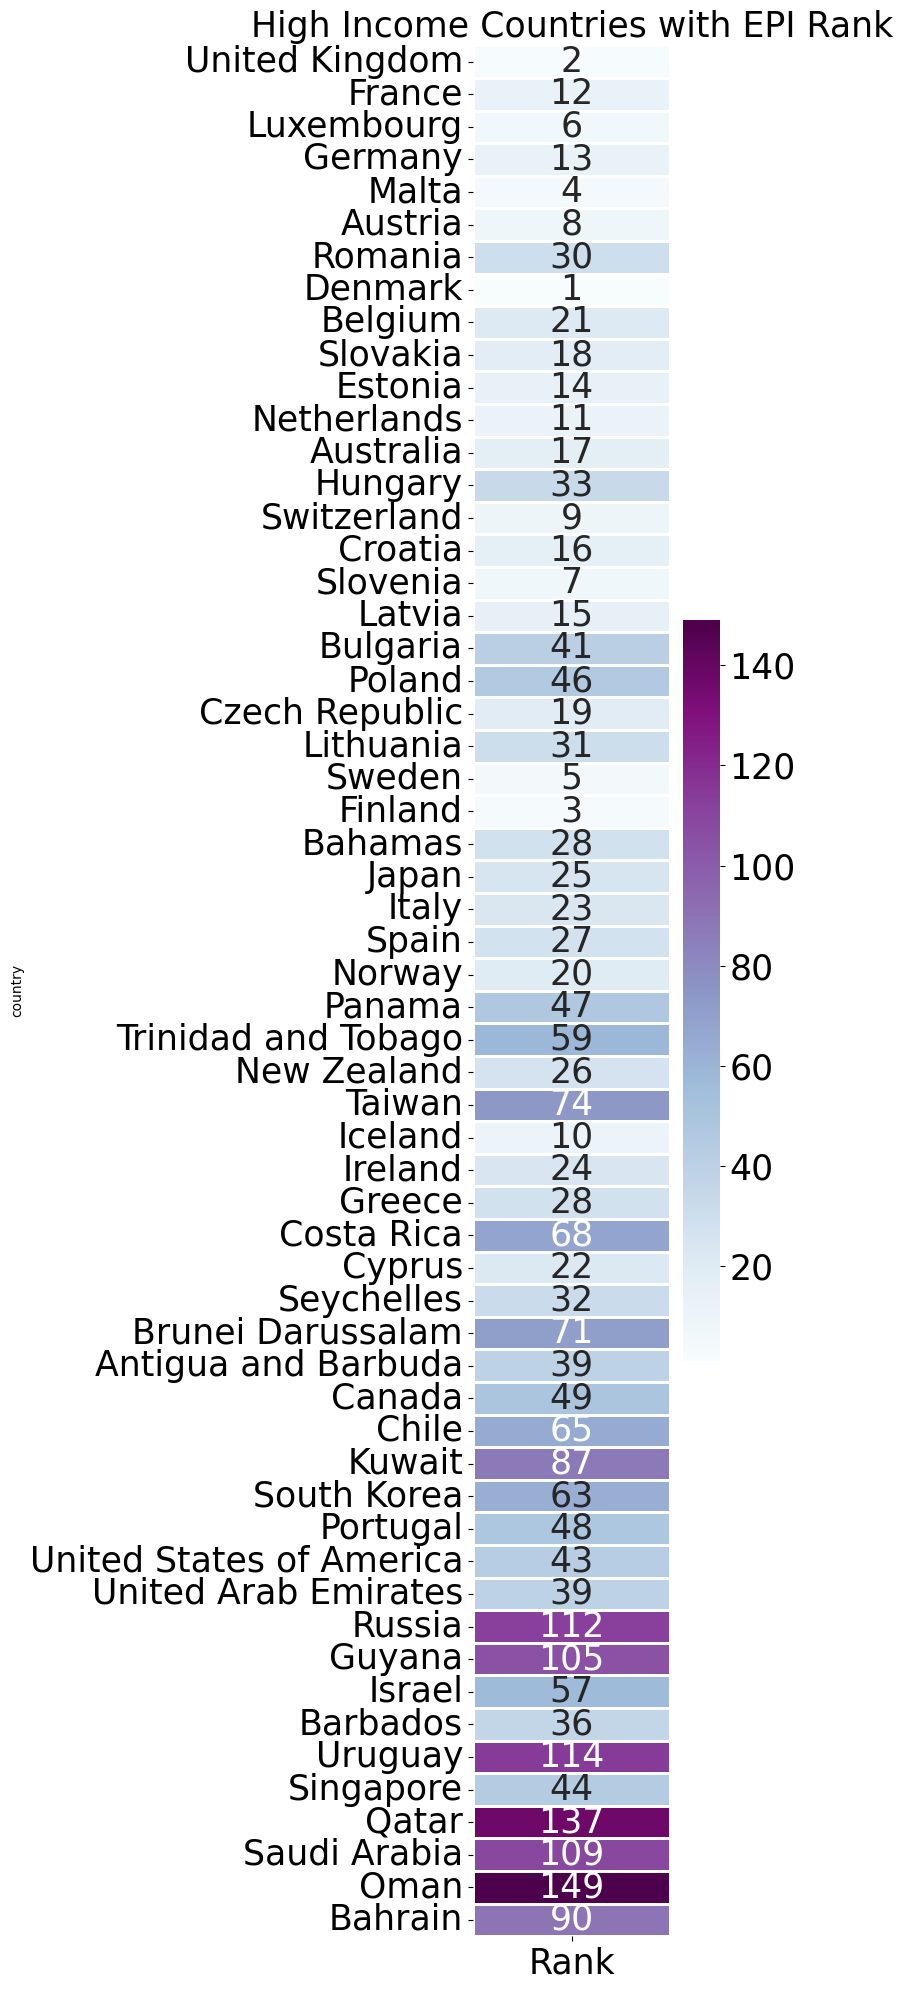

In [29]:
# High Income Countries for EPI ranks

high_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "High income"].reset_index()

heatmap_high_income_epi = high_income[['Rank', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_high_income_epinew  = heatmap_high_income_epi.set_index('country')

plt.figure(figsize=(8, 20))
ax = sns.heatmap(heatmap_high_income_epinew, annot=True, cmap='BuPu', fmt='.0f', annot_kws={"size": 25}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=25)
ax.tick_params(axis='y', labelsize=25)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 25
cbar.ax.tick_params(labelsize=25)

# Add a title to the heatmap
plt.title('High Income Countries with EPI Rank', fontsize=25)
plt.tight_layout()

plt.savefig("heatmap high income epi.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

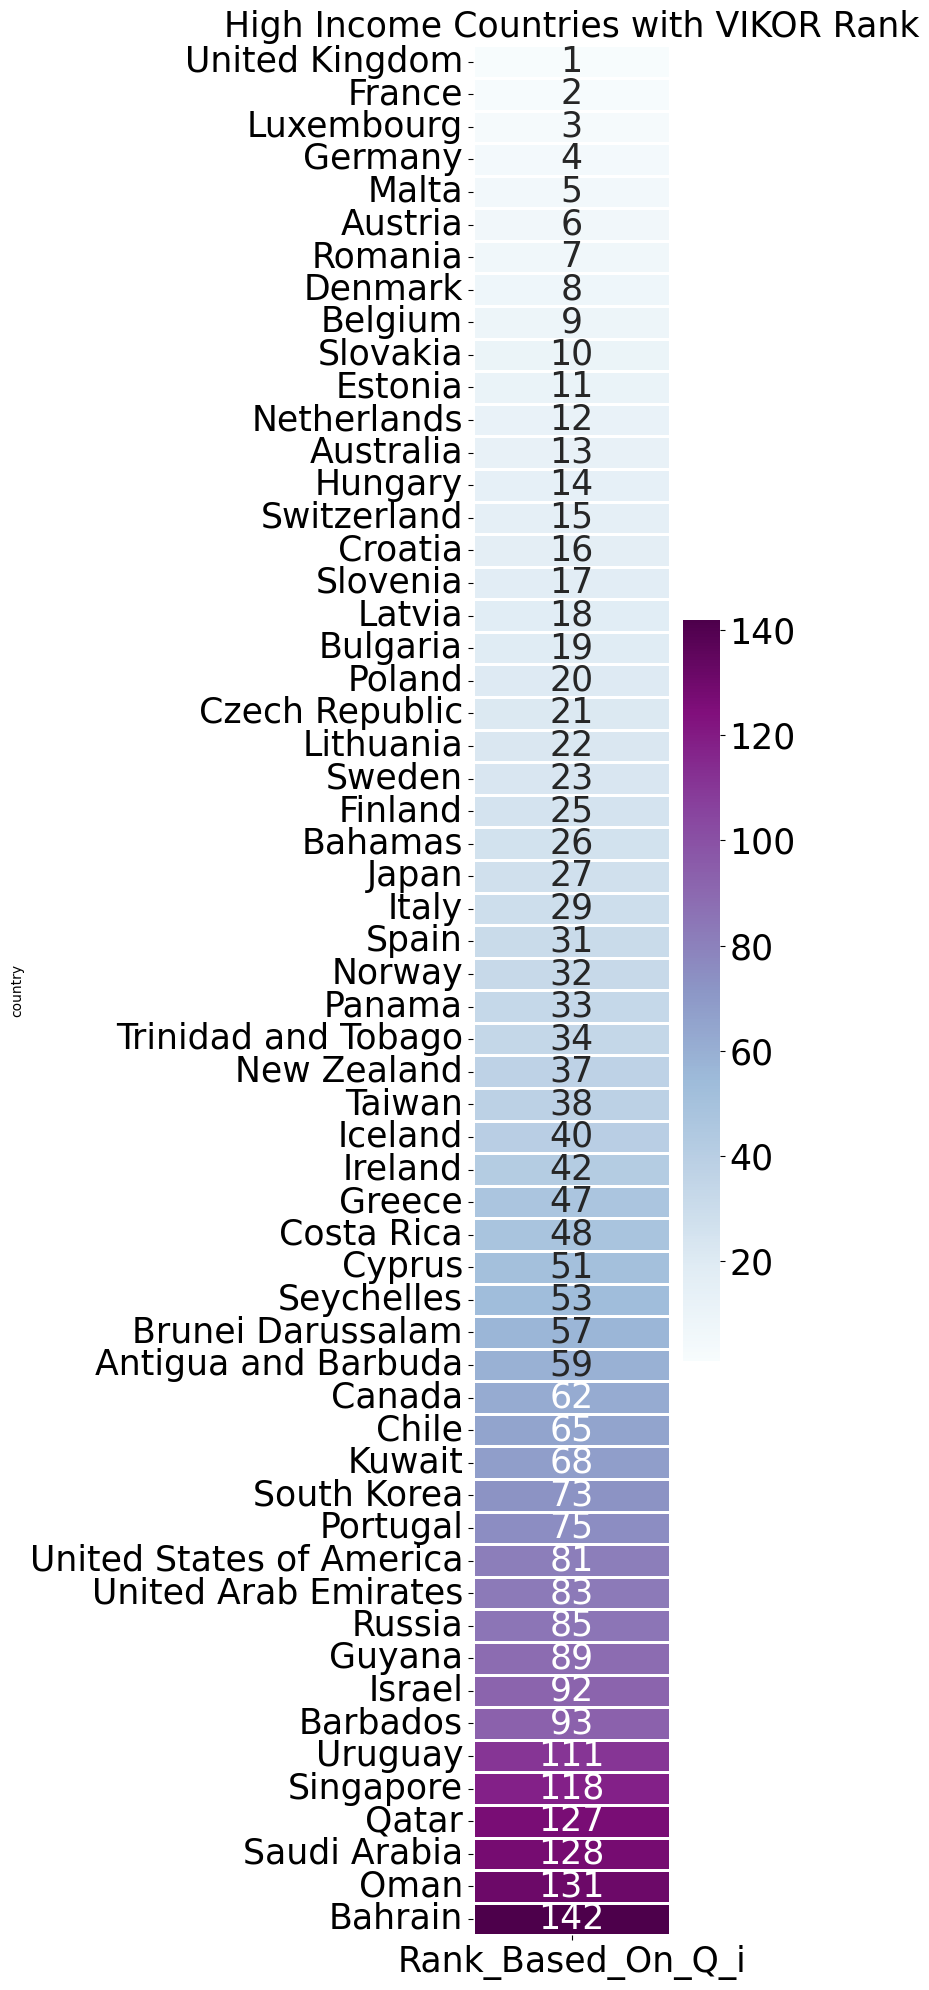

In [30]:
# High Income Countries for VIKOR ranks

high_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "High income"].reset_index()

heatmap_high_income_Qi = high_income[['Rank_Based_On_Q_i', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_high_income_Qinew  = heatmap_high_income_Qi.set_index('country')

plt.figure(figsize=(8, 20))
ax = sns.heatmap(heatmap_high_income_Qinew, annot=True, cmap='BuPu', fmt='.0f', annot_kws={"size": 25}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=25)
ax.tick_params(axis='y', labelsize=25)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 25
cbar.ax.tick_params(labelsize=25)

# Add a title to the heatmap
plt.title('High Income Countries with VIKOR Rank', fontsize=25)
plt.tight_layout()

plt.savefig("heatmap high income vikor.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

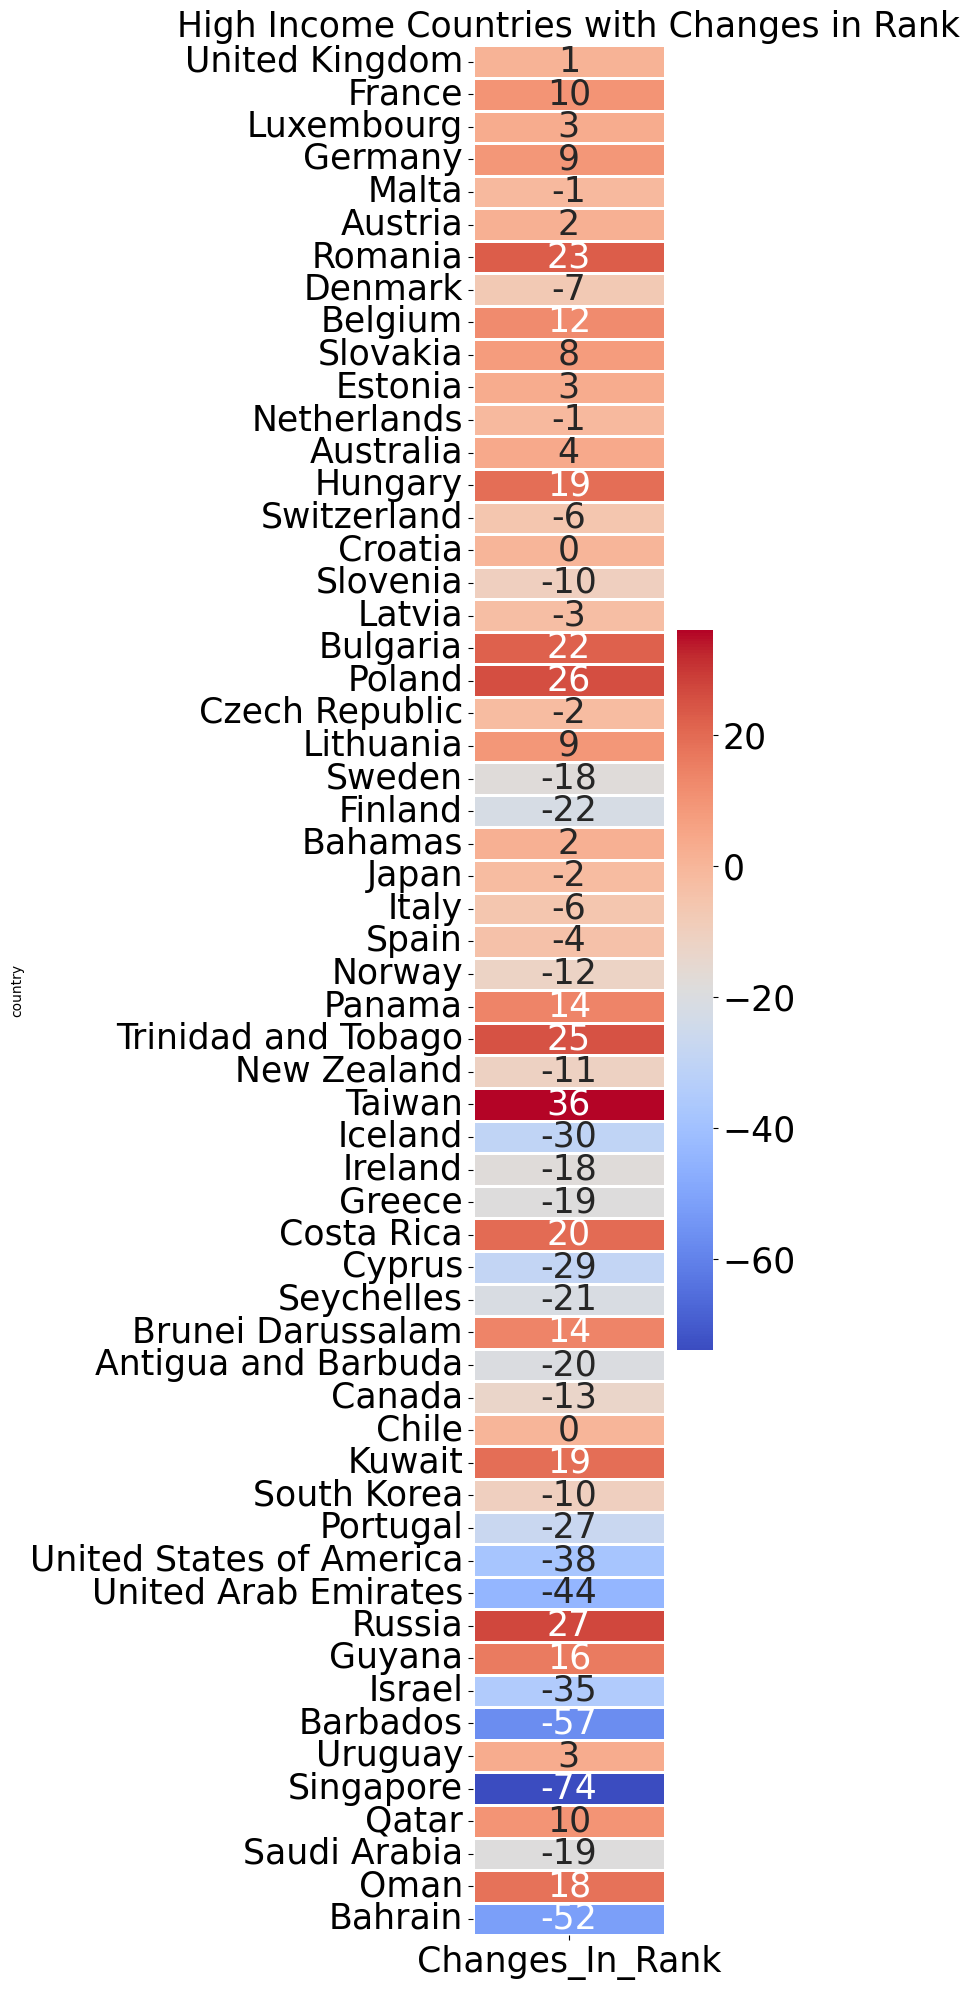

In [31]:
# High Income Countries for rank changes

high_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "High income"].reset_index()

heatmap_high_income = high_income[['Changes_In_Rank', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_high_incomenew  = heatmap_high_income.set_index('country')

plt.figure(figsize=(8, 20))
ax = sns.heatmap(heatmap_high_incomenew, annot=True, cmap='coolwarm', annot_kws={"size": 25}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=25)
ax.tick_params(axis='y', labelsize=25)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 25
cbar.ax.tick_params(labelsize=25)

# Add a title to the heatmap
plt.title('High Income Countries with Changes in Rank', fontsize=25)
plt.tight_layout()

plt.savefig("heatmap high income.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

##### Upper Middle Income Countries

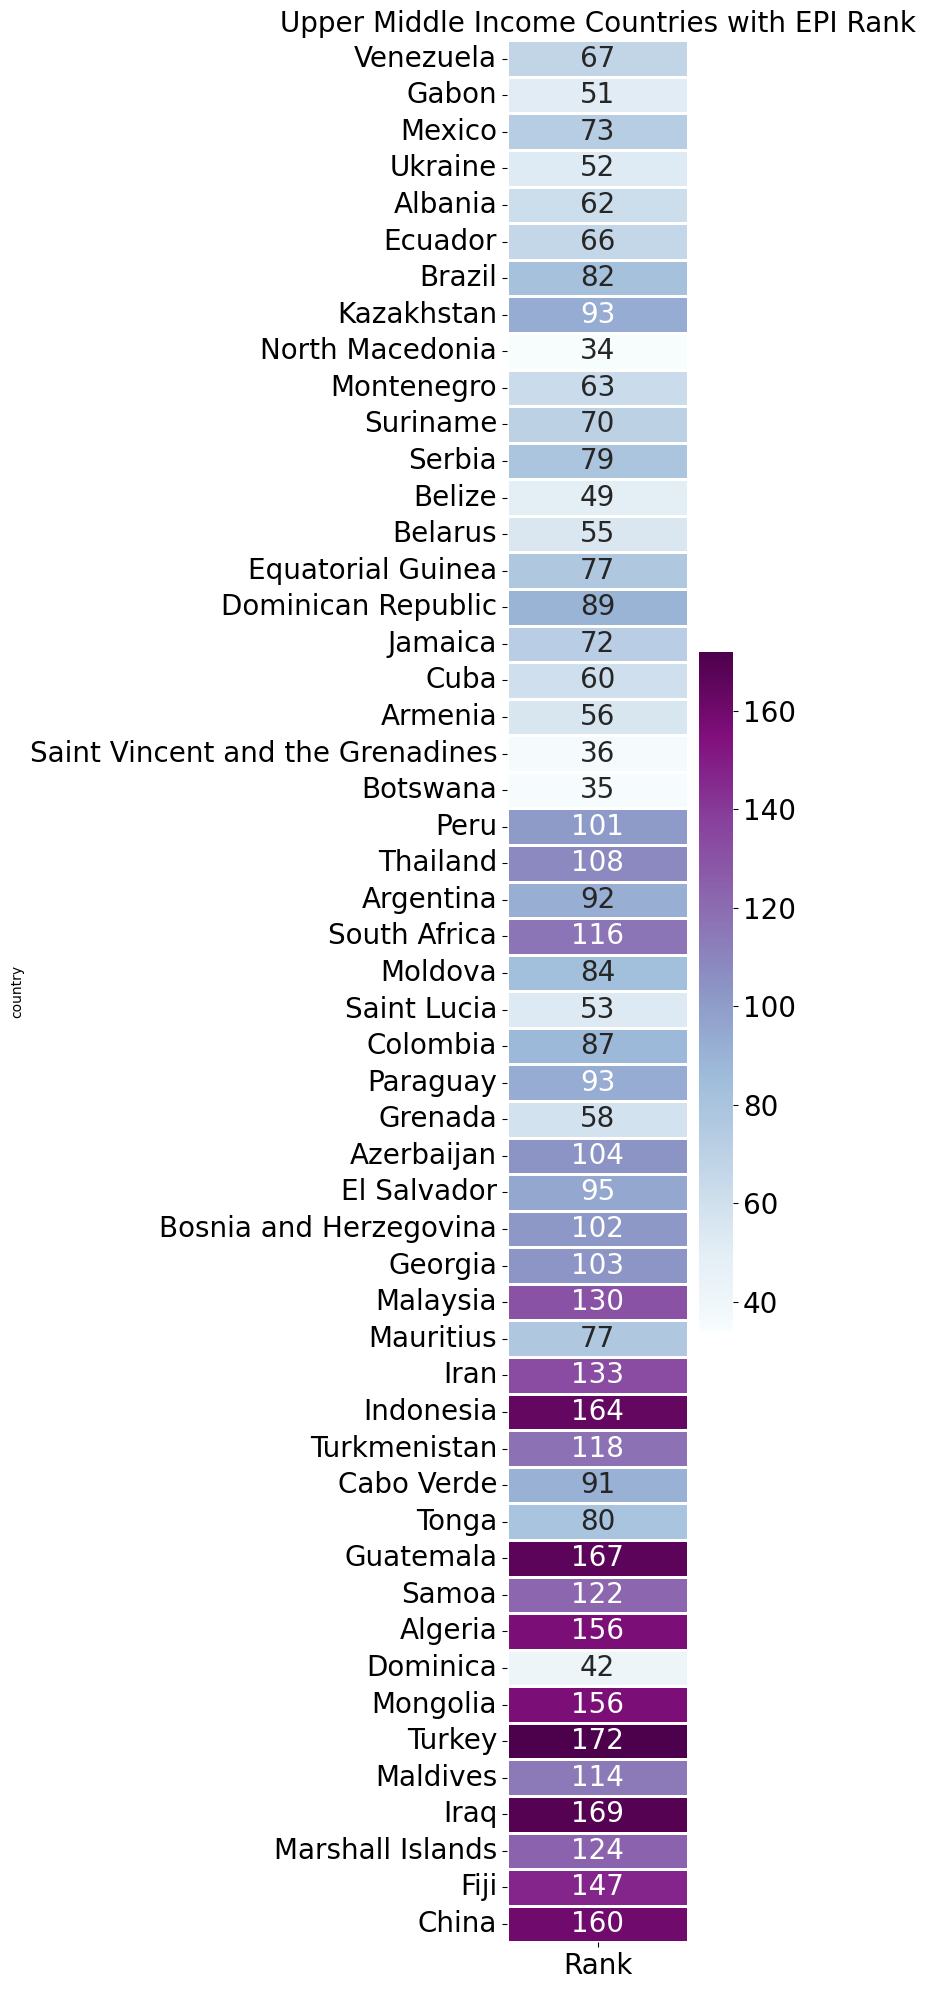

In [32]:
# Upper Middle Income Countries for EPI ranks

upmid_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "Upper middle income"].reset_index()

heatmap_upmid_income_epi = upmid_income[['Rank', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_upmid_income_epinew  = heatmap_upmid_income_epi.set_index('country')

plt.figure(figsize=(8, 20))
ax = sns.heatmap(heatmap_upmid_income_epinew, annot=True, cmap='BuPu', fmt='.0f', annot_kws={"size": 20}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=20)
ax.tick_params(axis='y', labelsize=20)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 20
cbar.ax.tick_params(labelsize=20)

# Add a title to the heatmap
plt.title('Upper Middle Income Countries with EPI Rank', fontsize=20)
plt.tight_layout()

plt.savefig("heatmap upmid income epi.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

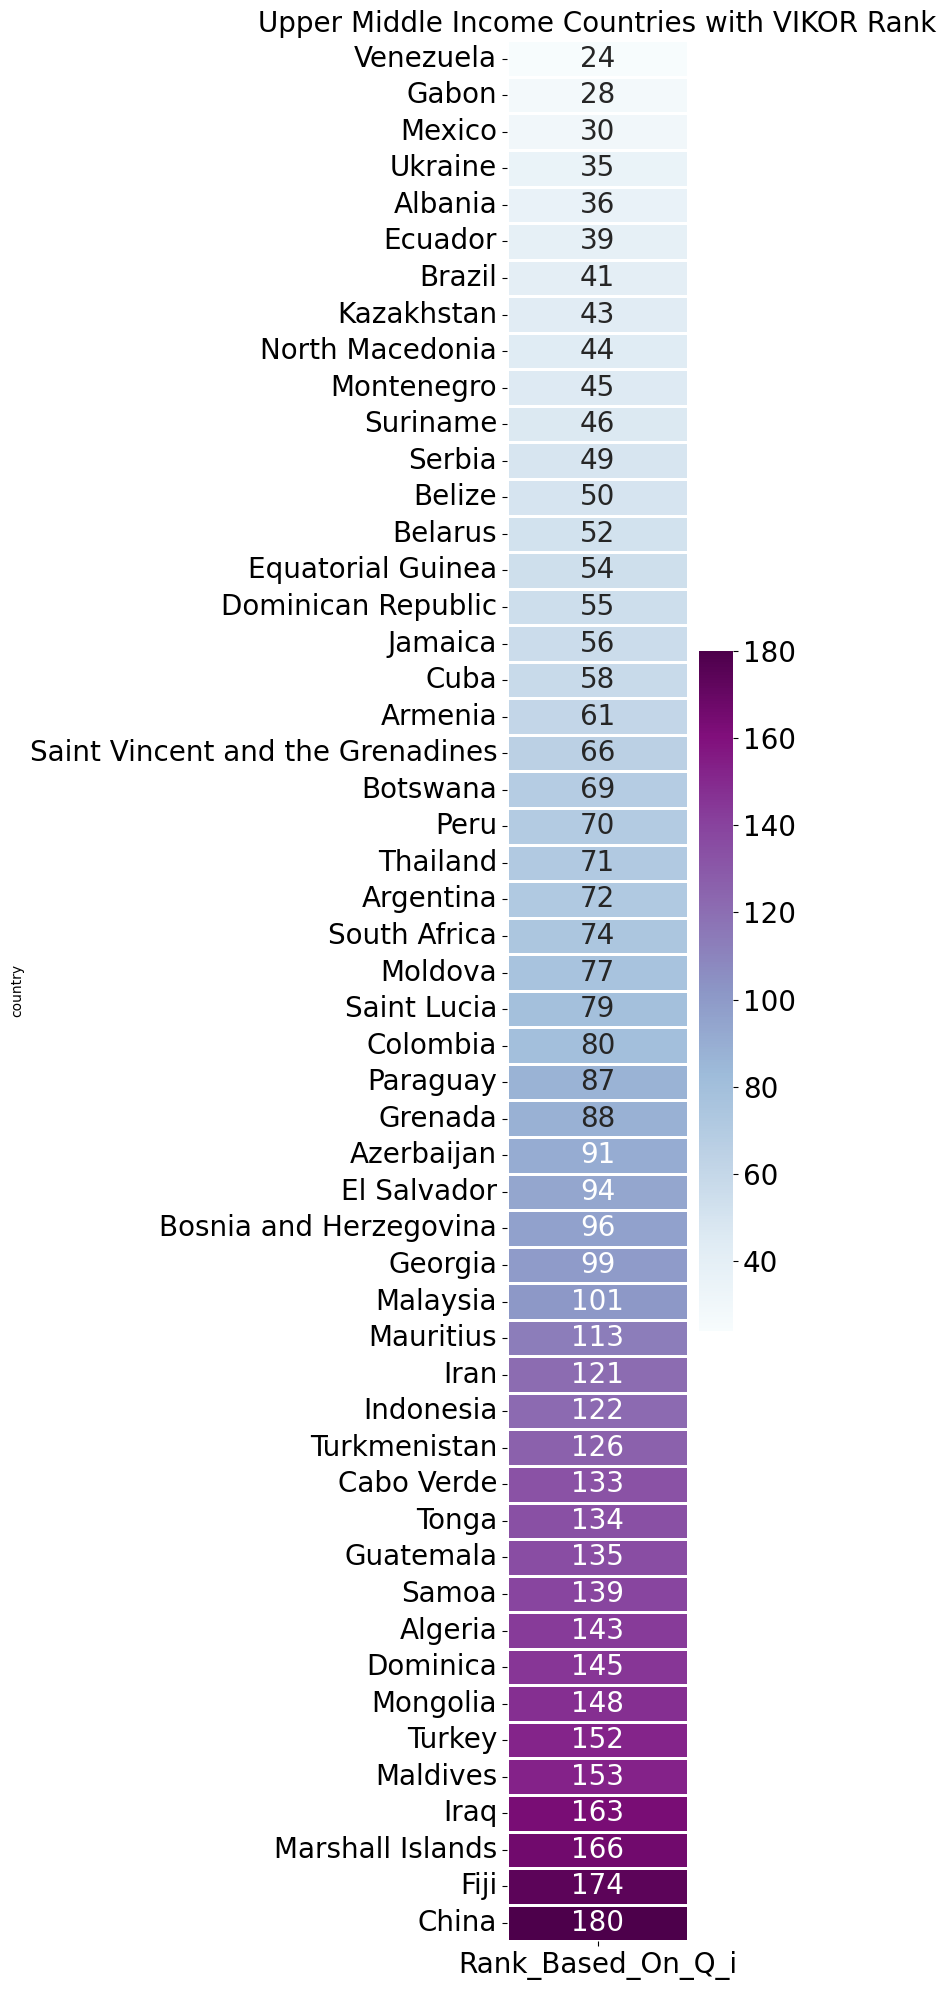

In [33]:
# Upper Middle Income Countries for VIKOR ranks

upmid_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "Upper middle income"].reset_index()

heatmap_upmid_income_Qi = upmid_income[['Rank_Based_On_Q_i', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_upmid_income_Qinew  = heatmap_upmid_income_Qi.set_index('country')

plt.figure(figsize=(8, 20))
ax = sns.heatmap(heatmap_upmid_income_Qinew, annot=True, cmap='BuPu', fmt='.0f', annot_kws={"size": 20}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=20)
ax.tick_params(axis='y', labelsize=20)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 20
cbar.ax.tick_params(labelsize=20)

# Add a title to the heatmap
plt.title('Upper Middle Income Countries with VIKOR Rank', fontsize=20)
plt.tight_layout()

plt.savefig("heatmap upmid income vikor.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

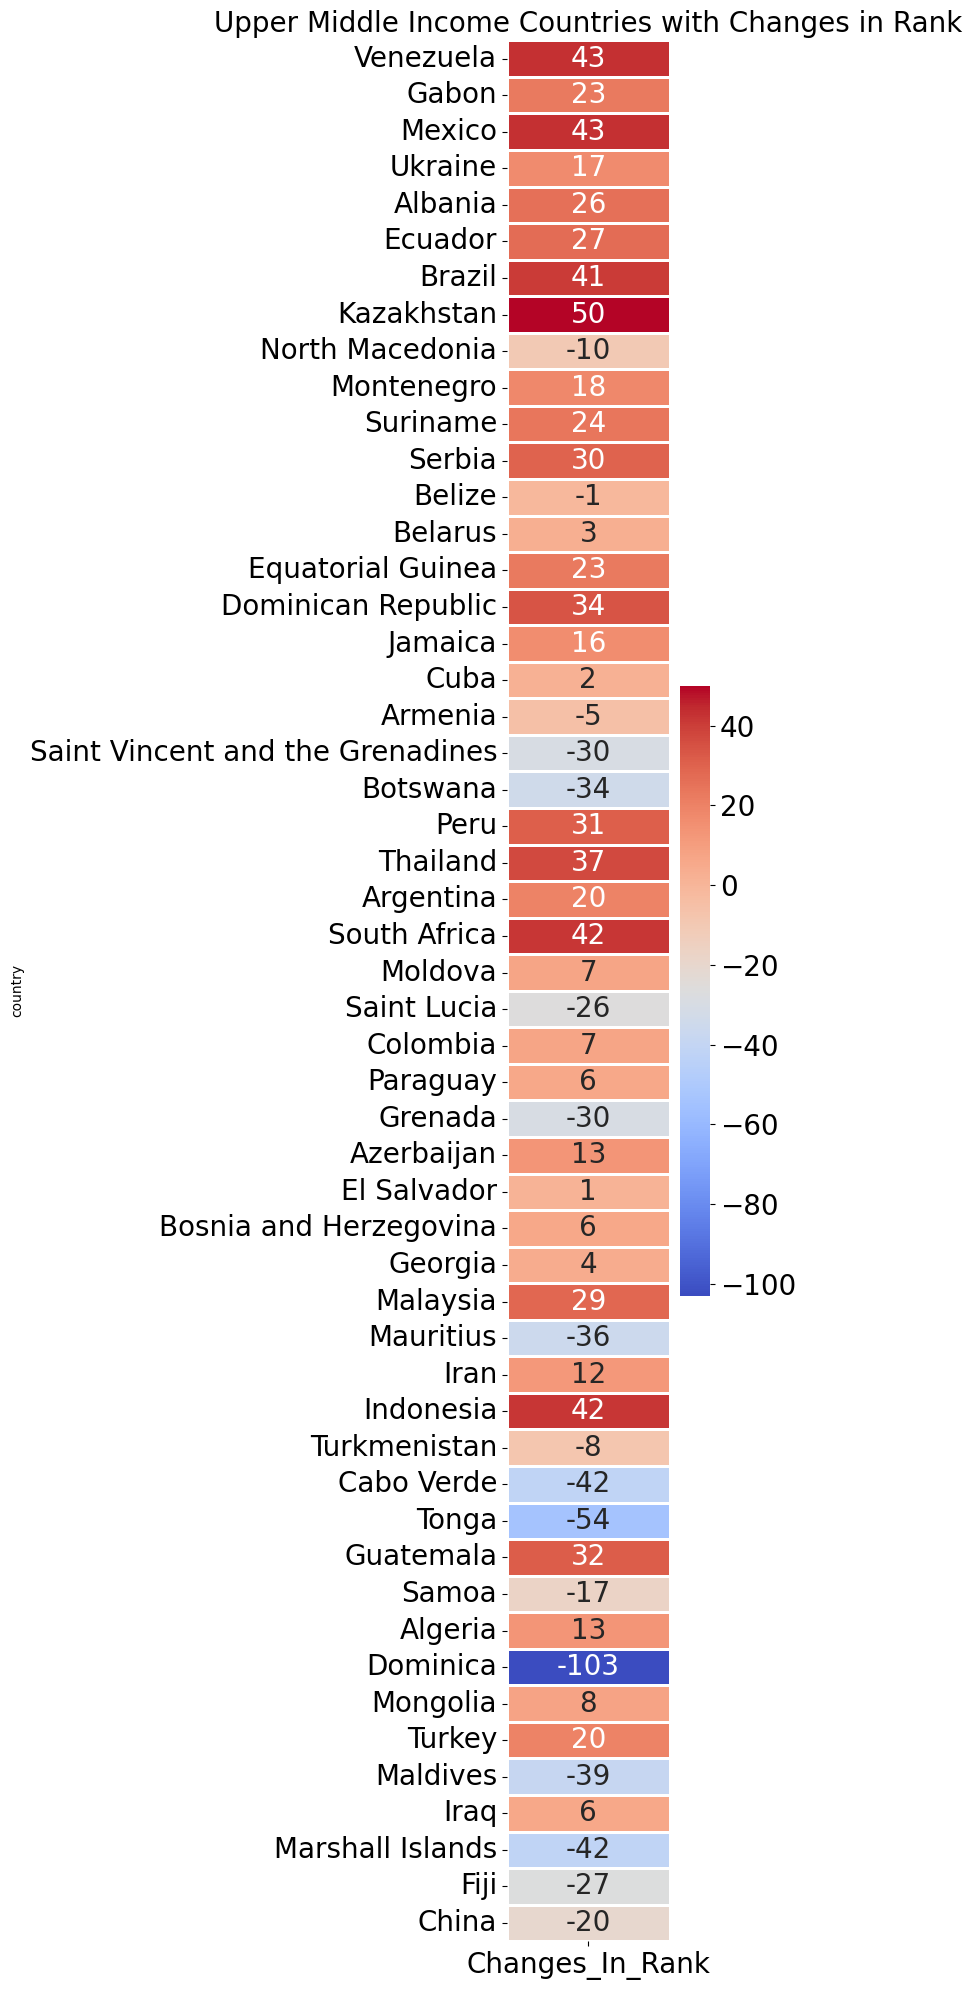

In [34]:
# Upper Middle Income Countries for rank changes

upmid_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "Upper middle income"].reset_index()

heatmap_upmid_income = upmid_income[['Changes_In_Rank', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_upmid_incomenew  = heatmap_upmid_income.set_index('country')

plt.figure(figsize=(8, 20))
ax = sns.heatmap(heatmap_upmid_incomenew, annot=True, cmap='coolwarm', fmt='.0f', annot_kws={"size": 20}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=20)
ax.tick_params(axis='y', labelsize=20)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 20
cbar.ax.tick_params(labelsize=20)

# Add a title to the heatmap
plt.title('Upper Middle Income Countries with Changes in Rank', fontsize=20)
plt.tight_layout()

plt.savefig("heatmap upmid income.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

##### Lower Middle Income Countries

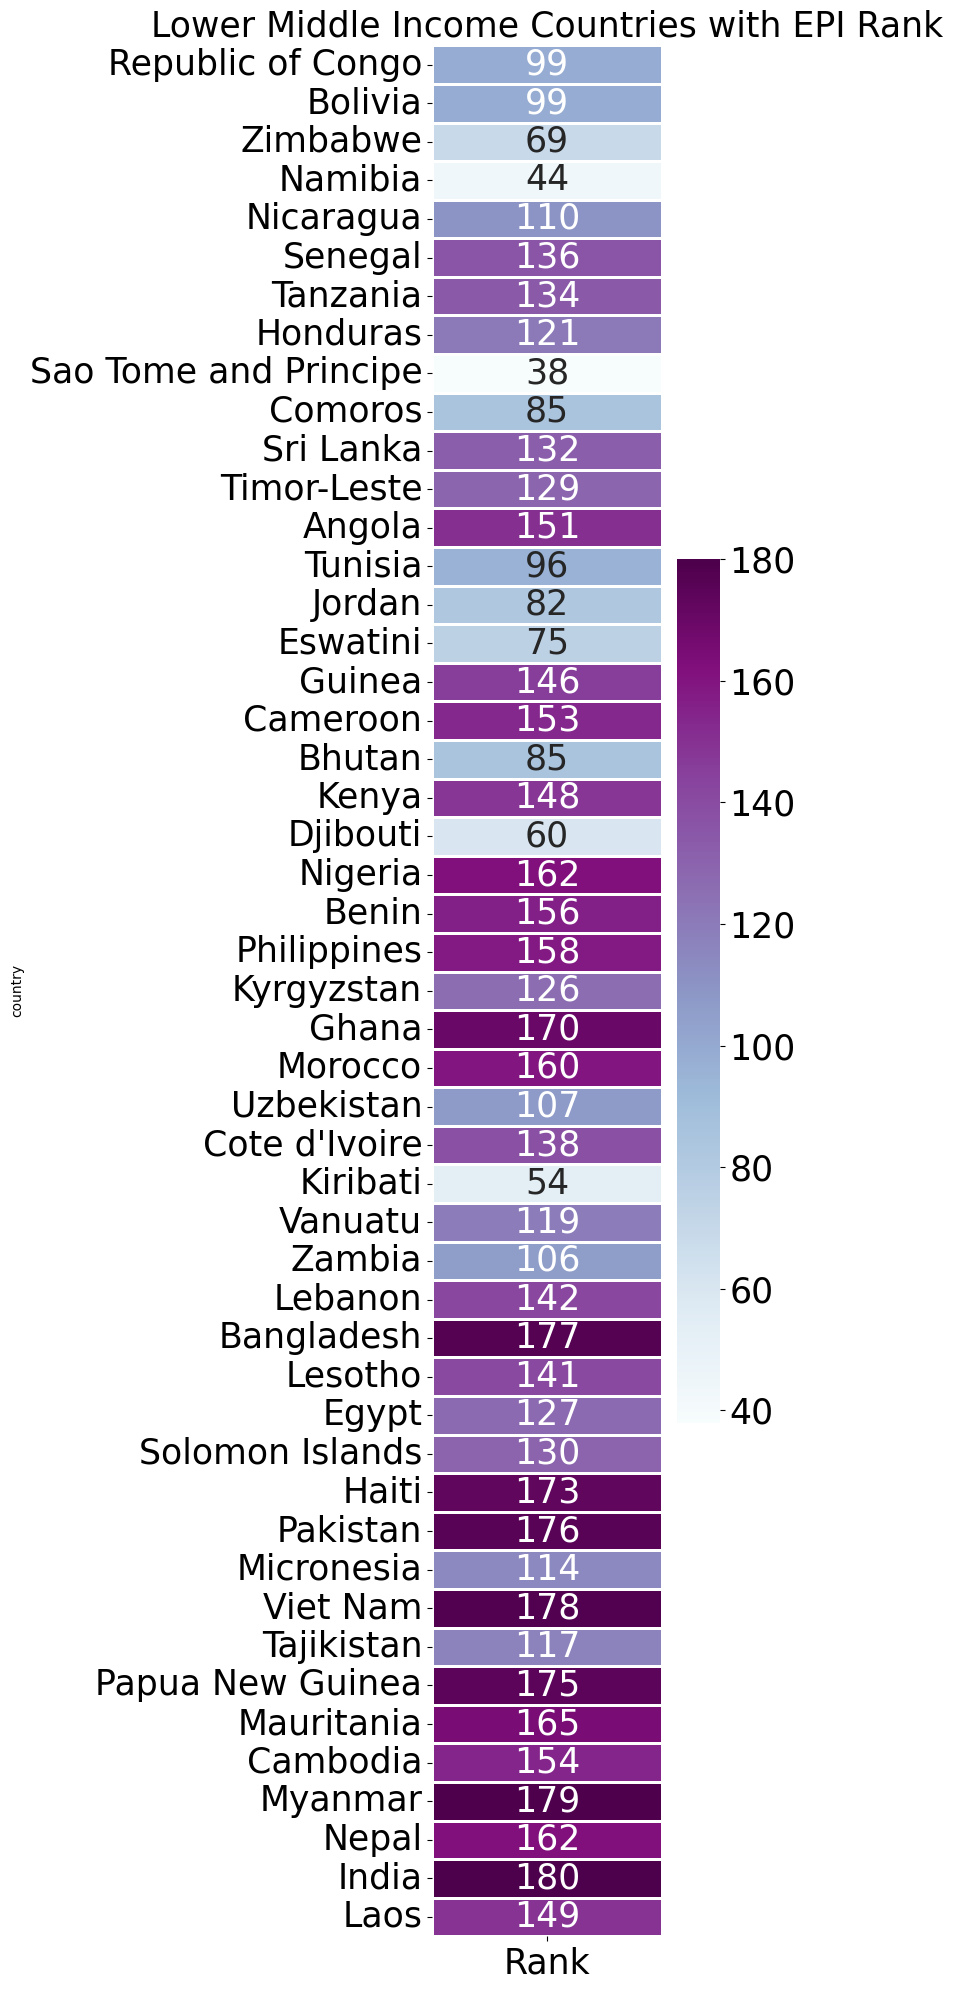

In [35]:
# Lower Middle Income Countries for EPI ranks

lowmid_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "Lower middle income"].reset_index()

heatmap_lowmid_income_epi = lowmid_income[['Rank', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_lowmid_income_epinew  = heatmap_lowmid_income_epi.set_index('country')

plt.figure(figsize=(8, 20))
ax = sns.heatmap(heatmap_lowmid_income_epinew, annot=True, cmap='BuPu', fmt='.0f', annot_kws={"size": 25}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=25)
ax.tick_params(axis='y', labelsize=25)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 25
cbar.ax.tick_params(labelsize=25)

# Add a title to the heatmap
plt.title('Lower Middle Income Countries with EPI Rank', fontsize=25)
plt.tight_layout()

plt.savefig("heatmap lowmid income epi.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

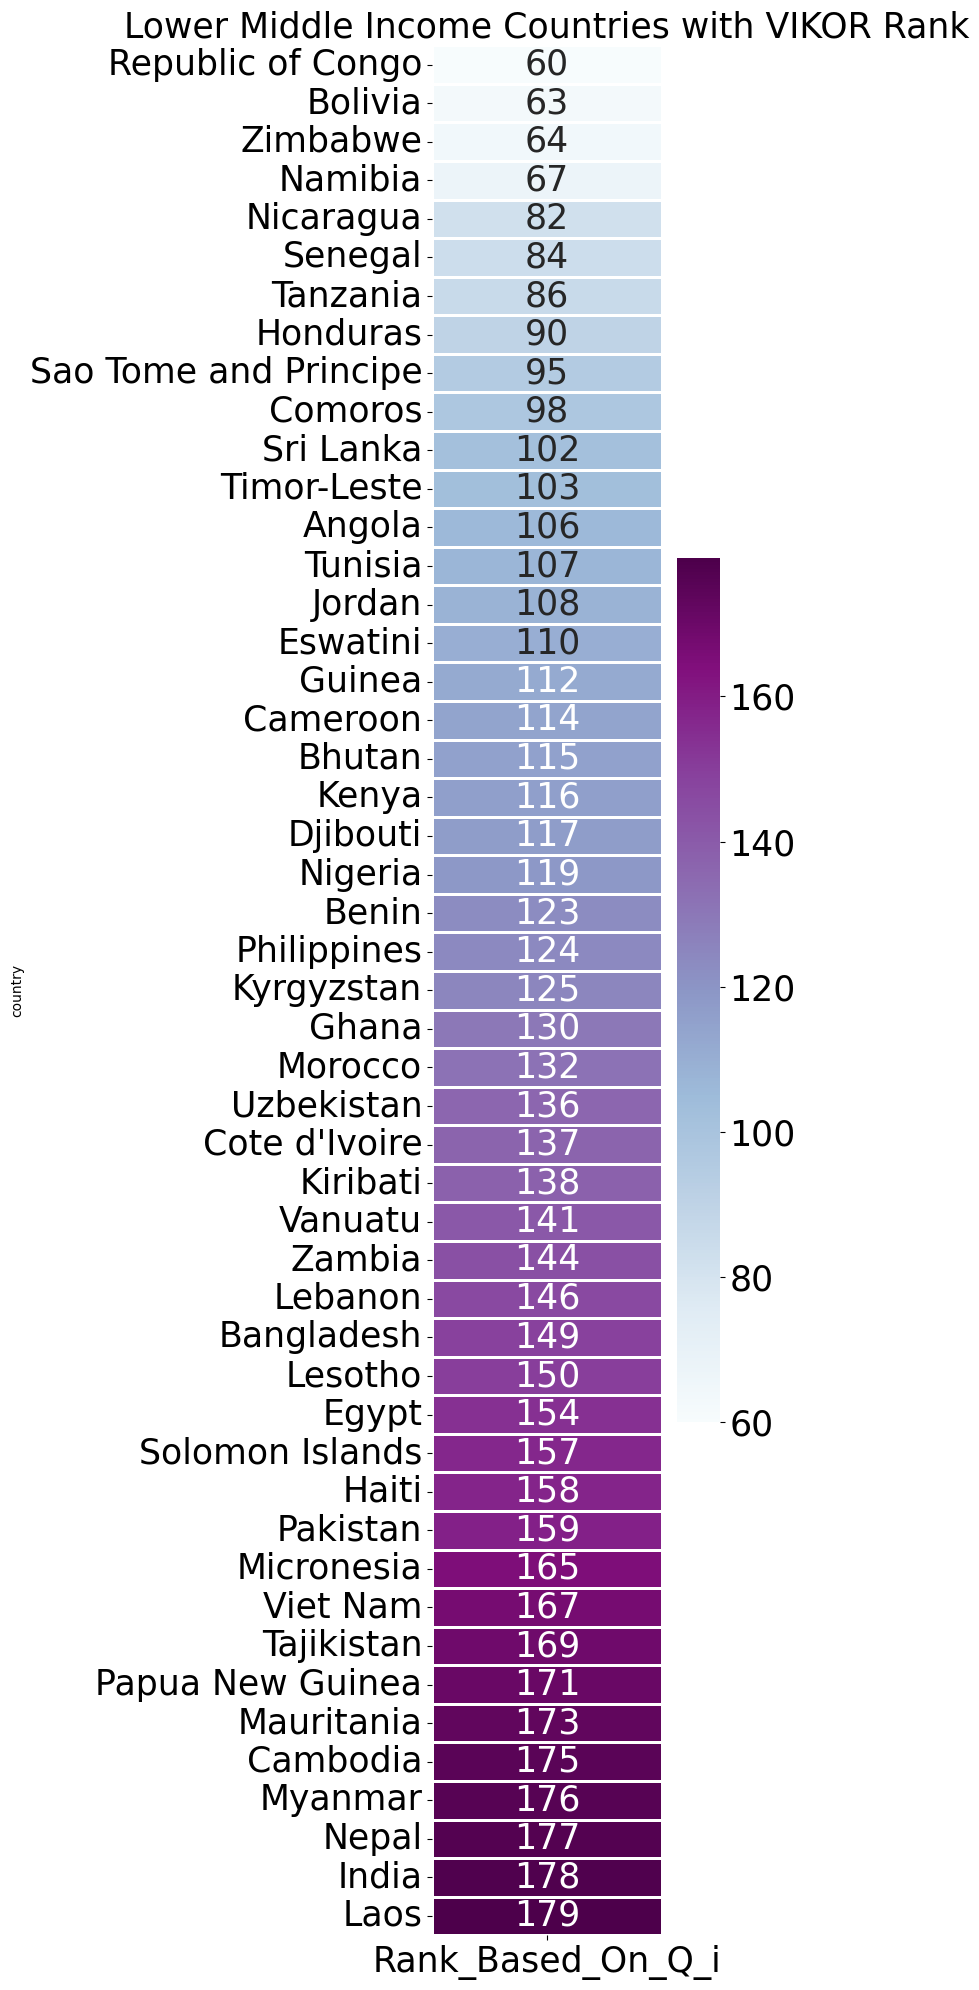

In [36]:
# Lower Middle Income Countries for VIKOR ranks

lowmid_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "Lower middle income"].reset_index()

heatmap_lowmid_income_Qi = lowmid_income[['Rank_Based_On_Q_i', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_lowmid_income_Qinew  = heatmap_lowmid_income_Qi.set_index('country')

plt.figure(figsize=(8, 20))
ax = sns.heatmap(heatmap_lowmid_income_Qinew, annot=True, cmap='BuPu', fmt='.0f', annot_kws={"size": 25}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=25)
ax.tick_params(axis='y', labelsize=25)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 25
cbar.ax.tick_params(labelsize=25)

# Add a title to the heatmap
plt.title('Lower Middle Income Countries with VIKOR Rank', fontsize=25)
plt.tight_layout()

plt.savefig("heatmap lowmid income vikor.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

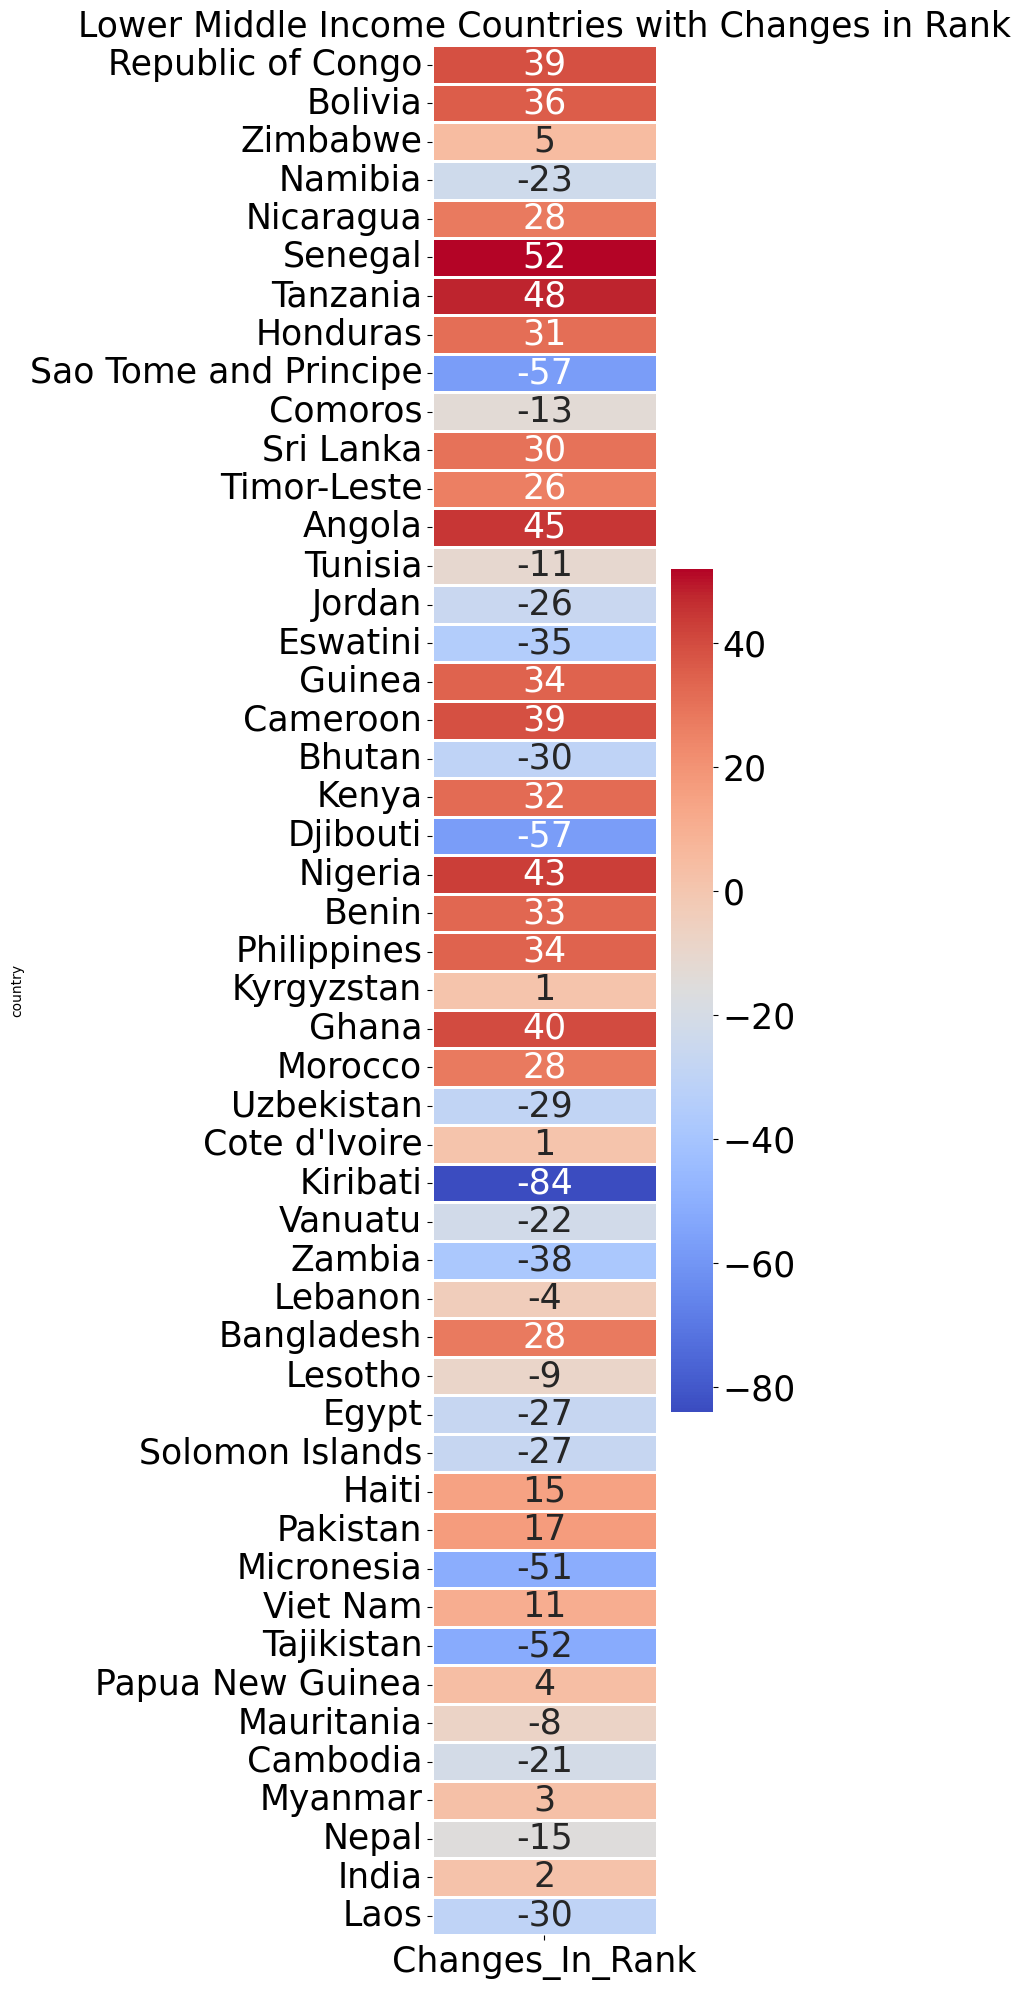

In [37]:
# Lower Middle Income Countries for rank changes

lowmid_income = result_concat_indexed[result_concat_indexed['IncomeGroup'] == "Lower middle income"].reset_index()

heatmap_lowmid_income = lowmid_income[['Changes_In_Rank', 'country']]

# Since heatmap expects matrix, convert to suitable format
heatmap_lowmid_incomenew  = heatmap_lowmid_income.set_index('country')

plt.figure(figsize=(8, 20))
ax = sns.heatmap(heatmap_lowmid_incomenew, annot=True, cmap='coolwarm', fmt='.0f', annot_kws={"size": 25}, linewidths=0.8)

# Increase x and y axis tick label font size
ax.tick_params(axis='x', labelsize=25)
ax.tick_params(axis='y', labelsize=25)

# use matplotlib.colorbar.Colorbar object
cbar = ax.collections[0].colorbar
# here set the labelsize by 25
cbar.ax.tick_params(labelsize=25)

# Add a title to the heatmap
plt.title('Lower Middle Income Countries with Changes in Rank', fontsize=25)
plt.tight_layout()

plt.savefig("heatmap lowmid income.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

## Diagnostic plots for Bias Amplification.

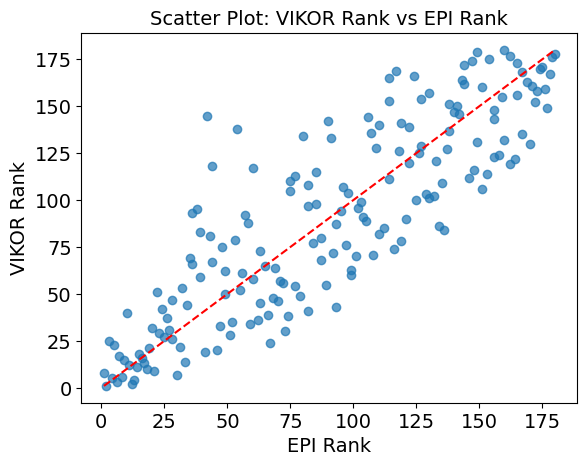

In [38]:
import matplotlib.pyplot as plt

plt.scatter(compare_Qi_Rank_MF50_reset['Rank'], compare_Qi_Rank_MF50_reset['Rank_Based_On_Q_i'], alpha=0.7)
plt.plot([min(compare_Qi_Rank_MF50_reset['Rank']), max(compare_Qi_Rank_MF50_reset['Rank'])], [min(compare_Qi_Rank_MF50_reset['Rank']), max(compare_Qi_Rank_MF50_reset['Rank'])], 'r--')
plt.xlabel('EPI Rank', fontsize=14)
plt.ylabel('VIKOR Rank', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('Scatter Plot: VIKOR Rank vs EPI Rank', fontsize=14)
plt.savefig("Scatter Plot VIKOR Rank vs EPI Rank.jpg", dpi=400)  # dpi (dots per inch) controls resolution
plt.show()

In [39]:
from scipy.stats import pearsonr

# Calculate Pearson correlation coefficient
corr_coef, p_value = pearsonr(compare_Qi_Rank_MF50_reset['Rank'], compare_Qi_Rank_MF50_reset['Rank_Based_On_Q_i'])
print(corr_coef)
print(p_value)

0.857806485847463
2.450259819689848e-53


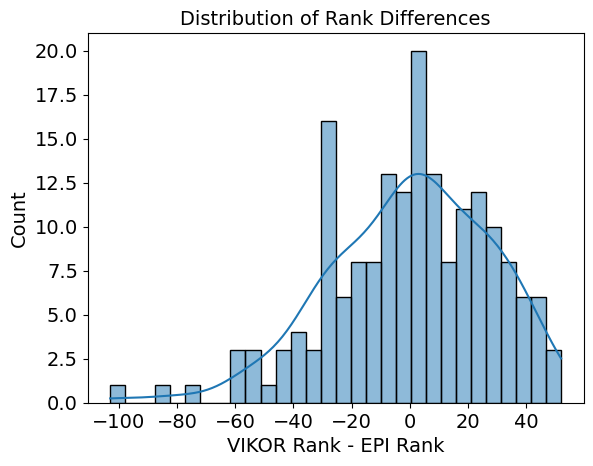

In [40]:
sns.histplot(compare_Qi_Rank_MF50_reset['Changes_In_Rank'], bins=30, kde=True)
plt.title('Distribution of Rank Differences', fontsize=14)
plt.xlabel('VIKOR Rank - EPI Rank', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.savefig("Distribution of Rank Differences VIKOR Rank vs EPI Rank.jpg", dpi=400)  # dpi (dots per inch) controls resolution
plt.show()

In [41]:
from scipy.stats import skew

# Calculate skewness of difference between EPI and VIKOR ranks
difference = compare_Qi_Rank_MF50_reset['Rank'] - compare_Qi_Rank_MF50_reset['Rank_Based_On_Q_i']
skewness_value = skew(difference)

print("Skewness of EPI rank minus VIKOR rank:", skewness_value)
if skewness_value < 0:
    print("This indicates a left skew in the difference distribution.")
else:
    print("This is not left skewed.")

Skewness of EPI rank minus VIKOR rank: -0.5743492151053488
This indicates a left skew in the difference distribution.


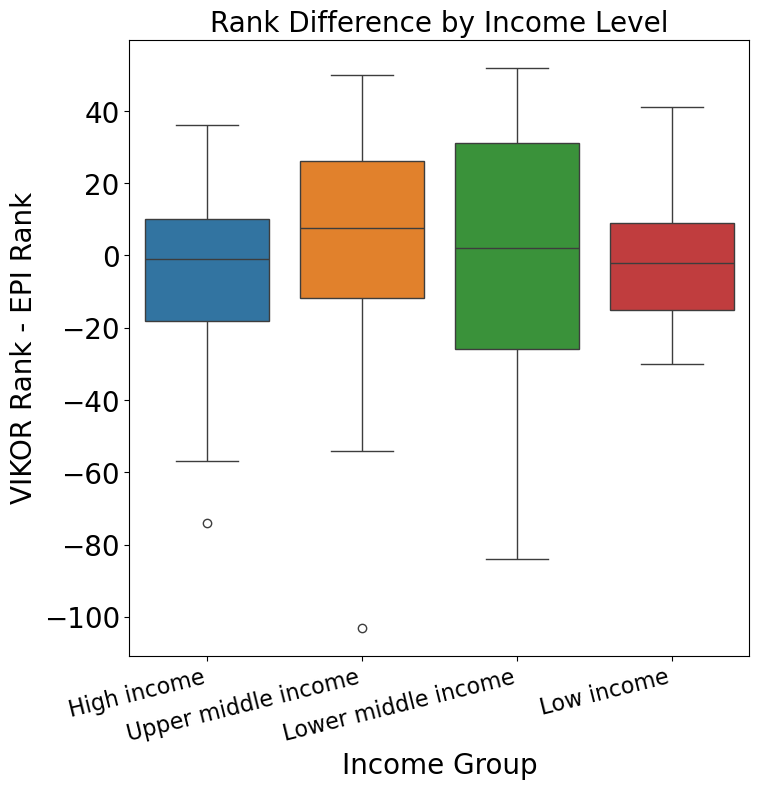

In [42]:
#adjust the hex codes to match your old plot
palette_income = {
    'High income': '#1f77b4',            # blue
    'Upper middle income': '#ff7f0e',    # orange
    'Lower middle income': '#2ca02c',    # green
    'Low income': '#d62728'              # red
}

plt.figure(figsize=(8, 8))
sns.boxplot(x='IncomeGroup', 
            y='Changes_In_Rank', 
            hue='IncomeGroup',          # redundant hue
            data=result_concat_indexed, palette=palette_income,
           legend=False                # or use legend=False via plt.legend_.remove()
           )
plt.title('Rank Difference by Income Level', fontsize=20)
plt.xticks(rotation=14, ha='right',fontsize=16)
plt.yticks(fontsize=20)
plt.xlabel('Income Group', fontsize=20)
plt.ylabel('VIKOR Rank - EPI Rank', fontsize=20)
plt.savefig("Boxplot Rank Difference by Income Level.jpg", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

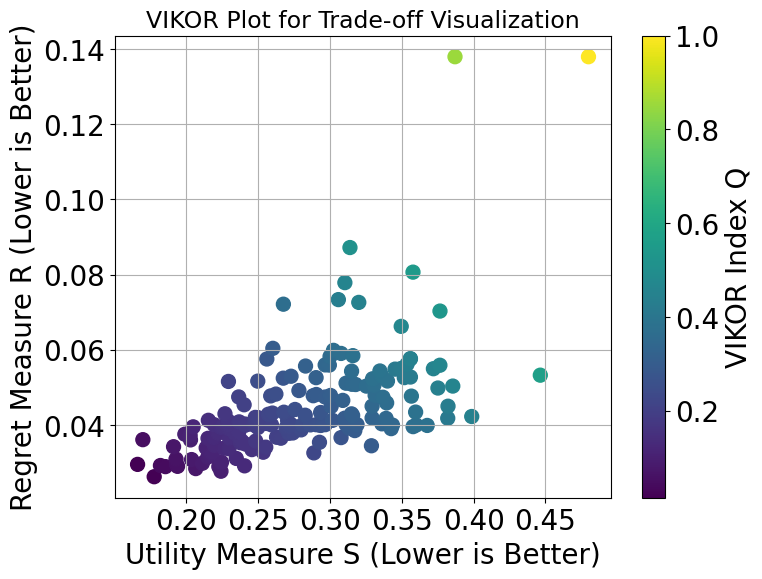

In [43]:
# Plot VIKOR utility vs regret
plt.figure(figsize=(8,6))
plt.scatter(compare_Qi_Rank_MF50_reset['S_i'], compare_Qi_Rank_MF50_reset['R_i'], c=compare_Qi_Rank_MF50_reset['Q_i'], cmap='viridis', s=100)

cbar = plt.colorbar()
plt.xlabel('Utility Measure S (Lower is Better)', fontsize=20)
plt.ylabel('Regret Measure R (Lower is Better)', fontsize=20)
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.title('VIKOR Plot for Trade-off Visualization', fontsize=17)
cbar.ax.tick_params(labelsize=20)
cbar.set_label('VIKOR Index Q', fontsize=20)
plt.grid(True)

plt.savefig("VIKOR Plot for Trade-off Visualization", dpi=400, bbox_inches='tight')  # dpi (dots per inch) controls resolution
plt.show()

# 6. Rank-change diagnostics and sensitivity analysis

Sensitivity analysis is essential for evaluating the reliability and consistency of the VIKOR method in EPI assessments. The variations in the parameter $v$ and the weights of the criteria influence the ranking results were examined. 

##### The variations in the parameter $v$.

In [44]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, wilcoxon

v_values = np.arange(0.1, 1.0, 0.1)  # 0.1 to 0.9

results = []  # to collect rows for the summary table

for v in v_values:
    v_df = vikor_epi_MF50.copy()

    # Compute Q_i for this v
    S_norm = (v_df['S_i'] - v_df['S_i'].min()) / (v_df['S_i'].max() - v_df['S_i'].min())
    R_norm = (v_df['R_i'] - v_df['R_i'].min()) / (v_df['R_i'].max() - v_df['R_i'].min())
    v_df['Q_i'] = v * S_norm + (1 - v) * R_norm

    # Rank based on Q_i
    vikor_Qi = v_df[['S_i', 'R_i', 'Q_i']].copy()
    vikor_Qi['Rank_Based_On_Q_i'] = vikor_Qi['Q_i'].rank().astype(int)

    # Align with EPI ranks (same as you did)
    compare_Qi_tmp = compare_Qi.copy()
    compare_Qi_tmp['Rank'] = compare_Qi_tmp['EPI.new'].rank(ascending=False).astype(int)
    compare_Qi_rank = compare_Qi_tmp.sort_values("Rank")

    merged = pd.concat([vikor_Qi, compare_Qi_rank], axis=1).sort_values("Rank_Based_On_Q_i")

    # Spearman correlation for this v
    rho, p_spear = spearmanr(merged['Rank'], merged['Rank_Based_On_Q_i'])

    # Wilcoxon for this v
    merged['rank_diffs'] = merged['Rank_Based_On_Q_i'] - merged['Rank']
    # You may want zero_method='wilcox' if there are many ties
    W_stat, p_wilcox = wilcoxon(merged['rank_diffs'])

    # Store results
    results.append({
        'v': v,
        'Spearman_rho': rho,
        'Spearman_p': p_spear,
        'Wilcoxon_W': W_stat,
        'Wilcoxon_p': p_wilcox
    })

# Convert to table
results_df = pd.DataFrame(results)
print(results_df)

        v  Spearman_rho  Spearman_p  Wilcoxon_W  Wilcoxon_p
0 0.10000       0.81920     0.00000  7506.50000     0.67747
1 0.20000       0.84125     0.00000  7377.00000     0.63030
2 0.30000       0.85243     0.00000  7574.00000     0.65765
3 0.40000       0.85849     0.00000  7559.50000     0.64235
4 0.50000       0.85818     0.00000  7617.50000     0.61318
5 0.60000       0.85325     0.00000  7538.50000     0.62048
6 0.70000       0.84714     0.00000  7709.00000     0.61817
7 0.80000       0.84087     0.00000  7469.00000     0.55051
8 0.90000       0.83154     0.00000  7505.50000     0.50398


The result presents a comparison of Spearman's rank correlation (rho), $ρ$ values and Wilcoxon signed-rank test statistics, including their corresponding $p$-values for all $v$ values tested within the range of 0.1 to 0.9. This finding reveals that Spearman's rho,  $ρ$ remained consistently high across all tested $v$ values, above 0.8, with each associated $p$-value being less than 0.001. This suggests a strong and highly significant monotonic relationship between the two rankings being compared across parameter $v$. The highest Spearman's rho was observed at $v$ = 0.5, which was the parameter primarily utilized in this study, indicating the closest alignment between the original EPI ranks and VIKOR ranks. In addition, the Wilcoxon signed-rank test statistics indicated large positive rank-sum values; however, the corresponding two-sided p-values are all substantial, significantly exceeding conventional $α$ levels. This finding implies that the Wilcoxon test does not reject the null hypothesis, suggesting no systematic difference between the EPI ranks and VIKOR ranks for any tested $v$ values.

##### The variations in the weights of the criteria.

To run sensitivity analysis on 40 original criterion weights from an expert, you typically want to systematically perturb those weights (while preserving any constraints like sum‑to‑1). Then re‑run VIKOR model to see how rankings change. 

Math for generating “new” weight sets by perturbing the original weights in a controlled way. For this study, we will be using additive perturbation ($±Δ$ then renormalize) which means it will adding a small random or symmetric change to each weight (e.g., $±20%$), then scale back to sum‑to‑1.

Below is a Python‑oriented math setup you can adapt.

In [45]:
w0 = np.array(df['combined_weight'])  # 40 original weights from expert
w0

array([0.13794  , 0.13794  , 0.03306  , 0.01482  , 0.01482  , 0.01406  ,
       0.00988  , 0.00988  , 0.00684  , 0.0517   , 0.0418   , 0.0055   ,
       0.0055   , 0.0022   , 0.0022   , 0.0022   , 0.03     , 0.02     ,
       0.02     , 0.01     , 0.005    , 0.005    , 0.0400932, 0.0400932,
       0.0400932, 0.025284 , 0.0149898, 0.0149898, 0.005418 , 0.05985  ,
       0.009975 , 0.009975 , 0.0179928, 0.0179928, 0.0139944, 0.01995  ,
       0.01995  , 0.01995  , 0.01995  , 0.02982  ])

In [46]:
# creates a new NumPy random number generator (RNG) with seed 100, 
# so that every run produces the same random numbers (reproducibility)
rng = np.random.default_rng(100)

# w0 is your original weight vector (e.g., criteria weights that sum to 1).
# delta_rel is the maximum relative perturbation size; 0.1 means up to ±10% change per weight.
# rng is an optional RNG; if not provided, the function will create one internally.
def perturb_additive(w0, delta_rel=0.1, rng=None):
    """Perturb each weight by ±delta_rel * w_i, then renormalize."""
    # If no RNG is passed, a new generator is created on the fly. This lets you either: 
    # Use a shared RNG for reproducibility (by passing rng), or
    # Let it be random each time (no seed, new generator created).
    if rng is None:
        rng = np.random.default_rng()
    
    # Draw random relative perturbations
    # rng.uniform(a, b, size=...) draws numbers uniformly in the interval [a, b).
    # Here, each component of delta is between -delta_rel and +delta_rel.
    # So if delta_rel = 0.2, each delta_i is between -0.2 and +0.2.    
    delta = rng.uniform(-delta_rel, delta_rel, size=w0.shape)
    
    # Apply multiplicative perturbation
    # If delta_i = 0.2, that weight increases by 20%; if delta_i = -0.1, it decreases by 10%.
    w_new = w0 * (1 + delta)
    
    # Clip to avoid zeros/negatives
    # np.clip(x, a_min, a_max) forces x to stay within [a_min, a_max].
    # Here, any value less than 1e-6 is set to 1e-6, so weights never become zero or negative (important for many MCDM methods).
    w_new = np.clip(w_new, 1e-6, None)
    
    # Renormalize to sum to 1
    w_new = w_new / w_new.sum()
    return w_new

# Example: generate 10 new weight vectors
# n_scenarios = 10 means you want 10 different perturbed versions of your base weight vector w0.
# The list comprehension calls perturb_additive 10 times, each time:
# Using the same seeded rng (so the whole experiment is reproducible).
# Using delta_rel=0.2 → up to ±20% relative change per weight.
# np.array([...]) stacks the 10 returned vectors into a 2D array W_new of shape (10, len(w0)), 
# where each row is one weight scenario.
n_scenarios = 10
W_new = np.array([perturb_additive(w0, delta_rel=0.2, rng=rng) for _ in range(n_scenarios)])
W_new

array([[0.15255586, 0.13972561, 0.02951964, 0.01181122, 0.01719203,
        0.01424155, 0.01075451, 0.01121732, 0.00717297, 0.04416939,
        0.04861793, 0.00490216, 0.0056414 , 0.00221516, 0.00223136,
        0.00217586, 0.03506059, 0.01952074, 0.02162014, 0.00973   ,
        0.00584713, 0.00580997, 0.03743733, 0.03631678, 0.04476681,
        0.02761134, 0.01573865, 0.01408426, 0.00505106, 0.04977006,
        0.01021675, 0.00810337, 0.01596567, 0.0186438 , 0.01099887,
        0.02206037, 0.0161289 , 0.01964452, 0.01981909, 0.02590982],
       [0.15995821, 0.12667765, 0.03248441, 0.01667052, 0.01544711,
        0.01315341, 0.00812493, 0.01145639, 0.00694862, 0.05237081,
        0.04258804, 0.00463648, 0.00552365, 0.00221215, 0.00222753,
        0.00188573, 0.03188927, 0.01624126, 0.01824075, 0.00826513,
        0.00539022, 0.0049068 , 0.03879119, 0.03261597, 0.03841038,
        0.02205465, 0.01354254, 0.01407986, 0.00575285, 0.06542097,
        0.00922268, 0.01044865, 0.01771847, 0.0

We will using the same parameter $v = 0.5$ as the result showing this $v$ value has high value of Spearman's rho correlation.

In [47]:
from copy import deepcopy

def compute_vikor_rank_for_weights(w):
    # Work on a copy so original is unchanged
    vikor_epi_MF50 = deepcopy(epi2022_latest_mf_df_50)

    #Normallizing r:
    # GHN (Cost)
    vikor_epi_MF50['GHN.raw.2019'] = (vikor_epi_MF50['GHN.raw.2019']-vikor_epi_MF50['GHN.raw.2019'].min())/(vikor_epi_MF50['GHN.raw.2019'].max()-vikor_epi_MF50['GHN.raw.2019'].min())
    # CDA (Cost)
    vikor_epi_MF50['CDA.raw.2019'] = (vikor_epi_MF50['CDA.raw.2019']-vikor_epi_MF50['CDA.raw.2019'].min())/(vikor_epi_MF50['CDA.raw.2019'].max()-vikor_epi_MF50['CDA.raw.2019'].min())
    # CHA (Cost)
    vikor_epi_MF50['CHA.raw.2019'] = (vikor_epi_MF50['CHA.raw.2019']-vikor_epi_MF50['CHA.raw.2019'].min())/(vikor_epi_MF50['CHA.raw.2019'].max()-vikor_epi_MF50['CHA.raw.2019'].min())
    # LCB (Cost)
    vikor_epi_MF50['LCB.raw.2017'] = (vikor_epi_MF50['LCB.raw.2017']-vikor_epi_MF50['LCB.raw.2017'].min())/(vikor_epi_MF50['LCB.raw.2017'].max()-vikor_epi_MF50['LCB.raw.2017'].min())
    # GIB (Cost)
    vikor_epi_MF50['GIB.raw.2019'] = (vikor_epi_MF50['GIB.raw.2019']-vikor_epi_MF50['GIB.raw.2019'].min())/(vikor_epi_MF50['GIB.raw.2019'].max()-vikor_epi_MF50['GIB.raw.2019'].min())
    # FGA (Cost)
    vikor_epi_MF50['FGA.raw.2019'] = (vikor_epi_MF50['FGA.raw.2019']-vikor_epi_MF50['FGA.raw.2019'].min())/(vikor_epi_MF50['FGA.raw.2019'].max()-vikor_epi_MF50['FGA.raw.2019'].min())
    # BCA (Cost)
    vikor_epi_MF50['BCA.raw.2019'] = (vikor_epi_MF50['BCA.raw.2019']-vikor_epi_MF50['BCA.raw.2019'].min())/(vikor_epi_MF50['BCA.raw.2019'].max()-vikor_epi_MF50['BCA.raw.2019'].min())
    # GHP (Cost)
    vikor_epi_MF50['GHP.raw.2019'] = (vikor_epi_MF50['GHP.raw.2019']-vikor_epi_MF50['GHP.raw.2019'].min())/(vikor_epi_MF50['GHP.raw.2019'].max()-vikor_epi_MF50['GHP.raw.2019'].min())
    # NDA (Cost)
    vikor_epi_MF50['NDA.raw.2019'] = (vikor_epi_MF50['NDA.raw.2019']-vikor_epi_MF50['NDA.raw.2019'].min())/(vikor_epi_MF50['NDA.raw.2019'].max()-vikor_epi_MF50['NDA.raw.2019'].min())
    # PMD (Cost)
    vikor_epi_MF50['PMD.raw.2019'] = (vikor_epi_MF50['PMD.raw.2019']-vikor_epi_MF50['PMD.raw.2019'].min())/(vikor_epi_MF50['PMD.raw.2019'].max()-vikor_epi_MF50['PMD.raw.2019'].min())
    # HAD (Cost)
    vikor_epi_MF50['HAD.raw.2019'] = (vikor_epi_MF50['HAD.raw.2019']-vikor_epi_MF50['HAD.raw.2019'].min())/(vikor_epi_MF50['HAD.raw.2019'].max()-vikor_epi_MF50['HAD.raw.2019'].min())
    # OZD (Cost)
    vikor_epi_MF50['OZD.raw.2019'] = (vikor_epi_MF50['OZD.raw.2019']-vikor_epi_MF50['OZD.raw.2019'].min())/(vikor_epi_MF50['OZD.raw.2019'].max()-vikor_epi_MF50['OZD.raw.2019'].min())
    # NOE (Cost)
    vikor_epi_MF50['NOE.raw.2019'] = (vikor_epi_MF50['NOE.raw.2019']-vikor_epi_MF50['NOE.raw.2019'].min())/(vikor_epi_MF50['NOE.raw.2019'].max()-vikor_epi_MF50['NOE.raw.2019'].min())
    # SOE (Cost)
    vikor_epi_MF50['SOE.raw.2019'] = (vikor_epi_MF50['SOE.raw.2019']-vikor_epi_MF50['SOE.raw.2019'].min())/(vikor_epi_MF50['SOE.raw.2019'].max()-vikor_epi_MF50['SOE.raw.2019'].min())
    # COE (Cost)
    vikor_epi_MF50['COE.raw.2019'] = (vikor_epi_MF50['COE.raw.2019']-vikor_epi_MF50['COE.raw.2019'].min())/(vikor_epi_MF50['COE.raw.2019'].max()-vikor_epi_MF50['COE.raw.2019'].min())
    # VOE (Cost)
    vikor_epi_MF50['VOE.raw.2019'] = (vikor_epi_MF50['VOE.raw.2019']-vikor_epi_MF50['VOE.raw.2019'].min())/(vikor_epi_MF50['VOE.raw.2019'].max()-vikor_epi_MF50['VOE.raw.2019'].min())
    # UWD (Cost)
    vikor_epi_MF50['UWD.raw.2019'] = (vikor_epi_MF50['UWD.raw.2019']-vikor_epi_MF50['UWD.raw.2019'].min())/(vikor_epi_MF50['UWD.raw.2019'].max()-vikor_epi_MF50['UWD.raw.2019'].min())
    # USD (Cost)
    vikor_epi_MF50['USD.raw.2019'] = (vikor_epi_MF50['USD.raw.2019']-vikor_epi_MF50['USD.raw.2019'].min())/(vikor_epi_MF50['USD.raw.2019'].max()-vikor_epi_MF50['USD.raw.2019'].min())
    # PBD (Cost)
    vikor_epi_MF50['PBD.raw.2019'] = (vikor_epi_MF50['PBD.raw.2019']-vikor_epi_MF50['PBD.raw.2019'].min())/(vikor_epi_MF50['PBD.raw.2019'].max()-vikor_epi_MF50['PBD.raw.2019'].min())
    # MSW (Benefit)
    vikor_epi_MF50['MSW.raw.2019'] = (vikor_epi_MF50['MSW.raw.2019'].max()-vikor_epi_MF50['MSW.raw.2019'])/(vikor_epi_MF50['MSW.raw.2019'].max()-vikor_epi_MF50['MSW.raw.2019'].min())
    # REC (Benefit)
    vikor_epi_MF50['REC.raw.2020'] = (vikor_epi_MF50['REC.raw.2020'].max()-vikor_epi_MF50['REC.raw.2020'])/(vikor_epi_MF50['REC.raw.2020'].max()-vikor_epi_MF50['REC.raw.2020'].min())
    # OCP (Cost)
    vikor_epi_MF50['OCP.raw.2020'] = (vikor_epi_MF50['OCP.raw.2020']-vikor_epi_MF50['OCP.raw.2020'].min())/(vikor_epi_MF50['OCP.raw.2020'].max()-vikor_epi_MF50['OCP.raw.2020'].min())
    # TBN (Benefit)
    vikor_epi_MF50['TBN.raw.2022'] = (vikor_epi_MF50['TBN.raw.2022'].max()-vikor_epi_MF50['TBN.raw.2022'])/(vikor_epi_MF50['TBN.raw.2022'].max()-vikor_epi_MF50['TBN.raw.2022'].min())
    # TBG (Benefit)
    vikor_epi_MF50['TBG.raw.2022'] = (vikor_epi_MF50['TBG.raw.2022'].max()-vikor_epi_MF50['TBG.raw.2022'])/(vikor_epi_MF50['TBG.raw.2022'].max()-vikor_epi_MF50['TBG.raw.2022'].min())
    # MPA (Benefit)
    vikor_epi_MF50['MPA.raw.2022'] = (vikor_epi_MF50['MPA.raw.2022'].max()-vikor_epi_MF50['MPA.raw.2022'])/(vikor_epi_MF50['MPA.raw.2022'].max()-vikor_epi_MF50['MPA.raw.2022'].min())
    # PAR (Benefit)
    vikor_epi_MF50['PAR.raw.2020'] = (vikor_epi_MF50['PAR.raw.2020'].max()-vikor_epi_MF50['PAR.raw.2020'])/(vikor_epi_MF50['PAR.raw.2020'].max()-vikor_epi_MF50['PAR.raw.2020'].min())
    # SHI (Benefit)
    vikor_epi_MF50['SHI.raw.2014'] = (vikor_epi_MF50['SHI.raw.2014'].max()-vikor_epi_MF50['SHI.raw.2014'])/(vikor_epi_MF50['SHI.raw.2014'].max()-vikor_epi_MF50['SHI.raw.2014'].min())
    # SPI (Benefit)
    vikor_epi_MF50['SPI.raw.2021'] = (vikor_epi_MF50['SPI.raw.2021'].max()-vikor_epi_MF50['SPI.raw.2021'])/(vikor_epi_MF50['SPI.raw.2021'].max()-vikor_epi_MF50['SPI.raw.2021'].min())
    # BHV (Benefit)
    vikor_epi_MF50['BHV.raw.2020'] = (vikor_epi_MF50['BHV.raw.2020'].max()-vikor_epi_MF50['BHV.raw.2020'])/(vikor_epi_MF50['BHV.raw.2020'].max()-vikor_epi_MF50['BHV.raw.2020'].min())
    # TCL (Cost)
    vikor_epi_MF50['TCL.raw.2020'] = (vikor_epi_MF50['TCL.raw.2020']-vikor_epi_MF50['TCL.raw.2020'].min())/(vikor_epi_MF50['TCL.raw.2020'].max()-vikor_epi_MF50['TCL.raw.2020'].min())
    # GRL (Cost)
    vikor_epi_MF50['GRL.raw.2020'] = (vikor_epi_MF50['GRL.raw.2020']-vikor_epi_MF50['GRL.raw.2020'].min())/(vikor_epi_MF50['GRL.raw.2020'].max()-vikor_epi_MF50['GRL.raw.2020'].min())
    # WTL (Cost)
    vikor_epi_MF50['WTL.raw.2020'] = (vikor_epi_MF50['WTL.raw.2020']-vikor_epi_MF50['WTL.raw.2020'].min())/(vikor_epi_MF50['WTL.raw.2020'].max()-vikor_epi_MF50['WTL.raw.2020'].min())
    # FSS (Cost)
    vikor_epi_MF50['FSS.raw.2018'] = (vikor_epi_MF50['FSS.raw.2018']-vikor_epi_MF50['FSS.raw.2018'].min())/(vikor_epi_MF50['FSS.raw.2018'].max()-vikor_epi_MF50['FSS.raw.2018'].min())
    # RMS (Cost)
    vikor_epi_MF50['RMS.raw.2018'] = (vikor_epi_MF50['RMS.raw.2018']-vikor_epi_MF50['RMS.raw.2018'].min())/(vikor_epi_MF50['RMS.raw.2018'].max()-vikor_epi_MF50['RMS.raw.2018'].min())
    # FTD (Cost)
    vikor_epi_MF50['FTD.raw.2018'] = (vikor_epi_MF50['FTD.raw.2018']-vikor_epi_MF50['FTD.raw.2018'].min())/(vikor_epi_MF50['FTD.raw.2018'].max()-vikor_epi_MF50['FTD.raw.2018'].min())
    # SDA (Cost)
    vikor_epi_MF50['SDA.raw.2019'] = (vikor_epi_MF50['SDA.raw.2019']-vikor_epi_MF50['SDA.raw.2019'].min())/(vikor_epi_MF50['SDA.raw.2019'].max()-vikor_epi_MF50['SDA.raw.2019'].min())
    # NXA (Cost)
    vikor_epi_MF50['NXA.raw.2019'] = (vikor_epi_MF50['NXA.raw.2019']-vikor_epi_MF50['NXA.raw.2019'].min())/(vikor_epi_MF50['NXA.raw.2019'].max()-vikor_epi_MF50['NXA.raw.2019'].min())
    # SNM (Cost)
    vikor_epi_MF50['SNM.raw.2015'] = (vikor_epi_MF50['SNM.raw.2015']-vikor_epi_MF50['SNM.raw.2015'].min())/(vikor_epi_MF50['SNM.raw.2015'].max()-vikor_epi_MF50['SNM.raw.2015'].min())
    # SPU (Cost)
    vikor_epi_MF50['SPU.raw.2020'] = (vikor_epi_MF50['SPU.raw.2020']-vikor_epi_MF50['SPU.raw.2020'].min())/(vikor_epi_MF50['SPU.raw.2020'].max()-vikor_epi_MF50['SPU.raw.2020'].min())
    # WWT (Cost)
    vikor_epi_MF50['WWT.raw.2020'] = (vikor_epi_MF50['WWT.raw.2020']-vikor_epi_MF50['WWT.raw.2020'].min())/(vikor_epi_MF50['WWT.raw.2020'].max()-vikor_epi_MF50['WWT.raw.2020'].min())

    # Apply weights (S_i)
    cols = [
        'GHN.raw.2019','CDA.raw.2019','CHA.raw.2019','LCB.raw.2017','GIB.raw.2019',
        'FGA.raw.2019','BCA.raw.2019','GHP.raw.2019','NDA.raw.2019','PMD.raw.2019',
        'HAD.raw.2019','OZD.raw.2019','NOE.raw.2019','SOE.raw.2019','COE.raw.2019',
        'VOE.raw.2019','UWD.raw.2019','USD.raw.2019','PBD.raw.2019','MSW.raw.2019',
        'REC.raw.2020','OCP.raw.2020','TBN.raw.2022','TBG.raw.2022','MPA.raw.2022',
        'PAR.raw.2020','SHI.raw.2014','SPI.raw.2021','BHV.raw.2020','TCL.raw.2020',
        'GRL.raw.2020','WTL.raw.2020','FSS.raw.2018','RMS.raw.2018','FTD.raw.2018',
        'SDA.raw.2019','NXA.raw.2019','SNM.raw.2015','SPU.raw.2020','WWT.raw.2020'
    ]

    for j, col in enumerate(cols):
        vikor_epi_MF50[col] = vikor_epi_MF50[col] * w[j]

    vikor_epi_MF50['S_i'] = vikor_epi_MF50[cols].sum(axis=1)
    vikor_epi_MF50['R_i'] = vikor_epi_MF50[cols].max(axis=1)

    # Compute Q_i (v = 0.5)
    v = 0.5
    vikor_epi_MF50['Q_i'] = (
        v * (vikor_epi_MF50['S_i'] - vikor_epi_MF50['S_i'].min()) / (vikor_epi_MF50['S_i'].max() - vikor_epi_MF50['S_i'].min())
        + (1 - v) * (vikor_epi_MF50['R_i'] - vikor_epi_MF50['R_i'].min()) / (vikor_epi_MF50['R_i'].max() - vikor_epi_MF50['R_i'].min())
    )

    df_Qi = vikor_epi_MF50[['Q_i']].copy()
    df_Qi['Rank_Based_On_Q_i'] = df_Qi['Q_i'].rank().astype(int)
    return df_Qi['Rank_Based_On_Q_i']

In [48]:
compare_Qi = epi2022results_new.copy()[['EPI.new']]
compare_Qi['Rank'] = compare_Qi['EPI.new'].rank(ascending=False).astype(int)
baseline_rank = compare_Qi['Rank']

In [49]:
from scipy.stats import spearmanr, wilcoxon

results = []

for i, w in enumerate(W_new):
    # ranks under this perturbed weight vector
    rank_vikor = compute_vikor_rank_for_weights(w)

    # Align with baseline_rank by index (assumes same order and index)
    df_compare = pd.DataFrame({
        'Rank_EPI': baseline_rank,
        'Rank_VIKOR': rank_vikor
    })

    # Spearman correlation
    rho, p_spear = spearmanr(df_compare['Rank_EPI'], df_compare['Rank_VIKOR'])

    # Wilcoxon on paired differences in rank
    rank_diffs = df_compare['Rank_VIKOR'] - df_compare['Rank_EPI']
    W_stat, p_wil = wilcoxon(rank_diffs)

    results.append({
        'Scenario': i + 1,
        'Spearman_rho': rho,
        'Spearman_p': p_spear,
        'Wilcoxon_W': W_stat,
        'Wilcoxon_p': p_wil
    })

# Turn into a table (DataFrame)
results_df = pd.DataFrame(results)
print(results_df)

   Scenario  Spearman_rho  Spearman_p  Wilcoxon_W  Wilcoxon_p
0         1       0.86125     0.00000  7730.50000     0.64017
1         2       0.84456     0.00000  7611.50000     0.52289
2         3       0.84855     0.00000  7544.50000     0.54081
3         4       0.85687     0.00000  7295.50000     0.63376
4         5       0.85981     0.00000  7568.50000     0.65182
5         6       0.86169     0.00000  7523.50000     0.69595
6         7       0.86445     0.00000  7261.50000     0.59782
7         8       0.83256     0.00000  7728.00000     0.73008
8         9       0.87167     0.00000  7496.50000     0.66669
9        10       0.86707     0.00000  7449.00000     0.61647


The result presents a comparison of Spearman's rank correlation (rho), $ρ$ values and Wilcoxon signed-rank test statistics, including their corresponding $p$-values across all perturbed weight vectors. The sensitivity analysis with a perturbation $±20%$ of the EPI weight vector produced rankings that were highly consistent with the baseline configuration. Across ten randomly generated perturbed weight scenarios, Spearman’s rho between the baseline EPI and perturbed VIKOR rankings showing above 0.8, with all $p$‑values below 0.001, indicating a very strong monotonic relationship. The Wilcoxon signed‑rank tests produced $p$‑values, which are all greater than the 0.05 significance level, confirming that no scenario resulted in a statistically significant shift in country ranks. These findings demonstrate that the VIKOR rankings are robust to moderate changes in the underlying indicator weights.

##### Bias amplification between original EPI ranking and VIKOR ranking by income group (e.g., High Income vs. Low Income)

In [50]:
# Simple operationalisation of "bias amplification" between original and VIKOR ranks by income group.

import pandas as pd
import numpy as np
from scipy.stats import spearmanr, wilcoxon
import argparse

amp_vikor = result_concat_indexed.copy()
amp_vikor['Abs_Rank_Change'] = amp_vikor['Changes_In_Rank'].abs()

def group_summary(amp_vikor):
    groups = amp_vikor['IncomeGroup'].unique()
    rows = []
    for g in sorted(groups):
        sub = amp_vikor[amp_vikor['IncomeGroup']==g]
        n = len(sub)
        mean_orig = sub['Rank'].mean()
        mean_vikor = sub['Rank_Based_On_Q_i'].mean()
        mean_change = sub['Changes_In_Rank'].mean()
        median_change = sub['Changes_In_Rank'].median()
        mean_abs_change = sub['Abs_Rank_Change'].mean()
        spearman, sp_p = spearmanr(sub['Rank'], sub['Rank_Based_On_Q_i'])
        rows.append({
            'IncomeGroup': g,
            'n': n,
            'mean_original_rank': mean_orig,
            'mean_vikor_rank': mean_vikor,
            'mean_rank_change': mean_change,
            'median_rank_change': median_change,
            'mean_abs_rank_change': mean_abs_change,
            'spearman_rho': spearman,
            'spearman_p': sp_p
        })
    return pd.DataFrame(rows)

group_summary(amp_vikor)

,IncomeGroup,n,mean_original_rank,mean_vikor_rank,mean_rank_change,median_rank_change,mean_abs_rank_change,spearman_rho,spearman_p
0,High income,58,40.55172,44.96552,-4.41379,-1.00000,16.65517,0.81085,0.00000
1,Low income,21,132.66667,134.47619,-1.80952,-2.00000,15.33333,0.85482,0.00000
2,Lower middle income,49,128.30612,127.57143,0.73469,2.00000,28.04082,0.59653,0.00001
3,Upper middle income,52,93.05769,88.59615,4.46154,7.50000,24.61538,0.70507,0.00000


Interpretations:

Mean_rank_change $> 0$ means VIKOR on average gives worse ranks (higher numbers) compared to original; negative means better. Cite group $p$-values from Wilcoxon to see if shifts are statistically significant.

Spearman's rho close to 1 indicates high rank agreement; lower values suggest reordering.

In [51]:
def amplification_ratio(amp_vikor, group_col='IncomeGroup'):
    # Amplification ratio: compares between-group dispersion before and after.
    # Use group means: compute between-group variance of mean ranks (treated as disparity proxy).
    group_means_orig = amp_vikor.groupby(group_col)['Rank'].mean()
    group_means_vikor = amp_vikor.groupby(group_col)['Rank_Based_On_Q_i'].mean()
    between_orig = group_means_orig.var(ddof=0)
    between_vikor = group_means_vikor.var(ddof=0)
    # Avoid division by zero
    if between_orig == 0:
        ratio = np.nan
    else:
        ratio = between_vikor / between_orig
    return {'between_orig_var': between_orig, 'between_vikor_var': between_vikor, 'amplification_ratio': ratio}

amplification_ratio(amp_vikor, group_col='IncomeGroup')

{'between_orig_var': 1360.8256735324944,
 'between_vikor_var': 1275.7034498875366,
 'amplification_ratio': 0.9374481057342242}

Interpretations:

Amplification_ratio $> 1$ suggests VIKOR increases between-income-group disparity in mean ranks; $< 1$ suggests reduction.

In [52]:
def per_pair_tests_by_group(amp_vikor):
    rows = []
    for g, sub in amp_vikor.groupby('IncomeGroup'):
        if len(sub) < 5:
            # too few samples for stable tests
            rows.append({'IncomeGroup': g, 'wilcoxon_stat': np.nan, 'wilcoxon_p': np.nan})
            continue
        try:
            stat, p = wilcoxon(sub['Rank'], sub['Rank_Based_On_Q_i'])
        except ValueError:
            stat, p = np.nan, np.nan
        rows.append({'IncomeGroup': g, 'wilcoxon_stat': stat, 'wilcoxon_p': p})
    return pd.DataFrame(rows)

per_pair_tests_by_group(amp_vikor)

,IncomeGroup,wilcoxon_stat,wilcoxon_p
0,High income,676.00000,0.31954
1,Low income,98.50000,0.56207
2,Lower middle income,559.50000,0.60799
3,Upper middle income,518.00000,0.11934


All the findings above for "bias amplifications" summarize the transformation from original EPI ranks to VIKOR ranks within World Bank–style income groups (high, upper-middle, lower-middle, and low income). It also presents within-group Spearman's rho correlation, Wilcoxon tests, and measures of variance between groups. When the original EPI ranks and the VIKOR ranks were compared within World Bank income groups, only modest changes were observed. The mean rank differences between the two systems were −4.59 for high-income, 4.75 for upper-middle-income, 0.55 for lower-middle-income, and −1.62 for low-income countries, with corresponding median changes of −1, 8, 2, and −1 positions. Spearman’s rho between original and VIKOR ranks remained high in all groups, and all associated $p$‑values were below 0.001, indicating strong and significant monotonic relationships as well. Wilcoxon signed‑rank tests produced $p$‑values greater than 0.05 in every income category, showing that the observed shifts in rank are not statistically significant at the conventional level. The variance of ranks between income groups slightly decreased after applying VIKOR (amplification ratio $≈ 0.93$), suggesting that the method does not artificially amplify income‑related disparities in environmental performance. Hence, the statement supports the claim that the income group boxplot shows VIKOR did not systematically advantage or disadvantage any income category.

# 7. Additional Information

#### S1 Table. EPI and VIKOR rankings and signed rank changes for 180 countries under the primary MissForest-imputed dataset at $v=0.5$.

In [53]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import spearmanr, pearsonr

# --------------------------------------------------
# 1. Retrieve the final baseline VIKOR results
# --------------------------------------------------
vikor_epi_MF50_Qi = vikor_epi_MF50[
    ["S_i", "R_i", "Q_i"]
].copy()

assert vikor_epi_MF50_Qi.index.is_unique

assert np.isfinite(
    vikor_epi_MF50_Qi.to_numpy(dtype=float)
).all()

# Preserve average ranks for ties.
vikor_epi_MF50_Qi["Rank_Based_On_Q_i"] = (
    vikor_epi_MF50_Qi["Q_i"].rank(
        ascending=True,
        method="average"
    )
)

# --------------------------------------------------
# 2. Construct the matching EPI reference
# --------------------------------------------------
compare_Qi = epi2022results_new[["EPI.new"]].copy()

assert compare_Qi.index.is_unique

# Require exactly the same countries before alignment.
assert (
    len(compare_Qi.index.difference(vikor_epi_MF50_Qi.index)) == 0
)
assert (
    len(vikor_epi_MF50_Qi.index.difference(compare_Qi.index)) == 0
)

compare_Qi = compare_Qi.reindex(vikor_epi_MF50_Qi.index)

assert compare_Qi["EPI.new"].notna().all()

compare_Qi["Rank"] = compare_Qi["EPI.new"].rank(
    ascending=False,
    method="average"
)

# --------------------------------------------------
# 3. Create the master country-level comparison
# --------------------------------------------------
compare_Qi_Rank_MF50 = pd.concat(
    [vikor_epi_MF50_Qi, compare_Qi],
    axis=1
)

compare_Qi_Rank_MF50["Changes_In_Rank"] = (
    compare_Qi_Rank_MF50["Rank"]
    - compare_Qi_Rank_MF50["Rank_Based_On_Q_i"]
)

# --------------------------------------------------
# 4. Evaluate compromise acceptance
# --------------------------------------------------
J = len(compare_Qi_Rank_MF50)

assert J == 180

DQ = 1 / (J - 1)

ordered = compare_Qi_Rank_MF50.sort_values(
    "Q_i",
    kind="mergesort"
)

q_min = ordered["Q_i"].iloc[0]

condition_1 = bool(
    ordered["Q_i"].iloc[1] - q_min >= DQ
)

# Evaluate stability for the first alternative
# in this numerical ordering.
first = ordered.iloc[0]

condition_2 = bool(
    first["S_i"] == ordered["S_i"].min()
    or first["R_i"] == ordered["R_i"].min()
)

compare_Qi_Rank_MF50["Q_gap_from_minimum"] = (
    compare_Qi_Rank_MF50["Q_i"] - q_min
)

compare_Qi_Rank_MF50["Q_gap_below_DQ"] = (
    compare_Qi_Rank_MF50["Q_gap_from_minimum"] < DQ
)

# This is the acceptance case reported in your paper.
# Stop if the revised computation changes that case.
if condition_1 or not condition_2:
    raise ValueError(
        "The acceptance conditions differ from the manuscript's "
        "reported case. Reassess the compromise-set rule and "
        "interpretation before exporting Table S1."
    )

compare_Qi_Rank_MF50["Compromise_member"] = (
    compare_Qi_Rank_MF50["Q_gap_below_DQ"]
)

compare_Qi_Rank_MF50 = (
    compare_Qi_Rank_MF50.sort_values(
        "Q_i",
        kind="mergesort"
    )
)

# --------------------------------------------------
# 5. Check rank consistency
# --------------------------------------------------
np.testing.assert_allclose(
    compare_Qi_Rank_MF50["Changes_In_Rank"].sum(),
    0,
    rtol=0,
    atol=1e-10
)

# --------------------------------------------------
# 6. Create the publication table
# --------------------------------------------------
table_S1 = compare_Qi_Rank_MF50.rename(
    columns={
        "S_i": "S_j",
        "R_i": "R_j",
        "Q_i": "Q_j",
        "Rank": "EPI rank",
        "Rank_Based_On_Q_i": "VIKOR rank",
        "EPI.new": "EPI score",
        "Changes_In_Rank": "Signed rank change",
        "Q_gap_from_minimum": "Q gap from minimum",
        "Q_gap_below_DQ": "Q gap below DQ",
        "Compromise_member": "Compromise member"
    }
).reset_index()

# Preserve country/ISO identifiers from your existing index.
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

table_S1.to_csv(
    output_dir / "Table_S1_Final.csv",
    index=False,
    float_format="%.17g"
)

# Round a separate copy for display only.
table_S1_display = table_S1.copy()

score_columns = [
    "S_j",
    "R_j",
    "Q_j",
    "Q gap from minimum"
]

table_S1_display[score_columns] = (
    table_S1_display[score_columns].round(4)
)

display(table_S1_display)

,country,code,iso,S_j,...,Signed rank change,Q gap from minimum,Q gap below DQ,Compromise member
0,United Kingdom,826,GBR,0.16600,...,1.00000,0.00000,True,True
1,France,250,FRA,0.17760,...,10.00000,0.00370,True,True
2,Luxembourg,442,LUX,0.18190,...,3.00000,0.02400,False,False
3,Germany,276,DEU,0.18540,...,9.00000,0.02820,False,False
4,Malta,470,MLT,0.16970,...,-1.00000,0.03530,False,False
...,...,...,...,...,...,...,...,...,...
175,Myanmar,104,MMR,0.37660,...,3.00000,0.51780,False,False
176,Nepal,524,NPL,0.35780,...,-14.50000,0.53430,False,False
177,India,356,IND,0.44650,...,2.00000,0.55280,False,False
178,Laos,418,LAO,0.38710,...,-29.50000,0.83730,False,False


**Signed rank change is calculated as EPI rank minus VIKOR rank; positive values indicate improved numerical positions under VIKOR. Average ranks are assigned to tied values. $S_{j}$, $R_{j}$, $Q_{j}$, and gaps from the minimum $Q_{j}$ are rounded to four decimal places for presentation. Rankings and compromise-set membership are determined using unrounded values. Where acceptable advantage fails but acceptable stability holds, the accepted compromise set comprises countries satisfying $Q_{j}-Q_{min}<1/(180-1)$.

In [54]:
epi_rank = compare_Qi_Rank_MF50["Rank"]
vikor_rank = compare_Qi_Rank_MF50["Rank_Based_On_Q_i"]

absolute_change = (
    compare_Qi_Rank_MF50["Changes_In_Rank"].abs()
)

baseline_summary = pd.Series({
    "Spearman rho": spearmanr(
        epi_rank, vikor_rank
    ).statistic,

    "Pearson r": pearsonr(
        epi_rank, vikor_rank
    ).statistic,

    "Mean absolute rank change": absolute_change.mean(),

    "Maximum absolute rank change": absolute_change.max(),

    "Countries moving >10": (absolute_change > 10).sum(),

    "Countries moving >20": (absolute_change > 20).sum(),

    "Countries moving >30": (absolute_change > 30).sum()
})

display(baseline_summary)

Spearman rho                     0.85818
Pearson r                        0.85818
Mean absolute rank change       21.87222
Maximum absolute rank change   103.00000
Countries moving >10           122.00000
Countries moving >20            87.00000
Countries moving >30            45.00000
dtype: float64

In [55]:
from pathlib import Path

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

table_S1.to_excel(
    output_dir / "Table_S1_Final.xlsx",
    index=False
)

print("Table S1 exported successfully.")

Table S1 exported successfully.


#### Table 4. Pairwise income-group differences in mean signed EPI–VIKOR rank change.

In [56]:
from statsmodels.stats.multitest import multipletests

# ============================================================
# 1. Settings
# ============================================================

N_PERM = 19_999
N_BOOT = 10_000

SEED_PERM = 100
SEED_BOOT = 101

GROUPS = [
    "High income",
    "Upper middle income",
    "Lower middle income",
    "Low income"
]

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. Validate amp_vikor
# ============================================================

if "amp_vikor" not in globals():
    raise NameError(
        "amp_vikor does not exist. "
        "Run the cell that creates amp_vikor first."
    )

required_columns = [
    "IncomeGroup",
    "EPI.new",
    "Q_i"
]

missing_columns = [
    column
    for column in required_columns
    if column not in amp_vikor.columns
]

if missing_columns:
    raise ValueError(
        f"amp_vikor is missing columns: {missing_columns}\n"
        f"Available columns: {amp_vikor.columns.tolist()}\n"
        "Use the final EPI scores and full-precision Q_i values. "
        "Do not rebuild ranks from rounded manuscript values."
    )

# Work on a copy; update amp_vikor only after validation.
corrected = amp_vikor.copy(deep=True)

if len(corrected) != 180:
    raise ValueError(
        f"Expected 180 countries; found {len(corrected)}."
    )

if not corrected.index.is_unique:
    raise ValueError(
        "Duplicate index entries found. "
        "Check that each country appears exactly once."
    )

# Check ISO uniqueness when an ISO identifier is available.
iso_column = next(
    (
        column
        for column in corrected.columns
        if str(column).strip().lower() in {"iso", "iso3"}
    ),
    None
)

if iso_column is not None:
    iso_values = corrected[iso_column]

    if iso_values.isna().any():
        raise ValueError("Missing ISO identifiers found.")

    iso_values = (
        iso_values.astype(str)
        .str.strip()
        .str.upper()
    )

    if iso_values.duplicated().any():
        raise ValueError("Duplicate ISO identifiers found.")

elif isinstance(corrected.index, pd.MultiIndex):
    iso_level = next(
        (
            name
            for name in corrected.index.names
            if str(name).strip().lower() in {"iso", "iso3"}
        ),
        None
    )

    if iso_level is not None:
        iso_values = pd.Index(
            corrected.index.get_level_values(iso_level)
        )

        if iso_values.isna().any() or not iso_values.is_unique:
            raise ValueError(
                "Missing or duplicate ISO identifiers found."
            )

for column in ["EPI.new", "Q_i"]:
    corrected[column] = pd.to_numeric(
        corrected[column],
        errors="raise"
    )

if not np.isfinite(
    corrected[["EPI.new", "Q_i"]].to_numpy(dtype=float)
).all():
    raise ValueError(
        "EPI scores or Q_i values contain missing/non-finite values."
    )

if corrected["IncomeGroup"].isna().any():
    raise ValueError("Missing income-group assignments found.")

# Remove accidental leading/trailing spaces only.
corrected["IncomeGroup"] = (
    corrected["IncomeGroup"]
    .astype(str)
    .str.strip()
)

observed_groups = set(corrected["IncomeGroup"].unique())

if observed_groups != set(GROUPS):
    raise ValueError(
        "Unexpected income-group labels.\n"
        f"Observed: {sorted(observed_groups)}\n"
        f"Expected: {GROUPS}"
    )


# ============================================================
# 3. Preserve existing ranks for an audit
# ============================================================

rank_audit = pd.DataFrame(index=corrected.index)

if "Rank" in corrected.columns:
    rank_audit["Old EPI rank"] = pd.to_numeric(
        corrected["Rank"],
        errors="raise"
    )

if "Rank_Based_On_Q_i" in corrected.columns:
    rank_audit["Old VIKOR rank"] = pd.to_numeric(
        corrected["Rank_Based_On_Q_i"],
        errors="raise"
    )


# ============================================================
# 4. Recalculate both rankings from scores
# ============================================================

# Rank across all 180 countries, not within income groups.
# Preserve fractional average ranks for ties.
corrected["Rank"] = corrected["EPI.new"].rank(
    ascending=False,
    method="average"
)

corrected["Rank_Based_On_Q_i"] = corrected["Q_i"].rank(
    ascending=True,
    method="average"
)

corrected["Changes_In_Rank"] = (
    corrected["Rank"]
    - corrected["Rank_Based_On_Q_i"]
)

corrected["Abs_Rank_Change"] = (
    corrected["Changes_In_Rank"].abs()
)

rank_audit["Corrected EPI rank"] = corrected["Rank"]

rank_audit["Corrected VIKOR rank"] = (
    corrected["Rank_Based_On_Q_i"]
)


# ============================================================
# 5. Validate rank totals
# ============================================================

n_countries = len(corrected)
expected_rank_total = n_countries * (n_countries + 1) / 2

np.testing.assert_allclose(
    corrected["Rank"].sum(),
    expected_rank_total,
    rtol=0,
    atol=1e-10,
    err_msg="EPI rank total is incorrect."
)

np.testing.assert_allclose(
    corrected["Rank_Based_On_Q_i"].sum(),
    expected_rank_total,
    rtol=0,
    atol=1e-10,
    err_msg="VIKOR rank total is incorrect."
)

np.testing.assert_allclose(
    corrected["Changes_In_Rank"].sum(),
    0,
    rtol=0,
    atol=1e-10,
    err_msg="Total signed rank change is not zero."
)

# Update the original object after successful validation.
amp_vikor = corrected.copy(deep=True)

print("Rank validation passed.")
print(f"Number of countries: {n_countries}")
print(f"Expected rank total: {expected_rank_total:.1f}")
print(f"EPI rank total: {amp_vikor['Rank'].sum():.1f}")
print(
    "VIKOR rank total: "
    f"{amp_vikor['Rank_Based_On_Q_i'].sum():.1f}"
)
print(
    "Total signed rank change: "
    f"{amp_vikor['Changes_In_Rank'].sum():.1f}"
)


# ============================================================
# 6. Prepare the analysis dataset
# ============================================================

table4_data = amp_vikor[
    [
        "IncomeGroup",
        "Rank",
        "Rank_Based_On_Q_i",
        "Changes_In_Rank"
    ]
].copy()

# Fixed ordering supports repeatable random resampling.
table4_data = table4_data.sort_index()

group_sizes = (
    table4_data.groupby("IncomeGroup")
    .size()
    .reindex(GROUPS)
)

if (group_sizes < 2).any():
    raise ValueError(
        "Each income group must contain at least two countries."
    )

rng_perm = np.random.default_rng(SEED_PERM)
rng_boot = np.random.default_rng(SEED_BOOT)


# ============================================================
# 7. Permutation test
# ============================================================

def pairwise_permutation_test(x, y, n_perm, rng):
    """
    Two-sided permutation test using absolute mean differences.
    Includes a plus-one correction.
    """
    observed = float(x.mean() - y.mean())

    pooled = np.concatenate([x, y])
    nx = len(x)

    extreme_count = 0

    tolerance = (
        100
        * np.finfo(float).eps
        * max(1.0, abs(observed))
    )

    for _ in range(n_perm):
        shuffled = rng.permutation(pooled)

        permuted_difference = (
            shuffled[:nx].mean()
            - shuffled[nx:].mean()
        )

        if abs(permuted_difference) >= abs(observed) - tolerance:
            extreme_count += 1

    p_value = (extreme_count + 1) / (n_perm + 1)

    return observed, float(p_value)


# ============================================================
# 8. Bootstrap confidence interval
# ============================================================

def pairwise_bootstrap_ci(x, y, n_boot, rng):
    """
    Pointwise 95% percentile CI using separate
    within-group bootstrap resamples.
    """
    x_means = rng.choice(
        x,
        size=(n_boot, len(x)),
        replace=True
    ).mean(axis=1)

    y_means = rng.choice(
        y,
        size=(n_boot, len(y)),
        replace=True
    ).mean(axis=1)

    differences = x_means - y_means

    lower, upper = np.quantile(
        differences,
        [0.025, 0.975]
    )

    return float(lower), float(upper)


# ============================================================
# 9. Run all six pairwise comparisons
# ============================================================

rows = []

for group_a, group_b in combinations(GROUPS, 2):

    x = table4_data.loc[
        table4_data["IncomeGroup"] == group_a,
        "Changes_In_Rank"
    ].to_numpy(dtype=float)

    y = table4_data.loc[
        table4_data["IncomeGroup"] == group_b,
        "Changes_In_Rank"
    ].to_numpy(dtype=float)

    mean_difference, p_raw = pairwise_permutation_test(
        x,
        y,
        n_perm=N_PERM,
        rng=rng_perm
    )

    ci_lower, ci_upper = pairwise_bootstrap_ci(
        x,
        y,
        n_boot=N_BOOT,
        rng=rng_boot
    )

    rows.append({
        "Group A": group_a,
        "Group B": group_b,
        "n A": len(x),
        "n B": len(y),
        "Mean signed change A": float(x.mean()),
        "Mean signed change B": float(y.mean()),
        "Mean difference (A - B)": mean_difference,
        "95% CI lower": ci_lower,
        "95% CI upper": ci_upper,
        "Permutation p": p_raw
    })

table4_full = pd.DataFrame(rows)

assert len(table4_full) == 6

table4_full["Holm-adjusted p"] = multipletests(
    table4_full["Permutation p"].to_numpy(),
    method="holm"
)[1]

# Check effect-size arithmetic.
np.testing.assert_allclose(
    table4_full["Mean difference (A - B)"],
    (
        table4_full["Mean signed change A"]
        - table4_full["Mean signed change B"]
    ),
    rtol=0,
    atol=1e-12
)


# ============================================================
# 10. Create the manuscript version of Table 4
# ============================================================

table4 = table4_full[
    [
        "Group A",
        "Group B",
        "Mean difference (A - B)",
        "Permutation p",
        "Holm-adjusted p"
    ]
].copy()

table4.insert(
    3,
    "95% bootstrap CI",
    [
        f"[{lower:.4f}, {upper:.4f}]"
        for lower, upper in zip(
            table4_full["95% CI lower"],
            table4_full["95% CI upper"]
        )
    ]
)

print(
    "\nTable 4. Pairwise income-group differences in "
    "mean signed EPI–VIKOR rank change."
)

display(
    table4.style.format({
        "Mean difference (A - B)": "{:.4f}",
        "Permutation p": "{:.4f}",
        "Holm-adjusted p": "{:.4f}"
    }).hide(axis="index")
)


# ============================================================
# 11. Group summaries for consistency with Table 3
# ============================================================

group_summary_check = (
    amp_vikor.groupby("IncomeGroup")
    .agg(
        n=("Changes_In_Rank", "size"),
        mean_epi_rank=("Rank", "mean"),
        mean_vikor_rank=("Rank_Based_On_Q_i", "mean"),
        mean_signed_change=("Changes_In_Rank", "mean"),
        median_signed_change=("Changes_In_Rank", "median"),
        q1_signed_change=(
            "Changes_In_Rank",
            lambda values: values.quantile(0.25)
        ),
        q3_signed_change=(
            "Changes_In_Rank",
            lambda values: values.quantile(0.75)
        ),
        mean_absolute_change=("Abs_Rank_Change", "mean")
    )
    .reindex(GROUPS)
)

print("\nGroup summaries: use these to cross-check Table 3.")

display(
    group_summary_check.style.format({
        "mean_epi_rank": "{:.4f}",
        "mean_vikor_rank": "{:.4f}",
        "mean_signed_change": "{:.4f}",
        "median_signed_change": "{:.4f}",
        "q1_signed_change": "{:.4f}",
        "q3_signed_change": "{:.4f}",
        "mean_absolute_change": "{:.4f}"
    })
)


# ============================================================
# 12. Show countries whose ranks changed after correction
# ============================================================

changed = pd.Series(False, index=rank_audit.index)

if "Old EPI rank" in rank_audit.columns:
    changed |= ~np.isclose(
        rank_audit["Old EPI rank"],
        rank_audit["Corrected EPI rank"],
        rtol=0,
        atol=1e-12,
        equal_nan=True
    )

if "Old VIKOR rank" in rank_audit.columns:
    changed |= ~np.isclose(
        rank_audit["Old VIKOR rank"],
        rank_audit["Corrected VIKOR rank"],
        rtol=0,
        atol=1e-12,
        equal_nan=True
    )

print(
    "\nCountries with changed ranks compared with "
    f"the input object: {int(changed.sum())}"
)

if changed.any():
    display(rank_audit.loc[changed])


# ============================================================
# 13. Export results
# ============================================================

# Full-precision analytical results.
table4_full.to_csv(
    OUTPUT_DIR / "Table4_Pairwise_FullPrecision.csv",
    index=False,
    float_format="%.17g"
)

# Manuscript table.
table4.to_csv(
    OUTPUT_DIR / "Table4_Manuscript.csv",
    index=False,
    float_format="%.17g"
)

# Group summaries and rank audit.
group_summary_check.to_csv(
    OUTPUT_DIR / "Table3_GroupSummary_Check.csv",
    float_format="%.17g"
)

rank_audit.to_csv(
    OUTPUT_DIR / "Rank_Correction_Audit.csv",
    float_format="%.17g"
)

# Corrected country-level object for later analyses.
amp_vikor.to_pickle(
    OUTPUT_DIR / "amp_vikor_Corrected.pkl"
)

amp_vikor.to_csv(
    OUTPUT_DIR / "amp_vikor_Corrected.csv",
    float_format="%.17g"
)

# Excel export is optional.
try:
    with pd.ExcelWriter(
        OUTPUT_DIR / "Table4_Pairwise_Results.xlsx",
        engine="openpyxl"
    ) as writer:

        table4.to_excel(
            writer,
            sheet_name="Table4_Manuscript",
            index=False
        )

        table4_full.to_excel(
            writer,
            sheet_name="FullPrecision",
            index=False
        )

        group_summary_check.to_excel(
            writer,
            sheet_name="GroupSummary"
        )

        rank_audit.to_excel(
            writer,
            sheet_name="RankAudit"
        )

    print("\nCSV, pickle, and Excel exports completed.")

except ImportError:
    print(
        "\nCSV and pickle exports completed. "
        "Install openpyxl if you also need Excel export."
    )

Rank validation passed.
Number of countries: 180
Expected rank total: 16290.0
EPI rank total: 16290.0
VIKOR rank total: 16290.0
Total signed rank change: 0.0

Table 4. Pairwise income-group differences in mean signed EPI–VIKOR rank change.


Group A,Group B,Mean difference (A - B),95% bootstrap CI,Permutation p,Holm-adjusted p
High income,Upper middle income,-8.9141,"[-18.5155, 1.2498]",0.0809,0.4857
High income,Lower middle income,-5.2460,"[-16.0003, 5.5856]",0.3312,1.0000
High income,Low income,-2.7800,"[-12.8174, 6.7552]",0.6193,1.0000
Upper middle income,Lower middle income,3.6682,"[-8.4795, 15.6523]",0.5675,1.0000
Upper middle income,Low income,6.1342,"[-5.4606, 17.3742]",0.3927,1.0000
Lower middle income,Low income,2.4660,"[-9.8674, 14.6568]",0.7527,1.0000



Group summaries: use these to cross-check Table 3.


,n,mean_epi_rank,mean_vikor_rank,mean_signed_change,median_signed_change,q1_signed_change,q3_signed_change,mean_absolute_change
IncomeGroup,,,,,,,,
High income,58,40.6379,44.9655,-4.3276,-1.0000,-18.0000,10.0000,16.6207
Upper middle income,52,93.1827,88.5962,4.5865,7.7500,-11.6250,26.2500,24.6442
Lower middle income,49,128.4898,127.5714,0.9184,2.0000,-26.0000,31.0000,28.0000
Low income,21,132.9286,134.4762,-1.5476,-1.5000,-15.0000,9.5000,15.2143



Countries with changed ranks compared with the input object: 52


,Old EPI rank,Old VIKOR rank,Corrected EPI rank,Corrected VIKOR rank
BHS,28,26,28.50000,26.00000
KAZ,93,43,93.50000,43.00000
MNE,63,45,63.50000,45.00000
GRC,28,47,28.50000,47.00000
BLZ,49,50,49.50000,50.00000
GNQ,77,54,77.50000,54.00000
CUB,60,58,60.50000,58.00000
ATG,39,59,39.50000,59.00000
COG,99,60,99.50000,60.00000
CAN,49,62,49.50000,62.00000



CSV, pickle, and Excel exports completed.


**Signed rank change was calculated as EPI rank minus VIKOR rank. Effect sizes are differences in mean signed rank change, Group A minus Group B; negative values indicate less favourable average changes in Group A. Confidence intervals are pointwise 95% percentile bootstrap intervals based on 10,000 independent within-group resamples and are not multiplicity-adjusted. Two-sided permutation $p$-values were calculated using 19,999 random permutations, defining extremeness by the absolute difference in group means and applying a plus-one correction. The $p$-values were adjusted across the six pairwise comparisons using the Holm procedure. Permutation and bootstrap random seeds were 100 and 101, respectively.

In [66]:
# ============================================================
# 1. Settings
# ============================================================

N_PERM = 19_999
SEED_PERM = 100

GROUPS = [
    "High income",
    "Upper middle income",
    "Lower middle income",
    "Low income"
]


# ============================================================
# 2. Retrieve the same data used for Table 4
# ============================================================

required_columns = [
    "IncomeGroup",
    "Rank",
    "Rank_Based_On_Q_i"
]

missing_columns = [
    column
    for column in required_columns
    if column not in amp_vikor.columns
]

if missing_columns:
    raise ValueError(
        f"amp_vikor is missing columns: {missing_columns}"
    )

omnibus_data = amp_vikor[required_columns].copy()

if len(omnibus_data) != 180:
    raise ValueError(
        f"Expected 180 countries; found {len(omnibus_data)}."
    )

if not omnibus_data.index.is_unique:
    raise ValueError(
        "Duplicate country index entries found."
    )

if omnibus_data.isna().any().any():
    raise ValueError(
        "Missing income groups or ranks found."
    )

omnibus_data["IncomeGroup"] = (
    omnibus_data["IncomeGroup"]
    .astype(str)
    .str.strip()
)

if set(omnibus_data["IncomeGroup"]) != set(GROUPS):
    raise ValueError(
        "Unexpected income-group labels.\n"
        f"Observed: {sorted(omnibus_data['IncomeGroup'].unique())}"
    )

for column in ["Rank", "Rank_Based_On_Q_i"]:
    omnibus_data[column] = pd.to_numeric(
        omnibus_data[column],
        errors="raise"
    )

if not np.isfinite(
    omnibus_data[["Rank", "Rank_Based_On_Q_i"]]
    .to_numpy(dtype=float)
).all():
    raise ValueError("Ranks contain non-finite values.")

# Recalculate signed rank change from the same rank columns.
omnibus_data["Signed_rank_change"] = (
    omnibus_data["Rank"]
    - omnibus_data["Rank_Based_On_Q_i"]
)

# Validate the chosen complete average-rank convention.
expected_rank_total = (
    len(omnibus_data) * (len(omnibus_data) + 1) / 2
)

for column in ["Rank", "Rank_Based_On_Q_i"]:
    np.testing.assert_allclose(
        omnibus_data[column].sum(),
        expected_rank_total,
        rtol=0,
        atol=1e-10,
        err_msg=(
            f"{column}: incorrect rank total. "
            "Run the rank-correction block before this analysis."
        )
    )

# Fixed country order for repeatable Monte Carlo results.
omnibus_data = omnibus_data.sort_index()


# ============================================================
# 3. Show each group's contribution to the observed statistic
# ============================================================

grand_mean = omnibus_data["Signed_rank_change"].mean()

group_summary = (
    omnibus_data.groupby("IncomeGroup")["Signed_rank_change"]
    .agg(
        n="size",
        mean_signed_change="mean"
    )
    .reindex(GROUPS)
)

group_summary["Grand mean"] = grand_mean

group_summary["Contribution to T"] = (
    group_summary["n"]
    * (
        group_summary["mean_signed_change"]
        - grand_mean
    ) ** 2
)

T_observed = float(
    group_summary["Contribution to T"].sum()
)

print("Group contributions to between-group sum of squares:")

display(
    group_summary.style.format({
        "mean_signed_change": "{:.6f}",
        "Grand mean": "{:.6f}",
        "Contribution to T": "{:.6f}"
    })
)

print(
    f"\nObserved between-group sum of squares: "
    f"{T_observed:.4f}"
)


# ============================================================
# 4. Prepare the permutation statistic
# ============================================================

values = omnibus_data["Signed_rank_change"].to_numpy(
    dtype=float
)

group_codes = pd.Categorical(
    omnibus_data["IncomeGroup"],
    categories=GROUPS
).codes

n_groups = len(GROUPS)

group_counts = np.bincount(
    group_codes,
    minlength=n_groups
)

if (group_counts == 0).any():
    raise ValueError("An income group has no countries.")


def between_group_ss(values, labels, counts):
    group_totals = np.bincount(
        labels,
        weights=values,
        minlength=len(counts)
    )

    group_means = group_totals / counts

    return float(
        np.sum(
            counts
            * (group_means - values.mean()) ** 2
        )
    )


# Verify agreement between the two calculations.
np.testing.assert_allclose(
    between_group_ss(values, group_codes, group_counts),
    T_observed,
    rtol=1e-12,
    atol=1e-10
)


# ============================================================
# 5. Permute income-group labels, preserving group sizes
# ============================================================

rng_omnibus = np.random.default_rng(SEED_PERM)

permuted_statistics = np.empty(
    N_PERM,
    dtype=float
)

for b in range(N_PERM):
    permuted_labels = rng_omnibus.permutation(
        group_codes
    )

    permuted_statistics[b] = between_group_ss(
        values,
        permuted_labels,
        group_counts
    )

tolerance = (
    100
    * np.finfo(float).eps
    * max(1.0, abs(T_observed))
)

n_extreme = int(
    np.count_nonzero(
        permuted_statistics >= T_observed - tolerance
    )
)

# Plus-one correction.
p_omnibus = (n_extreme + 1) / (N_PERM + 1)


# ============================================================
# 6. Display and export
# ============================================================

omnibus_result = pd.DataFrame([{
    "Outcome": "Signed EPI–VIKOR rank change",
    "Between-group sum of squares": T_observed,
    "Permutations": N_PERM,
    "Permutation p": p_omnibus,
    "Random seed": SEED_PERM
}])

print("\nOmnibus permutation-test result:")

display(
    omnibus_result.style.format({
        "Between-group sum of squares": "{:.4f}",
        "Permutation p": "{:.4f}"
    }).hide(axis="index")
)

statement = (
    "The omnibus permutation test yielded a between-group "
    f"sum of squares of {T_observed:.4f} and a permutation "
    f"p-value of {p_omnibus:.4f}, based on "
    f"{N_PERM:,} random permutations."
)

print("\nSuggested Results statement:")
print(statement)

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

omnibus_result.to_csv(
    output_dir / "Omnibus_Permutation_Result.csv",
    index=False,
    float_format="%.17g"
)

group_summary.to_csv(
    output_dir / "Omnibus_Group_Contributions.csv",
    float_format="%.17g"
)

Group contributions to between-group sum of squares:


,n,mean_signed_change,Grand mean,Contribution to T
IncomeGroup,,,,
High income,58,-4.327586,0.000000,1086.224138
Upper middle income,52,4.586538,0.000000,1093.889423
Lower middle income,49,0.918367,0.000000,41.326531
Low income,21,-1.547619,0.000000,50.297619



Observed between-group sum of squares: 2271.7377

Omnibus permutation-test result:


Outcome,Between-group sum of squares,Permutations,Permutation p,Random seed
Signed EPI–VIKOR rank change,2271.7377,19999,0.4084,100



Suggested Results statement:
The omnibus permutation test yielded a between-group sum of squares of 2271.7377 and a permutation p-value of 0.4084, based on 19,999 random permutations.


#### Table 5. Sensitivity of VIKOR country rankings to the imputation method at $v=0.5$.

#### Run the MICEForest

In [57]:
import miceforest
import inspect
# import the module 
from sklearn.metrics import mean_absolute_error as mae 
from sklearn.metrics import mean_absolute_percentage_error
from sklearn import metrics

epi2022_latest_micef_copied = epi2022_latest.copy()

In [58]:
SEED_MICEFOREST = 0
N_ITERATIONS_MICEFOREST = 3

X_miceforest = epi2022_latest_micef_copied.copy(deep=True)

if X_miceforest.isna().all().any():
    empty_columns = X_miceforest.columns[
        X_miceforest.isna().all()
    ].tolist()

    raise ValueError(
        f"Entirely missing indicator columns: {empty_columns}"
    )

start = time.time()

# Handle the iteration-storage parameter name across versions.
kernel_parameters = inspect.signature(
    miceforest.ImputationKernel
).parameters

kernel_kwargs = {
    "data": X_miceforest,
    "random_state": SEED_MICEFOREST
}

if "save_all_iterations_data" in kernel_parameters:
    kernel_kwargs["save_all_iterations_data"] = True

elif "save_all_iterations" in kernel_parameters:
    kernel_kwargs["save_all_iterations"] = True

# Always create a new kernel for a fresh reproducibility run.
kernel = miceforest.ImputationKernel(**kernel_kwargs)

kernel.mice(
    N_ITERATIONS_MICEFOREST,
    verbose=True
)

completed_dataset_micef_rs0 = kernel.complete_data(
    dataset=0,
    inplace=False
)

epi2022_latest_micef_df_rs0 = (
    completed_dataset_micef_rs0.copy(deep=True)
)

end = time.time()

assert epi2022_latest_micef_df_rs0.shape == X_miceforest.shape

assert epi2022_latest_micef_df_rs0.index.equals(
    X_miceforest.index
)

assert epi2022_latest_micef_df_rs0.columns.equals(
    X_miceforest.columns
)

assert not epi2022_latest_micef_df_rs0.isna().any().any()

print(f"MICEForest imputation: {end - start:.2f} seconds")
print(f"Random seed: {SEED_MICEFOREST}")
print(f"MICE iterations: {N_ITERATIONS_MICEFOREST}")

epi2022_latest_micef_df_rs0

Initialized logger with name mice 1-3
Dataset 0
1  | SNM.raw.2015 | SPI.raw.2021 | WWT.raw.2020 | TCL.raw.2020 | LCB.raw.2017 | GRL.raw.2020 | WTL.raw.2020 | SPU.raw.2020 | SHI.raw.2014 | MPA.raw.2022 | RMS.raw.2018 | FGA.raw.2019 | FSS.raw.2018 | FTD.raw.2018
2  | SNM.raw.2015 | SPI.raw.2021 | WWT.raw.2020 | TCL.raw.2020 | LCB.raw.2017 | GRL.raw.2020 | WTL.raw.2020 | SPU.raw.2020 | SHI.raw.2014 | MPA.raw.2022 | RMS.raw.2018 | FGA.raw.2019 | FSS.raw.2018 | FTD.raw.2018
3  | SNM.raw.2015 | SPI.raw.2021 | WWT.raw.2020 | TCL.raw.2020 | LCB.raw.2017 | GRL.raw.2020 | WTL.raw.2020 | SPU.raw.2020 | SHI.raw.2014 | MPA.raw.2022 | RMS.raw.2018 | FGA.raw.2019 | FSS.raw.2018 | FTD.raw.2018
MICEForest imputation: 2.17 seconds
Random seed: 0
MICE iterations: 3


,,,GHN.raw.2019,CDA.raw.2019,CHA.raw.2019,LCB.raw.2017,...,NXA.raw.2019,SNM.raw.2015,SPU.raw.2020,WWT.raw.2020
country,code,iso,,,,,,,,,
United Kingdom,826,GBR,0.00000,-0.07208,-0.02178,0.02411,...,-0.09074,0.62400,2.89000,0.99000
Namibia,516,NAM,0.00000,0.04754,-0.09529,-0.04969,...,0.00486,1.20666,3.69000,0.05000
Botswana,72,BWA,0.00000,0.05961,-0.21151,-0.10161,...,0.05747,1.29909,3.75000,0.00950
Denmark,208,DNK,0.00000,-0.09155,-0.00752,-0.03326,...,-0.08840,0.36810,0.97000,1.00000
Dominica,212,DMA,251.72215,-0.00073,0.00548,0.06519,...,-0.01004,1.12169,3.53000,0.00914
...,...,...,...,...,...,...,...,...,...,...,...
Brazil,76,BRA,1571194.45455,0.01080,0.00564,0.10031,...,-0.00449,0.47740,2.34000,0.52409
Canada,124,CAN,1133630.83636,0.01399,0.01234,0.03885,...,-0.04084,0.44615,3.74000,0.67440
Russia,643,RUS,3276290.07879,0.00348,0.01258,0.08792,...,-0.02339,0.53894,2.82000,0.18500


In [59]:
vikor_epi_micef0 = epi2022_latest_micef_df_rs0.copy()

# Normalizing r:

# GHN (Cost)
vikor_epi_micef0['GHN.raw.2019'] = (vikor_epi_micef0['GHN.raw.2019']-vikor_epi_micef0['GHN.raw.2019'].min())/(vikor_epi_micef0['GHN.raw.2019'].max()-vikor_epi_micef0['GHN.raw.2019'].min())

# CDA (Cost)
vikor_epi_micef0['CDA.raw.2019'] = (vikor_epi_micef0['CDA.raw.2019']-vikor_epi_micef0['CDA.raw.2019'].min())/(vikor_epi_micef0['CDA.raw.2019'].max()-vikor_epi_micef0['CDA.raw.2019'].min())

# CHA (Cost)
vikor_epi_micef0['CHA.raw.2019'] = (vikor_epi_micef0['CHA.raw.2019']-vikor_epi_micef0['CHA.raw.2019'].min())/(vikor_epi_micef0['CHA.raw.2019'].max()-vikor_epi_micef0['CHA.raw.2019'].min())

# LCB (Cost)
vikor_epi_micef0['LCB.raw.2017'] = (vikor_epi_micef0['LCB.raw.2017']-vikor_epi_micef0['LCB.raw.2017'].min())/(vikor_epi_micef0['LCB.raw.2017'].max()-vikor_epi_micef0['LCB.raw.2017'].min())

# GIB (Cost)
vikor_epi_micef0['GIB.raw.2019'] = (vikor_epi_micef0['GIB.raw.2019']-vikor_epi_micef0['GIB.raw.2019'].min())/(vikor_epi_micef0['GIB.raw.2019'].max()-vikor_epi_micef0['GIB.raw.2019'].min())

# FGA (Cost)
vikor_epi_micef0['FGA.raw.2019'] = (vikor_epi_micef0['FGA.raw.2019']-vikor_epi_micef0['FGA.raw.2019'].min())/(vikor_epi_micef0['FGA.raw.2019'].max()-vikor_epi_micef0['FGA.raw.2019'].min())

# BCA (Cost)
vikor_epi_micef0['BCA.raw.2019'] = (vikor_epi_micef0['BCA.raw.2019']-vikor_epi_micef0['BCA.raw.2019'].min())/(vikor_epi_micef0['BCA.raw.2019'].max()-vikor_epi_micef0['BCA.raw.2019'].min())

# GHP (Cost)
vikor_epi_micef0['GHP.raw.2019'] = (vikor_epi_micef0['GHP.raw.2019']-vikor_epi_micef0['GHP.raw.2019'].min())/(vikor_epi_micef0['GHP.raw.2019'].max()-vikor_epi_micef0['GHP.raw.2019'].min())

# NDA (Cost)
vikor_epi_micef0['NDA.raw.2019'] = (vikor_epi_micef0['NDA.raw.2019']-vikor_epi_micef0['NDA.raw.2019'].min())/(vikor_epi_micef0['NDA.raw.2019'].max()-vikor_epi_micef0['NDA.raw.2019'].min())

# PMD (Cost)
vikor_epi_micef0['PMD.raw.2019'] = (vikor_epi_micef0['PMD.raw.2019']-vikor_epi_micef0['PMD.raw.2019'].min())/(vikor_epi_micef0['PMD.raw.2019'].max()-vikor_epi_micef0['PMD.raw.2019'].min())

# HAD (Cost)
vikor_epi_micef0['HAD.raw.2019'] = (vikor_epi_micef0['HAD.raw.2019']-vikor_epi_micef0['HAD.raw.2019'].min())/(vikor_epi_micef0['HAD.raw.2019'].max()-vikor_epi_micef0['HAD.raw.2019'].min())

# OZD (Cost)
vikor_epi_micef0['OZD.raw.2019'] = (vikor_epi_micef0['OZD.raw.2019']-vikor_epi_micef0['OZD.raw.2019'].min())/(vikor_epi_micef0['OZD.raw.2019'].max()-vikor_epi_micef0['OZD.raw.2019'].min())

# NOE (Cost)
vikor_epi_micef0['NOE.raw.2019'] = (vikor_epi_micef0['NOE.raw.2019']-vikor_epi_micef0['NOE.raw.2019'].min())/(vikor_epi_micef0['NOE.raw.2019'].max()-vikor_epi_micef0['NOE.raw.2019'].min())

# SOE (Cost)
vikor_epi_micef0['SOE.raw.2019'] = (vikor_epi_micef0['SOE.raw.2019']-vikor_epi_micef0['SOE.raw.2019'].min())/(vikor_epi_micef0['SOE.raw.2019'].max()-vikor_epi_micef0['SOE.raw.2019'].min())

# COE (Cost)
vikor_epi_micef0['COE.raw.2019'] = (vikor_epi_micef0['COE.raw.2019']-vikor_epi_micef0['COE.raw.2019'].min())/(vikor_epi_micef0['COE.raw.2019'].max()-vikor_epi_micef0['COE.raw.2019'].min())

# VOE (Cost)
vikor_epi_micef0['VOE.raw.2019'] = (vikor_epi_micef0['VOE.raw.2019']-vikor_epi_micef0['VOE.raw.2019'].min())/(vikor_epi_micef0['VOE.raw.2019'].max()-vikor_epi_micef0['VOE.raw.2019'].min())

# UWD (Cost)
vikor_epi_micef0['UWD.raw.2019'] = (vikor_epi_micef0['UWD.raw.2019']-vikor_epi_micef0['UWD.raw.2019'].min())/(vikor_epi_micef0['UWD.raw.2019'].max()-vikor_epi_micef0['UWD.raw.2019'].min())

# USD (Cost)
vikor_epi_micef0['USD.raw.2019'] = (vikor_epi_micef0['USD.raw.2019']-vikor_epi_micef0['USD.raw.2019'].min())/(vikor_epi_micef0['USD.raw.2019'].max()-vikor_epi_micef0['USD.raw.2019'].min())

# PBD (Cost)
vikor_epi_micef0['PBD.raw.2019'] = (vikor_epi_micef0['PBD.raw.2019']-vikor_epi_micef0['PBD.raw.2019'].min())/(vikor_epi_micef0['PBD.raw.2019'].max()-vikor_epi_micef0['PBD.raw.2019'].min())

# MSW (Benefit)
vikor_epi_micef0['MSW.raw.2019'] = (vikor_epi_micef0['MSW.raw.2019'].max()-vikor_epi_micef0['MSW.raw.2019'])/(vikor_epi_micef0['MSW.raw.2019'].max()-vikor_epi_micef0['MSW.raw.2019'].min())

# REC (Benefit)
vikor_epi_micef0['REC.raw.2020'] = (vikor_epi_micef0['REC.raw.2020'].max()-vikor_epi_micef0['REC.raw.2020'])/(vikor_epi_micef0['REC.raw.2020'].max()-vikor_epi_micef0['REC.raw.2020'].min())

# OCP (Cost)
vikor_epi_micef0['OCP.raw.2020'] = (vikor_epi_micef0['OCP.raw.2020']-vikor_epi_micef0['OCP.raw.2020'].min())/(vikor_epi_micef0['OCP.raw.2020'].max()-vikor_epi_micef0['OCP.raw.2020'].min())

# TBN (Benefit)
vikor_epi_micef0['TBN.raw.2022'] = (vikor_epi_micef0['TBN.raw.2022'].max()-vikor_epi_micef0['TBN.raw.2022'])/(vikor_epi_micef0['TBN.raw.2022'].max()-vikor_epi_micef0['TBN.raw.2022'].min())

# TBG (Benefit)
vikor_epi_micef0['TBG.raw.2022'] = (vikor_epi_micef0['TBG.raw.2022'].max()-vikor_epi_micef0['TBG.raw.2022'])/(vikor_epi_micef0['TBG.raw.2022'].max()-vikor_epi_micef0['TBG.raw.2022'].min())

# MPA (Benefit)
vikor_epi_micef0['MPA.raw.2022'] = (vikor_epi_micef0['MPA.raw.2022'].max()-vikor_epi_micef0['MPA.raw.2022'])/(vikor_epi_micef0['MPA.raw.2022'].max()-vikor_epi_micef0['MPA.raw.2022'].min())

# PAR (Benefit)
vikor_epi_micef0['PAR.raw.2020'] = (vikor_epi_micef0['PAR.raw.2020'].max()-vikor_epi_micef0['PAR.raw.2020'])/(vikor_epi_micef0['PAR.raw.2020'].max()-vikor_epi_micef0['PAR.raw.2020'].min())

# SHI (Benefit)
vikor_epi_micef0['SHI.raw.2014'] = (vikor_epi_micef0['SHI.raw.2014'].max()-vikor_epi_micef0['SHI.raw.2014'])/(vikor_epi_micef0['SHI.raw.2014'].max()-vikor_epi_micef0['SHI.raw.2014'].min())

# SPI (Benefit)
vikor_epi_micef0['SPI.raw.2021'] = (vikor_epi_micef0['SPI.raw.2021'].max()-vikor_epi_micef0['SPI.raw.2021'])/(vikor_epi_micef0['SPI.raw.2021'].max()-vikor_epi_micef0['SPI.raw.2021'].min())

# BHV (Benefit)
vikor_epi_micef0['BHV.raw.2020'] = (vikor_epi_micef0['BHV.raw.2020'].max()-vikor_epi_micef0['BHV.raw.2020'])/(vikor_epi_micef0['BHV.raw.2020'].max()-vikor_epi_micef0['BHV.raw.2020'].min())

# TCL (Cost)
vikor_epi_micef0['TCL.raw.2020'] = (vikor_epi_micef0['TCL.raw.2020']-vikor_epi_micef0['TCL.raw.2020'].min())/(vikor_epi_micef0['TCL.raw.2020'].max()-vikor_epi_micef0['TCL.raw.2020'].min())

# GRL (Cost)
vikor_epi_micef0['GRL.raw.2020'] = (vikor_epi_micef0['GRL.raw.2020']-vikor_epi_micef0['GRL.raw.2020'].min())/(vikor_epi_micef0['GRL.raw.2020'].max()-vikor_epi_micef0['GRL.raw.2020'].min())

# WTL (Cost)
vikor_epi_micef0['WTL.raw.2020'] = (vikor_epi_micef0['WTL.raw.2020']-vikor_epi_micef0['WTL.raw.2020'].min())/(vikor_epi_micef0['WTL.raw.2020'].max()-vikor_epi_micef0['WTL.raw.2020'].min())

# FSS (Cost)
vikor_epi_micef0['FSS.raw.2018'] = (vikor_epi_micef0['FSS.raw.2018']-vikor_epi_micef0['FSS.raw.2018'].min())/(vikor_epi_micef0['FSS.raw.2018'].max()-vikor_epi_micef0['FSS.raw.2018'].min())

# RMS (Cost)
vikor_epi_micef0['RMS.raw.2018'] = (vikor_epi_micef0['RMS.raw.2018']-vikor_epi_micef0['RMS.raw.2018'].min())/(vikor_epi_micef0['RMS.raw.2018'].max()-vikor_epi_micef0['RMS.raw.2018'].min())

# FTD (Cost)
vikor_epi_micef0['FTD.raw.2018'] = (vikor_epi_micef0['FTD.raw.2018']-vikor_epi_micef0['FTD.raw.2018'].min())/(vikor_epi_micef0['FTD.raw.2018'].max()-vikor_epi_micef0['FTD.raw.2018'].min())

# SDA (Cost)
vikor_epi_micef0['SDA.raw.2019'] = (vikor_epi_micef0['SDA.raw.2019']-vikor_epi_micef0['SDA.raw.2019'].min())/(vikor_epi_micef0['SDA.raw.2019'].max()-vikor_epi_micef0['SDA.raw.2019'].min())

# NXA (Cost)
vikor_epi_micef0['NXA.raw.2019'] = (vikor_epi_micef0['NXA.raw.2019']-vikor_epi_micef0['NXA.raw.2019'].min())/(vikor_epi_micef0['NXA.raw.2019'].max()-vikor_epi_micef0['NXA.raw.2019'].min())

# SNM (Cost)
vikor_epi_micef0['SNM.raw.2015'] = (vikor_epi_micef0['SNM.raw.2015']-vikor_epi_micef0['SNM.raw.2015'].min())/(vikor_epi_micef0['SNM.raw.2015'].max()-vikor_epi_micef0['SNM.raw.2015'].min())

# SPU (Cost)
vikor_epi_micef0['SPU.raw.2020'] = (vikor_epi_micef0['SPU.raw.2020']-vikor_epi_micef0['SPU.raw.2020'].min())/(vikor_epi_micef0['SPU.raw.2020'].max()-vikor_epi_micef0['SPU.raw.2020'].min())

# WWT (Cost)
vikor_epi_micef0['WWT.raw.2020'] = (vikor_epi_micef0['WWT.raw.2020']-vikor_epi_micef0['WWT.raw.2020'].min())/(vikor_epi_micef0['WWT.raw.2020'].max()-vikor_epi_micef0['WWT.raw.2020'].min())


# Apply weights:

vikor_epi_micef0['GHN.raw.2019'] = vikor_epi_micef0['GHN.raw.2019']*0.13794
vikor_epi_micef0['CDA.raw.2019'] = vikor_epi_micef0['CDA.raw.2019']*0.13794
vikor_epi_micef0['CHA.raw.2019'] = vikor_epi_micef0['CHA.raw.2019']*0.03306
vikor_epi_micef0['LCB.raw.2017'] = vikor_epi_micef0['LCB.raw.2017']*0.01482
vikor_epi_micef0['GIB.raw.2019'] = vikor_epi_micef0['GIB.raw.2019']*0.01482
vikor_epi_micef0['FGA.raw.2019'] = vikor_epi_micef0['FGA.raw.2019']*0.01406
vikor_epi_micef0['BCA.raw.2019'] = vikor_epi_micef0['BCA.raw.2019']*0.00988
vikor_epi_micef0['GHP.raw.2019'] = vikor_epi_micef0['GHP.raw.2019']*0.00988
vikor_epi_micef0['NDA.raw.2019'] = vikor_epi_micef0['NDA.raw.2019']*0.00684
vikor_epi_micef0['PMD.raw.2019'] = vikor_epi_micef0['PMD.raw.2019']*0.05170
vikor_epi_micef0['HAD.raw.2019'] = vikor_epi_micef0['HAD.raw.2019']*0.04180
vikor_epi_micef0['OZD.raw.2019'] = vikor_epi_micef0['OZD.raw.2019']*0.00550
vikor_epi_micef0['NOE.raw.2019'] = vikor_epi_micef0['NOE.raw.2019']*0.00550
vikor_epi_micef0['SOE.raw.2019'] = vikor_epi_micef0['SOE.raw.2019']*0.00220
vikor_epi_micef0['COE.raw.2019'] = vikor_epi_micef0['COE.raw.2019']*0.00220
vikor_epi_micef0['VOE.raw.2019'] = vikor_epi_micef0['VOE.raw.2019']*0.00220
vikor_epi_micef0['UWD.raw.2019'] = vikor_epi_micef0['UWD.raw.2019']*0.03000
vikor_epi_micef0['USD.raw.2019'] = vikor_epi_micef0['USD.raw.2019']*0.02000
vikor_epi_micef0['PBD.raw.2019'] = vikor_epi_micef0['PBD.raw.2019']*0.02000
vikor_epi_micef0['MSW.raw.2019'] = vikor_epi_micef0['MSW.raw.2019']*0.01000
vikor_epi_micef0['REC.raw.2020'] = vikor_epi_micef0['REC.raw.2020']*0.00500
vikor_epi_micef0['OCP.raw.2020'] = vikor_epi_micef0['OCP.raw.2020']*0.00500
vikor_epi_micef0['TBN.raw.2022'] = vikor_epi_micef0['TBN.raw.2022']*0.04009
vikor_epi_micef0['TBG.raw.2022'] = vikor_epi_micef0['TBG.raw.2022']*0.04009
vikor_epi_micef0['MPA.raw.2022'] = vikor_epi_micef0['MPA.raw.2022']*0.04009
vikor_epi_micef0['PAR.raw.2020'] = vikor_epi_micef0['PAR.raw.2020']*0.02528
vikor_epi_micef0['SHI.raw.2014'] = vikor_epi_micef0['SHI.raw.2014']*0.01499
vikor_epi_micef0['SPI.raw.2021'] = vikor_epi_micef0['SPI.raw.2021']*0.01499
vikor_epi_micef0['BHV.raw.2020'] = vikor_epi_micef0['BHV.raw.2020']*0.00542
vikor_epi_micef0['TCL.raw.2020'] = vikor_epi_micef0['TCL.raw.2020']*0.05985
vikor_epi_micef0['GRL.raw.2020'] = vikor_epi_micef0['GRL.raw.2020']*0.00997
vikor_epi_micef0['WTL.raw.2020'] = vikor_epi_micef0['WTL.raw.2020']*0.00997
vikor_epi_micef0['FSS.raw.2018'] = vikor_epi_micef0['FSS.raw.2018']*0.01799
vikor_epi_micef0['RMS.raw.2018'] = vikor_epi_micef0['RMS.raw.2018']*0.01799
vikor_epi_micef0['FTD.raw.2018'] = vikor_epi_micef0['FTD.raw.2018']*0.01399
vikor_epi_micef0['SDA.raw.2019'] = vikor_epi_micef0['SDA.raw.2019']*0.01995
vikor_epi_micef0['NXA.raw.2019'] = vikor_epi_micef0['NXA.raw.2019']*0.01995
vikor_epi_micef0['SNM.raw.2015'] = vikor_epi_micef0['SNM.raw.2015']*0.01995
vikor_epi_micef0['SPU.raw.2020'] = vikor_epi_micef0['SPU.raw.2020']*0.01995
vikor_epi_micef0['WWT.raw.2020'] = vikor_epi_micef0['WWT.raw.2020']*0.02982


# Compute S (utility measure):

vikor_epi_micef0['S_i'] = (
    vikor_epi_micef0['GHN.raw.2019']
    + vikor_epi_micef0['CDA.raw.2019']
    + vikor_epi_micef0['CHA.raw.2019']
    + vikor_epi_micef0['LCB.raw.2017']
    + vikor_epi_micef0['GIB.raw.2019']
    + vikor_epi_micef0['FGA.raw.2019']
    + vikor_epi_micef0['BCA.raw.2019']
    + vikor_epi_micef0['GHP.raw.2019']
    + vikor_epi_micef0['NDA.raw.2019']
    + vikor_epi_micef0['PMD.raw.2019']
    + vikor_epi_micef0['HAD.raw.2019']
    + vikor_epi_micef0['OZD.raw.2019']
    + vikor_epi_micef0['NOE.raw.2019']
    + vikor_epi_micef0['SOE.raw.2019']
    + vikor_epi_micef0['COE.raw.2019']
    + vikor_epi_micef0['VOE.raw.2019']
    + vikor_epi_micef0['UWD.raw.2019']
    + vikor_epi_micef0['USD.raw.2019']
    + vikor_epi_micef0['PBD.raw.2019']
    + vikor_epi_micef0['MSW.raw.2019']
    + vikor_epi_micef0['REC.raw.2020']
    + vikor_epi_micef0['OCP.raw.2020']
    + vikor_epi_micef0['TBN.raw.2022']
    + vikor_epi_micef0['TBG.raw.2022']
    + vikor_epi_micef0['MPA.raw.2022']
    + vikor_epi_micef0['PAR.raw.2020']
    + vikor_epi_micef0['SHI.raw.2014']
    + vikor_epi_micef0['SPI.raw.2021']
    + vikor_epi_micef0['BHV.raw.2020']
    + vikor_epi_micef0['TCL.raw.2020']
    + vikor_epi_micef0['GRL.raw.2020']
    + vikor_epi_micef0['WTL.raw.2020']
    + vikor_epi_micef0['FSS.raw.2018']
    + vikor_epi_micef0['RMS.raw.2018']
    + vikor_epi_micef0['FTD.raw.2018']
    + vikor_epi_micef0['SDA.raw.2019']
    + vikor_epi_micef0['NXA.raw.2019']
    + vikor_epi_micef0['SNM.raw.2015']
    + vikor_epi_micef0['SPU.raw.2020']
    + vikor_epi_micef0['WWT.raw.2020']
)


# Compute R (regret measure):

vikor_epi_micef0['R_i'] = (
    vikor_epi_micef0.drop(['S_i'], axis=1).max(axis=1)
)


# Compute Q:

vikor_epi_micef0['Q_i'] = (
    0.5 * (
        (
            vikor_epi_micef0['S_i']
            - vikor_epi_micef0['S_i'].min()
        )
        / (
            vikor_epi_micef0['S_i'].max()
            - vikor_epi_micef0['S_i'].min()
        )
    )
    + (1 - 0.5) * (
        (
            vikor_epi_micef0['R_i']
            - vikor_epi_micef0['R_i'].min()
        )
        / (
            vikor_epi_micef0['R_i'].max()
            - vikor_epi_micef0['R_i'].min()
        )
    )
)


# Create VIKOR ranking:

vikor_epi_micef0_Qi = (
    vikor_epi_micef0.copy()[['S_i', 'R_i', 'Q_i']]
)

vikor_epi_micef0_Qi['Rank_Based_On_Q_i'] = (
    vikor_epi_micef0_Qi['Q_i'].rank().astype(int)
)


# Create EPI ranking:

compare_Qi = epi2022results_new.copy()[['EPI.new']]

compare_Qi['Rank'] = (
    compare_Qi['EPI.new'].rank(ascending=False).astype(int)
)

compare_Qi_Rank = compare_Qi.sort_values("Rank")


# Combine EPI and VIKOR rankings:

compare_Qi_Rank_micef0 = pd.concat(
    [vikor_epi_micef0_Qi, compare_Qi_Rank],
    axis=1
).sort_values("Rank_Based_On_Q_i")


# Calculate signed rank change:

compare_Qi_Rank_micef0['Changes_In_Rank'] = (
    compare_Qi_Rank_micef0['Rank']
    - compare_Qi_Rank_micef0['Rank_Based_On_Q_i']
)

compare_Qi_Rank_micef0.head(20)

,,,S_i,R_i,Q_i,Rank_Based_On_Q_i,EPI.new,Rank,Changes_In_Rank
country,code,iso,,,,,,,
France,250,FRA,0.17756,0.02624,0.01360,1,62.50000,12,11
United Kingdom,826,GBR,0.16910,0.02952,0.01468,2,77.70000,2,0
Luxembourg,442,LUX,0.18209,0.02922,0.03424,3,72.30000,6,3
Germany,276,DEU,0.18539,0.02893,0.03821,4,62.40000,13,9
Slovakia,703,SVK,0.18705,0.02914,0.04182,5,60.00000,18,13
Malta,470,MLT,0.16983,0.03610,0.04529,6,75.20000,4,-2
Austria,40,AUT,0.19331,0.02937,0.05294,7,66.50000,8,1
Romania,642,ROU,0.19595,0.02937,0.05718,8,56.00000,30,22
Denmark,208,DNK,0.19275,0.03092,0.05896,9,77.90000,1,-8


#### Run the kNN

In [60]:
# Import the KNNimputer class
from sklearn.impute import KNNImputer

epi2022_latest_knn_copied = epi2022_latest.copy()

In [61]:
X_knn = epi2022_latest_knn_copied.copy(deep=True)

if X_knn.isna().all().any():
    empty_columns = X_knn.columns[
        X_knn.isna().all()
    ].tolist()

    raise ValueError(
        f"Entirely missing indicator columns: {empty_columns}"
    )

start = time.time()

KNNimputer = KNNImputer(
    n_neighbors=5,
    weights="uniform",
    metric="nan_euclidean",
    copy=True
)

epi2022_latest_knn = KNNimputer.fit_transform(X_knn)

epi2022_latest_knn_df_5 = pd.DataFrame(
    epi2022_latest_knn,
    columns=X_knn.columns,
    index=X_knn.index
)

end = time.time()

assert epi2022_latest_knn_df_5.shape == X_knn.shape

assert epi2022_latest_knn_df_5.index.equals(
    X_knn.index
)

assert epi2022_latest_knn_df_5.columns.equals(
    X_knn.columns
)

assert not epi2022_latest_knn_df_5.isna().any().any()

print(f"KNN imputation: {end - start:.2f} seconds")

epi2022_latest_knn_df_5

KNN imputation: 0.01 seconds


,,,GHN.raw.2019,CDA.raw.2019,CHA.raw.2019,LCB.raw.2017,...,NXA.raw.2019,SNM.raw.2015,SPU.raw.2020,WWT.raw.2020
country,code,iso,,,,,,,,,
United Kingdom,826,GBR,0.00000,-0.07208,-0.02178,0.02411,...,-0.09074,0.62400,2.89000,0.99000
Namibia,516,NAM,0.00000,0.04754,-0.09529,-0.04969,...,0.00486,1.20666,3.69000,0.05000
Botswana,72,BWA,0.00000,0.05961,-0.21151,-0.10161,...,0.05747,1.29909,3.75000,0.00950
Denmark,208,DNK,0.00000,-0.09155,-0.00752,-0.03326,...,-0.08840,0.36810,0.97000,1.00000
Dominica,212,DMA,251.72215,-0.00073,0.00548,0.06519,...,-0.01004,1.12169,2.59400,0.00914
...,...,...,...,...,...,...,...,...,...,...,...
Brazil,76,BRA,1571194.45455,0.01080,0.00564,0.10031,...,-0.00449,0.47740,2.34000,0.52409
Canada,124,CAN,1133630.83636,0.01399,0.01234,0.03885,...,-0.04084,0.44615,3.74000,0.67440
Russia,643,RUS,3276290.07879,0.00348,0.01258,0.08792,...,-0.02339,0.53894,2.82000,0.18500


In [62]:
vikor_epi_knn5 = epi2022_latest_knn_df_5.copy()

# Normalizing r:

# GHN (Cost)
vikor_epi_knn5['GHN.raw.2019'] = (vikor_epi_knn5['GHN.raw.2019']-vikor_epi_knn5['GHN.raw.2019'].min())/(vikor_epi_knn5['GHN.raw.2019'].max()-vikor_epi_knn5['GHN.raw.2019'].min())

# CDA (Cost)
vikor_epi_knn5['CDA.raw.2019'] = (vikor_epi_knn5['CDA.raw.2019']-vikor_epi_knn5['CDA.raw.2019'].min())/(vikor_epi_knn5['CDA.raw.2019'].max()-vikor_epi_knn5['CDA.raw.2019'].min())

# CHA (Cost)
vikor_epi_knn5['CHA.raw.2019'] = (vikor_epi_knn5['CHA.raw.2019']-vikor_epi_knn5['CHA.raw.2019'].min())/(vikor_epi_knn5['CHA.raw.2019'].max()-vikor_epi_knn5['CHA.raw.2019'].min())

# LCB (Cost)
vikor_epi_knn5['LCB.raw.2017'] = (vikor_epi_knn5['LCB.raw.2017']-vikor_epi_knn5['LCB.raw.2017'].min())/(vikor_epi_knn5['LCB.raw.2017'].max()-vikor_epi_knn5['LCB.raw.2017'].min())

# GIB (Cost)
vikor_epi_knn5['GIB.raw.2019'] = (vikor_epi_knn5['GIB.raw.2019']-vikor_epi_knn5['GIB.raw.2019'].min())/(vikor_epi_knn5['GIB.raw.2019'].max()-vikor_epi_knn5['GIB.raw.2019'].min())

# FGA (Cost)
vikor_epi_knn5['FGA.raw.2019'] = (vikor_epi_knn5['FGA.raw.2019']-vikor_epi_knn5['FGA.raw.2019'].min())/(vikor_epi_knn5['FGA.raw.2019'].max()-vikor_epi_knn5['FGA.raw.2019'].min())

# BCA (Cost)
vikor_epi_knn5['BCA.raw.2019'] = (vikor_epi_knn5['BCA.raw.2019']-vikor_epi_knn5['BCA.raw.2019'].min())/(vikor_epi_knn5['BCA.raw.2019'].max()-vikor_epi_knn5['BCA.raw.2019'].min())

# GHP (Cost)
vikor_epi_knn5['GHP.raw.2019'] = (vikor_epi_knn5['GHP.raw.2019']-vikor_epi_knn5['GHP.raw.2019'].min())/(vikor_epi_knn5['GHP.raw.2019'].max()-vikor_epi_knn5['GHP.raw.2019'].min())

# NDA (Cost)
vikor_epi_knn5['NDA.raw.2019'] = (vikor_epi_knn5['NDA.raw.2019']-vikor_epi_knn5['NDA.raw.2019'].min())/(vikor_epi_knn5['NDA.raw.2019'].max()-vikor_epi_knn5['NDA.raw.2019'].min())

# PMD (Cost)
vikor_epi_knn5['PMD.raw.2019'] = (vikor_epi_knn5['PMD.raw.2019']-vikor_epi_knn5['PMD.raw.2019'].min())/(vikor_epi_knn5['PMD.raw.2019'].max()-vikor_epi_knn5['PMD.raw.2019'].min())

# HAD (Cost)
vikor_epi_knn5['HAD.raw.2019'] = (vikor_epi_knn5['HAD.raw.2019']-vikor_epi_knn5['HAD.raw.2019'].min())/(vikor_epi_knn5['HAD.raw.2019'].max()-vikor_epi_knn5['HAD.raw.2019'].min())

# OZD (Cost)
vikor_epi_knn5['OZD.raw.2019'] = (vikor_epi_knn5['OZD.raw.2019']-vikor_epi_knn5['OZD.raw.2019'].min())/(vikor_epi_knn5['OZD.raw.2019'].max()-vikor_epi_knn5['OZD.raw.2019'].min())

# NOE (Cost)
vikor_epi_knn5['NOE.raw.2019'] = (vikor_epi_knn5['NOE.raw.2019']-vikor_epi_knn5['NOE.raw.2019'].min())/(vikor_epi_knn5['NOE.raw.2019'].max()-vikor_epi_knn5['NOE.raw.2019'].min())

# SOE (Cost)
vikor_epi_knn5['SOE.raw.2019'] = (vikor_epi_knn5['SOE.raw.2019']-vikor_epi_knn5['SOE.raw.2019'].min())/(vikor_epi_knn5['SOE.raw.2019'].max()-vikor_epi_knn5['SOE.raw.2019'].min())

# COE (Cost)
vikor_epi_knn5['COE.raw.2019'] = (vikor_epi_knn5['COE.raw.2019']-vikor_epi_knn5['COE.raw.2019'].min())/(vikor_epi_knn5['COE.raw.2019'].max()-vikor_epi_knn5['COE.raw.2019'].min())

# VOE (Cost)
vikor_epi_knn5['VOE.raw.2019'] = (vikor_epi_knn5['VOE.raw.2019']-vikor_epi_knn5['VOE.raw.2019'].min())/(vikor_epi_knn5['VOE.raw.2019'].max()-vikor_epi_knn5['VOE.raw.2019'].min())

# UWD (Cost)
vikor_epi_knn5['UWD.raw.2019'] = (vikor_epi_knn5['UWD.raw.2019']-vikor_epi_knn5['UWD.raw.2019'].min())/(vikor_epi_knn5['UWD.raw.2019'].max()-vikor_epi_knn5['UWD.raw.2019'].min())

# USD (Cost)
vikor_epi_knn5['USD.raw.2019'] = (vikor_epi_knn5['USD.raw.2019']-vikor_epi_knn5['USD.raw.2019'].min())/(vikor_epi_knn5['USD.raw.2019'].max()-vikor_epi_knn5['USD.raw.2019'].min())

# PBD (Cost)
vikor_epi_knn5['PBD.raw.2019'] = (vikor_epi_knn5['PBD.raw.2019']-vikor_epi_knn5['PBD.raw.2019'].min())/(vikor_epi_knn5['PBD.raw.2019'].max()-vikor_epi_knn5['PBD.raw.2019'].min())

# MSW (Benefit)
vikor_epi_knn5['MSW.raw.2019'] = (vikor_epi_knn5['MSW.raw.2019'].max()-vikor_epi_knn5['MSW.raw.2019'])/(vikor_epi_knn5['MSW.raw.2019'].max()-vikor_epi_knn5['MSW.raw.2019'].min())

# REC (Benefit)
vikor_epi_knn5['REC.raw.2020'] = (vikor_epi_knn5['REC.raw.2020'].max()-vikor_epi_knn5['REC.raw.2020'])/(vikor_epi_knn5['REC.raw.2020'].max()-vikor_epi_knn5['REC.raw.2020'].min())

# OCP (Cost)
vikor_epi_knn5['OCP.raw.2020'] = (vikor_epi_knn5['OCP.raw.2020']-vikor_epi_knn5['OCP.raw.2020'].min())/(vikor_epi_knn5['OCP.raw.2020'].max()-vikor_epi_knn5['OCP.raw.2020'].min())

# TBN (Benefit)
vikor_epi_knn5['TBN.raw.2022'] = (vikor_epi_knn5['TBN.raw.2022'].max()-vikor_epi_knn5['TBN.raw.2022'])/(vikor_epi_knn5['TBN.raw.2022'].max()-vikor_epi_knn5['TBN.raw.2022'].min())

# TBG (Benefit)
vikor_epi_knn5['TBG.raw.2022'] = (vikor_epi_knn5['TBG.raw.2022'].max()-vikor_epi_knn5['TBG.raw.2022'])/(vikor_epi_knn5['TBG.raw.2022'].max()-vikor_epi_knn5['TBG.raw.2022'].min())

# MPA (Benefit)
vikor_epi_knn5['MPA.raw.2022'] = (vikor_epi_knn5['MPA.raw.2022'].max()-vikor_epi_knn5['MPA.raw.2022'])/(vikor_epi_knn5['MPA.raw.2022'].max()-vikor_epi_knn5['MPA.raw.2022'].min())

# PAR (Benefit)
vikor_epi_knn5['PAR.raw.2020'] = (vikor_epi_knn5['PAR.raw.2020'].max()-vikor_epi_knn5['PAR.raw.2020'])/(vikor_epi_knn5['PAR.raw.2020'].max()-vikor_epi_knn5['PAR.raw.2020'].min())

# SHI (Benefit)
vikor_epi_knn5['SHI.raw.2014'] = (vikor_epi_knn5['SHI.raw.2014'].max()-vikor_epi_knn5['SHI.raw.2014'])/(vikor_epi_knn5['SHI.raw.2014'].max()-vikor_epi_knn5['SHI.raw.2014'].min())

# SPI (Benefit)
vikor_epi_knn5['SPI.raw.2021'] = (vikor_epi_knn5['SPI.raw.2021'].max()-vikor_epi_knn5['SPI.raw.2021'])/(vikor_epi_knn5['SPI.raw.2021'].max()-vikor_epi_knn5['SPI.raw.2021'].min())

# BHV (Benefit)
vikor_epi_knn5['BHV.raw.2020'] = (vikor_epi_knn5['BHV.raw.2020'].max()-vikor_epi_knn5['BHV.raw.2020'])/(vikor_epi_knn5['BHV.raw.2020'].max()-vikor_epi_knn5['BHV.raw.2020'].min())

# TCL (Cost)
vikor_epi_knn5['TCL.raw.2020'] = (vikor_epi_knn5['TCL.raw.2020']-vikor_epi_knn5['TCL.raw.2020'].min())/(vikor_epi_knn5['TCL.raw.2020'].max()-vikor_epi_knn5['TCL.raw.2020'].min())

# GRL (Cost)
vikor_epi_knn5['GRL.raw.2020'] = (vikor_epi_knn5['GRL.raw.2020']-vikor_epi_knn5['GRL.raw.2020'].min())/(vikor_epi_knn5['GRL.raw.2020'].max()-vikor_epi_knn5['GRL.raw.2020'].min())

# WTL (Cost)
vikor_epi_knn5['WTL.raw.2020'] = (vikor_epi_knn5['WTL.raw.2020']-vikor_epi_knn5['WTL.raw.2020'].min())/(vikor_epi_knn5['WTL.raw.2020'].max()-vikor_epi_knn5['WTL.raw.2020'].min())

# FSS (Cost)
vikor_epi_knn5['FSS.raw.2018'] = (vikor_epi_knn5['FSS.raw.2018']-vikor_epi_knn5['FSS.raw.2018'].min())/(vikor_epi_knn5['FSS.raw.2018'].max()-vikor_epi_knn5['FSS.raw.2018'].min())

# RMS (Cost)
vikor_epi_knn5['RMS.raw.2018'] = (vikor_epi_knn5['RMS.raw.2018']-vikor_epi_knn5['RMS.raw.2018'].min())/(vikor_epi_knn5['RMS.raw.2018'].max()-vikor_epi_knn5['RMS.raw.2018'].min())

# FTD (Cost)
vikor_epi_knn5['FTD.raw.2018'] = (vikor_epi_knn5['FTD.raw.2018']-vikor_epi_knn5['FTD.raw.2018'].min())/(vikor_epi_knn5['FTD.raw.2018'].max()-vikor_epi_knn5['FTD.raw.2018'].min())

# SDA (Cost)
vikor_epi_knn5['SDA.raw.2019'] = (vikor_epi_knn5['SDA.raw.2019']-vikor_epi_knn5['SDA.raw.2019'].min())/(vikor_epi_knn5['SDA.raw.2019'].max()-vikor_epi_knn5['SDA.raw.2019'].min())

# NXA (Cost)
vikor_epi_knn5['NXA.raw.2019'] = (vikor_epi_knn5['NXA.raw.2019']-vikor_epi_knn5['NXA.raw.2019'].min())/(vikor_epi_knn5['NXA.raw.2019'].max()-vikor_epi_knn5['NXA.raw.2019'].min())

# SNM (Cost)
vikor_epi_knn5['SNM.raw.2015'] = (vikor_epi_knn5['SNM.raw.2015']-vikor_epi_knn5['SNM.raw.2015'].min())/(vikor_epi_knn5['SNM.raw.2015'].max()-vikor_epi_knn5['SNM.raw.2015'].min())

# SPU (Cost)
vikor_epi_knn5['SPU.raw.2020'] = (vikor_epi_knn5['SPU.raw.2020']-vikor_epi_knn5['SPU.raw.2020'].min())/(vikor_epi_knn5['SPU.raw.2020'].max()-vikor_epi_knn5['SPU.raw.2020'].min())

# WWT (Cost)
vikor_epi_knn5['WWT.raw.2020'] = (vikor_epi_knn5['WWT.raw.2020']-vikor_epi_knn5['WWT.raw.2020'].min())/(vikor_epi_knn5['WWT.raw.2020'].max()-vikor_epi_knn5['WWT.raw.2020'].min())


# Apply weights:

vikor_epi_knn5['GHN.raw.2019'] = vikor_epi_knn5['GHN.raw.2019']*0.13794
vikor_epi_knn5['CDA.raw.2019'] = vikor_epi_knn5['CDA.raw.2019']*0.13794
vikor_epi_knn5['CHA.raw.2019'] = vikor_epi_knn5['CHA.raw.2019']*0.03306
vikor_epi_knn5['LCB.raw.2017'] = vikor_epi_knn5['LCB.raw.2017']*0.01482
vikor_epi_knn5['GIB.raw.2019'] = vikor_epi_knn5['GIB.raw.2019']*0.01482
vikor_epi_knn5['FGA.raw.2019'] = vikor_epi_knn5['FGA.raw.2019']*0.01406
vikor_epi_knn5['BCA.raw.2019'] = vikor_epi_knn5['BCA.raw.2019']*0.00988
vikor_epi_knn5['GHP.raw.2019'] = vikor_epi_knn5['GHP.raw.2019']*0.00988
vikor_epi_knn5['NDA.raw.2019'] = vikor_epi_knn5['NDA.raw.2019']*0.00684
vikor_epi_knn5['PMD.raw.2019'] = vikor_epi_knn5['PMD.raw.2019']*0.05170
vikor_epi_knn5['HAD.raw.2019'] = vikor_epi_knn5['HAD.raw.2019']*0.04180
vikor_epi_knn5['OZD.raw.2019'] = vikor_epi_knn5['OZD.raw.2019']*0.00550
vikor_epi_knn5['NOE.raw.2019'] = vikor_epi_knn5['NOE.raw.2019']*0.00550
vikor_epi_knn5['SOE.raw.2019'] = vikor_epi_knn5['SOE.raw.2019']*0.00220
vikor_epi_knn5['COE.raw.2019'] = vikor_epi_knn5['COE.raw.2019']*0.00220
vikor_epi_knn5['VOE.raw.2019'] = vikor_epi_knn5['VOE.raw.2019']*0.00220
vikor_epi_knn5['UWD.raw.2019'] = vikor_epi_knn5['UWD.raw.2019']*0.03000
vikor_epi_knn5['USD.raw.2019'] = vikor_epi_knn5['USD.raw.2019']*0.02000
vikor_epi_knn5['PBD.raw.2019'] = vikor_epi_knn5['PBD.raw.2019']*0.02000
vikor_epi_knn5['MSW.raw.2019'] = vikor_epi_knn5['MSW.raw.2019']*0.01000
vikor_epi_knn5['REC.raw.2020'] = vikor_epi_knn5['REC.raw.2020']*0.00500
vikor_epi_knn5['OCP.raw.2020'] = vikor_epi_knn5['OCP.raw.2020']*0.00500
vikor_epi_knn5['TBN.raw.2022'] = vikor_epi_knn5['TBN.raw.2022']*0.04009
vikor_epi_knn5['TBG.raw.2022'] = vikor_epi_knn5['TBG.raw.2022']*0.04009
vikor_epi_knn5['MPA.raw.2022'] = vikor_epi_knn5['MPA.raw.2022']*0.04009
vikor_epi_knn5['PAR.raw.2020'] = vikor_epi_knn5['PAR.raw.2020']*0.02528
vikor_epi_knn5['SHI.raw.2014'] = vikor_epi_knn5['SHI.raw.2014']*0.01499
vikor_epi_knn5['SPI.raw.2021'] = vikor_epi_knn5['SPI.raw.2021']*0.01499
vikor_epi_knn5['BHV.raw.2020'] = vikor_epi_knn5['BHV.raw.2020']*0.00542
vikor_epi_knn5['TCL.raw.2020'] = vikor_epi_knn5['TCL.raw.2020']*0.05985
vikor_epi_knn5['GRL.raw.2020'] = vikor_epi_knn5['GRL.raw.2020']*0.00997
vikor_epi_knn5['WTL.raw.2020'] = vikor_epi_knn5['WTL.raw.2020']*0.00997
vikor_epi_knn5['FSS.raw.2018'] = vikor_epi_knn5['FSS.raw.2018']*0.01799
vikor_epi_knn5['RMS.raw.2018'] = vikor_epi_knn5['RMS.raw.2018']*0.01799
vikor_epi_knn5['FTD.raw.2018'] = vikor_epi_knn5['FTD.raw.2018']*0.01399
vikor_epi_knn5['SDA.raw.2019'] = vikor_epi_knn5['SDA.raw.2019']*0.01995
vikor_epi_knn5['NXA.raw.2019'] = vikor_epi_knn5['NXA.raw.2019']*0.01995
vikor_epi_knn5['SNM.raw.2015'] = vikor_epi_knn5['SNM.raw.2015']*0.01995
vikor_epi_knn5['SPU.raw.2020'] = vikor_epi_knn5['SPU.raw.2020']*0.01995
vikor_epi_knn5['WWT.raw.2020'] = vikor_epi_knn5['WWT.raw.2020']*0.02982


# Compute S (utility measure):

vikor_epi_knn5['S_i'] = (
    vikor_epi_knn5['GHN.raw.2019']
    + vikor_epi_knn5['CDA.raw.2019']
    + vikor_epi_knn5['CHA.raw.2019']
    + vikor_epi_knn5['LCB.raw.2017']
    + vikor_epi_knn5['GIB.raw.2019']
    + vikor_epi_knn5['FGA.raw.2019']
    + vikor_epi_knn5['BCA.raw.2019']
    + vikor_epi_knn5['GHP.raw.2019']
    + vikor_epi_knn5['NDA.raw.2019']
    + vikor_epi_knn5['PMD.raw.2019']
    + vikor_epi_knn5['HAD.raw.2019']
    + vikor_epi_knn5['OZD.raw.2019']
    + vikor_epi_knn5['NOE.raw.2019']
    + vikor_epi_knn5['SOE.raw.2019']
    + vikor_epi_knn5['COE.raw.2019']
    + vikor_epi_knn5['VOE.raw.2019']
    + vikor_epi_knn5['UWD.raw.2019']
    + vikor_epi_knn5['USD.raw.2019']
    + vikor_epi_knn5['PBD.raw.2019']
    + vikor_epi_knn5['MSW.raw.2019']
    + vikor_epi_knn5['REC.raw.2020']
    + vikor_epi_knn5['OCP.raw.2020']
    + vikor_epi_knn5['TBN.raw.2022']
    + vikor_epi_knn5['TBG.raw.2022']
    + vikor_epi_knn5['MPA.raw.2022']
    + vikor_epi_knn5['PAR.raw.2020']
    + vikor_epi_knn5['SHI.raw.2014']
    + vikor_epi_knn5['SPI.raw.2021']
    + vikor_epi_knn5['BHV.raw.2020']
    + vikor_epi_knn5['TCL.raw.2020']
    + vikor_epi_knn5['GRL.raw.2020']
    + vikor_epi_knn5['WTL.raw.2020']
    + vikor_epi_knn5['FSS.raw.2018']
    + vikor_epi_knn5['RMS.raw.2018']
    + vikor_epi_knn5['FTD.raw.2018']
    + vikor_epi_knn5['SDA.raw.2019']
    + vikor_epi_knn5['NXA.raw.2019']
    + vikor_epi_knn5['SNM.raw.2015']
    + vikor_epi_knn5['SPU.raw.2020']
    + vikor_epi_knn5['WWT.raw.2020']
)


# Compute R (regret measure):

vikor_epi_knn5['R_i'] = (
    vikor_epi_knn5.drop(['S_i'], axis=1).max(axis=1)
)


# Compute Q:

vikor_epi_knn5['Q_i'] = (
    0.5 * (
        (
            vikor_epi_knn5['S_i']
            - vikor_epi_knn5['S_i'].min()
        )
        / (
            vikor_epi_knn5['S_i'].max()
            - vikor_epi_knn5['S_i'].min()
        )
    )
    + (1 - 0.5) * (
        (
            vikor_epi_knn5['R_i']
            - vikor_epi_knn5['R_i'].min()
        )
        / (
            vikor_epi_knn5['R_i'].max()
            - vikor_epi_knn5['R_i'].min()
        )
    )
)


# Create VIKOR ranking:

vikor_epi_knn5_Qi = (
    vikor_epi_knn5.copy()[['S_i', 'R_i', 'Q_i']]
)

vikor_epi_knn5_Qi['Rank_Based_On_Q_i'] = (
    vikor_epi_knn5_Qi['Q_i'].rank().astype(int)
)


# Create EPI ranking:

compare_Qi = epi2022results_new.copy()[['EPI.new']]

compare_Qi['Rank'] = (
    compare_Qi['EPI.new'].rank(ascending=False).astype(int)
)

compare_Qi_Rank = compare_Qi.sort_values("Rank")


# Combine EPI and VIKOR rankings:

compare_Qi_Rank_knn5 = pd.concat(
    [vikor_epi_knn5_Qi, compare_Qi_Rank],
    axis=1
).sort_values("Rank_Based_On_Q_i")


# Calculate signed rank change:

compare_Qi_Rank_knn5['Changes_In_Rank'] = (
    compare_Qi_Rank_knn5['Rank']
    - compare_Qi_Rank_knn5['Rank_Based_On_Q_i']
)

compare_Qi_Rank_knn5.head(20)

,,,S_i,R_i,Q_i,Rank_Based_On_Q_i,EPI.new,Rank,Changes_In_Rank
country,code,iso,,,,,,,
United Kingdom,826,GBR,0.16618,0.02952,0.01468,1,77.70000,2,1
France,250,FRA,0.17756,0.02624,0.01813,2,62.50000,12,10
Germany,276,DEU,0.18539,0.02893,0.04262,3,62.40000,13,10
Malta,470,MLT,0.17008,0.03610,0.05033,4,75.20000,4,0
Romania,642,ROU,0.19563,0.02937,0.06092,5,56.00000,30,25
Denmark,208,DNK,0.19275,0.03092,0.06326,6,77.90000,1,-5
Belgium,56,BEL,0.20762,0.02840,0.07569,7,58.20000,21,14
Estonia,233,EST,0.20361,0.03080,0.08005,8,61.40000,14,6
Netherlands,528,NLD,0.20851,0.02982,0.08345,9,62.60000,11,2


In [63]:
# ============================================================
# 1. Settings and input objects
# ============================================================

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

METHODS = ["MissForest", "kNN", "MICEForest"]

required_objects = [
    "compare_Qi_Rank_MF50",
    "compare_Qi_Rank_knn5",
    "compare_Qi_Rank_micef0"
]

for name in required_objects:
    if name not in globals():
        raise NameError(
            f"{name} does not exist. "
            "Run its VIKOR analysis first."
        )

raw_results = {
    "MissForest": compare_Qi_Rank_MF50,
    "kNN": compare_Qi_Rank_knn5,
    "MICEForest": compare_Qi_Rank_micef0
}


# ============================================================
# 2. Standardize country identifiers and validate scores
# ============================================================

def prepare_method_results(frame, method_name):
    result = frame.copy(deep=True)

    required_columns = ["EPI.new", "S_i", "R_i", "Q_i"]

    missing = [
        column
        for column in required_columns
        if column not in result.columns
    ]

    if missing:
        raise ValueError(
            f"{method_name}: missing columns {missing}"
        )

    # Prefer ISO identifiers over row positions.
    iso_column = next(
        (
            column
            for column in result.columns
            if str(column).strip().lower() in {"iso", "iso3"}
        ),
        None
    )

    if iso_column is not None:
        identifiers = pd.Index(
            result[iso_column],
            name="Country_ID"
        )

    elif isinstance(result.index, pd.MultiIndex):
        iso_level = next(
            (
                name
                for name in result.index.names
                if str(name).strip().lower() in {"iso", "iso3"}
            ),
            None
        )

        if iso_level is None:
            raise ValueError(
                f"{method_name}: MultiIndex has no ISO level. "
                "Provide a unique ISO column before continuing."
            )

        identifiers = pd.Index(
            result.index.get_level_values(iso_level),
            name="Country_ID"
        )

    else:
        if pd.api.types.is_numeric_dtype(result.index.dtype):
            raise ValueError(
                f"{method_name}: numeric row index detected. "
                "Use ISO codes or country names as identifiers."
            )

        identifiers = pd.Index(
            result.index,
            name="Country_ID"
        )

    if identifiers.isna().any():
        raise ValueError(
            f"{method_name}: missing country identifiers."
        )

    identifiers = pd.Index(
        identifiers.astype(str).str.strip().str.upper(),
        name="Country_ID"
    )

    if (identifiers == "").any() or not identifiers.is_unique:
        raise ValueError(
            f"{method_name}: empty or duplicate country identifiers."
        )

    result.index = identifiers

    if len(result) != 180:
        raise ValueError(
            f"{method_name}: expected 180 countries; "
            f"found {len(result)}."
        )

    for column in required_columns:
        result[column] = pd.to_numeric(
            result[column],
            errors="raise"
        )

    if not np.isfinite(
        result[required_columns].to_numpy(dtype=float)
    ).all():
        raise ValueError(
            f"{method_name}: missing or non-finite scores found."
        )

    if result["Q_i"].nunique() < 2:
        raise ValueError(
            f"{method_name}: Q_i is constant."
        )

    # Recalculate analytical ranks without integer truncation.
    result["EPI_rank"] = result["EPI.new"].rank(
        ascending=False,
        method="average"
    )

    result["VIKOR_rank"] = result["Q_i"].rank(
        ascending=True,
        method="average"
    )

    return result.sort_index()


results = {
    method: prepare_method_results(frame, method)
    for method, frame in raw_results.items()
}


# ============================================================
# 3. Require the same countries and EPI reference
# ============================================================

reference = results["MissForest"]
country_order = reference.index

for method in METHODS:
    current = results[method]

    if set(current.index) != set(country_order):
        missing_countries = country_order.difference(
            current.index
        ).tolist()

        extra_countries = current.index.difference(
            country_order
        ).tolist()

        raise ValueError(
            f"{method}: country sets differ.\n"
            f"Missing: {missing_countries}\n"
            f"Extra: {extra_countries}"
        )

    current = current.reindex(country_order)

    # EPI is the same comparison reference under every method.
    np.testing.assert_allclose(
        current["EPI.new"],
        reference["EPI.new"],
        rtol=0,
        atol=0,
        err_msg=f"{method}: EPI reference scores differ."
    )

    expected_total = len(current) * (len(current) + 1) / 2

    for rank_column in ["EPI_rank", "VIKOR_rank"]:
        np.testing.assert_allclose(
            current[rank_column].sum(),
            expected_total,
            rtol=0,
            atol=1e-10
        )

    results[method] = current


# ============================================================
# 4. Identify VIKOR acceptance conditions and compromise sets
# ============================================================

def acceptance_details(result):
    # ISO/country order breaks display ties reproducibly;
    # analytical ranks retain average ranks.
    ordered = result.sort_values(
        "Q_i",
        kind="mergesort"
    )

    n = len(ordered)
    dq = 1 / (n - 1)

    first_id = ordered.index[0]
    second_id = ordered.index[1]

    first = ordered.iloc[0]
    second = ordered.iloc[1]

    condition_1 = bool(
        second["Q_i"] - first["Q_i"] >= dq
    )

    condition_2 = bool(
        first["S_i"] == ordered["S_i"].min()
        or first["R_i"] == ordered["R_i"].min()
    )

    gaps = result["Q_i"] - first["Q_i"]

    if not condition_1:
        compromise_set = set(
            result.index[gaps < dq]
        )

    elif not condition_2:
        compromise_set = {first_id, second_id}

    else:
        compromise_set = {first_id}

    return {
        "DQ": dq,
        "Acceptable advantage": condition_1,
        "Acceptable stability": condition_2,
        "Compromise set": compromise_set
    }


acceptance = {
    method: acceptance_details(results[method])
    for method in METHODS
}


# ============================================================
# 5. Top-10 membership, including boundary ties
# ============================================================

def top10_members(result):
    # Include everyone tied with the 10th ordered Q value.
    boundary_q = result["Q_i"].nsmallest(10).iloc[-1]

    return set(
        result.index[result["Q_i"] <= boundary_q]
    )


baseline_ranks = reference["VIKOR_rank"]
baseline_top10 = top10_members(reference)

baseline_compromise = acceptance[
    "MissForest"
]["Compromise set"]


# ============================================================
# 6. Calculate Table 5
# ============================================================

table5_columns = {}

country_comparison = pd.DataFrame(
    index=country_order
)

country_comparison["EPI rank"] = reference["EPI_rank"]

for method in METHODS:
    result = results[method]

    ranks = result["VIKOR_rank"]

    signed_difference = ranks - baseline_ranks
    absolute_difference = signed_difference.abs()

    current_top10 = top10_members(result)

    current_compromise = acceptance[
        method
    ]["Compromise set"]

    intersection = (
        current_compromise & baseline_compromise
    )

    union = (
        current_compromise | baseline_compromise
    )

    jaccard = len(intersection) / len(union)

    table5_columns[method] = {
        "Completed datasets analysed": 1,

        "Spearman rho vs MissForest": float(
            spearmanr(baseline_ranks, ranks).statistic
        ),

        "Mean absolute rank difference": float(
            absolute_difference.mean()
        ),

        "Median absolute rank difference": float(
            absolute_difference.median()
        ),

        "Maximum absolute rank difference": float(
            absolute_difference.max()
        ),

        "Countries changing >10 positions, n": int(
            (absolute_difference > 10).sum()
        ),

        "Countries changing >10 positions, %": float(
            100 * (absolute_difference > 10).mean()
        ),

        "Top-10 overlap with MissForest, n": len(
            current_top10 & baseline_top10
        ),

        "Top-10 membership size, n": len(
            current_top10
        ),

        "Compromise-set size, n": len(
            current_compromise
        ),

        "Compromise-set overlap, Jaccard": jaccard,

        "Acceptable advantage": acceptance[
            method
        ]["Acceptable advantage"],

        "Acceptable stability": acceptance[
            method
        ]["Acceptable stability"],

        "Spearman rho vs EPI": float(
            spearmanr(
                reference["EPI_rank"],
                ranks
            ).statistic
        )
    }

    country_comparison[f"{method}: VIKOR rank"] = ranks

    country_comparison[
        f"{method}: absolute difference vs MissForest"
    ] = absolute_difference

table5 = pd.DataFrame(
    table5_columns
).reindex(columns=METHODS)

table5.index.name = "Measure"


# ============================================================
# 7. Display Table 5
# ============================================================

integer_rows = {
    "Completed datasets analysed",
    "Countries changing >10 positions, n",
    "Top-10 overlap with MissForest, n",
    "Top-10 membership size, n",
    "Compromise-set size, n"
}

boolean_rows = {
    "Acceptable advantage",
    "Acceptable stability"
}

table5_display = table5.copy().astype(object)

for measure in table5.index:
    for method in METHODS:
        value = table5.loc[measure, method]

        if measure in boolean_rows:
            formatted = "TRUE" if bool(value) else "FALSE"

        elif measure in integer_rows:
            formatted = str(int(value))

        else:
            formatted = f"{float(value):.4f}"

        table5_display.loc[measure, method] = formatted

print(
    "Table 5. Sensitivity of VIKOR country rankings "
    "to the imputation method at v = 0.5."
)

display(table5_display)


# ============================================================
# 8. Display compromise-set members and largest changes
# ============================================================

print("\nCompromise-set members:")

for method in METHODS:
    print(
        f"{method}: "
        f"{', '.join(sorted(acceptance[method]['Compromise set']))}"
    )

for method in ["kNN", "MICEForest"]:
    difference_column = (
        f"{method}: absolute difference vs MissForest"
    )

    print(
        f"\nLargest absolute rank differences: "
        f"{method} versus MissForest"
    )

    display(
        country_comparison[
            [
                "EPI rank",
                "MissForest: VIKOR rank",
                f"{method}: VIKOR rank",
                difference_column
            ]
        ]
        .sort_values(
            difference_column,
            ascending=False,
            kind="mergesort"
        )
        .head(10)
    )


# ============================================================
# 9. Export results
# ============================================================

table5.to_csv(
    OUTPUT_DIR / "Table5_FullPrecision.csv",
    float_format="%.17g"
)

table5_display.to_csv(
    OUTPUT_DIR / "Table5_Manuscript.csv"
)

country_comparison.to_csv(
    OUTPUT_DIR / "Table5_CountryLevel_Comparison.csv",
    float_format="%.17g"
)

try:
    with pd.ExcelWriter(
        OUTPUT_DIR / "Table5_Imputation_Sensitivity.xlsx",
        engine="openpyxl"
    ) as writer:

        table5_display.to_excel(
            writer,
            sheet_name="Table5_Manuscript"
        )

        table5.to_excel(
            writer,
            sheet_name="FullPrecision"
        )

        country_comparison.to_excel(
            writer,
            sheet_name="CountryComparison"
        )

    print("\nCSV and Excel exports completed.")

except ImportError:
    print(
        "\nCSV exports completed. "
        "Install openpyxl to enable Excel export."
    )

Table 5. Sensitivity of VIKOR country rankings to the imputation method at v = 0.5.


,MissForest,kNN,MICEForest
Measure,,,
Completed datasets analysed,1,1,1
Spearman rho vs MissForest,1.0000,0.9949,0.9959
Mean absolute rank difference,0.0000,2.7000,1.8333
Median absolute rank difference,0.0000,2.0000,1.0000
Maximum absolute rank difference,0.0000,35.0000,54.0000
"Countries changing >10 positions, n",0,8,1
"Countries changing >10 positions, %",0.0000,4.4444,0.5556
"Top-10 overlap with MissForest, n",10,8,10
"Top-10 membership size, n",10,10,10



Compromise-set members:
MissForest: FRA, GBR
kNN: FRA, GBR
MICEForest: FRA, GBR

Largest absolute rank differences: kNN versus MissForest


,EPI rank,MissForest: VIKOR rank,kNN: VIKOR rank,kNN: absolute difference vs MissForest
Country_ID,,,,
KIR,54.00000,138.00000,103.00000,35.00000
CHE,9.00000,15.00000,46.00000,31.00000
STP,38.00000,95.00000,71.00000,24.00000
HUN,33.00000,14.00000,30.00000,16.00000
SWZ,75.50000,110.00000,126.00000,16.00000
MHL,124.00000,166.00000,151.00000,15.00000
LUX,6.00000,3.00000,17.00000,14.00000
SRB,79.00000,49.00000,60.00000,11.00000
SVK,18.00000,10.00000,19.00000,9.00000



Largest absolute rank differences: MICEForest versus MissForest


,EPI rank,MissForest: VIKOR rank,MICEForest: VIKOR rank,MICEForest: absolute difference vs MissForest
Country_ID,,,,
STP,38.00000,95.00000,149.00000,54.00000
KIR,54.00000,138.00000,128.00000,10.00000
ISL,10.00000,40.00000,49.00000,9.00000
CAF,75.50000,105.00000,113.00000,8.00000
DJI,60.50000,117.00000,109.00000,8.00000
MHL,124.00000,166.00000,158.00000,8.00000
MKD,34.00000,44.00000,36.00000,8.00000
TGO,135.00000,109.00000,102.00000,7.00000
TON,80.00000,134.00000,127.00000,7.00000



CSV and Excel exports completed.


**One completed dataset was analysed for each imputation method. All analyses used the same 180 countries, indicator set, criterion directions, and normalized indicator weights, with $v=0.5$. Ideal and anti-ideal values were recalculated within each completed dataset. Rank differences were calculated relative to the primary MissForest VIKOR ranking. Average ranks were assigned to tied values. Top-10 membership includes countries tied at the tenth-position boundary. Compromise-set overlap was measured using the Jaccard index. EPI ranks were calculated from the reported EPI scores using average ranks for ties. Statistics were calculated using full-precision results; displayed values are rounded to four decimal places.

#### Table 7. Additional metrics such as mean absolute rank change, maximum rank change and the number of countries moving more than 10, 20 or 30 positions across all tested v values (0.1–0.9) and perturbed weight vectors ($±$20%).

In [64]:
# ============================================================
# 1. Settings
# ============================================================

V_VALUES = np.round(np.arange(0.1, 1.0, 0.1), 1)

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

METRIC_COLUMNS = [
    "Mean absolute rank change",
    "Maximum absolute rank change",
    "Countries moving >10",
    "Countries moving >20",
    "Countries moving >30"
]


# ============================================================
# 2. Validate required objects
# ============================================================

for name in [
    "compare_Qi_Rank_MF50",
    "W_new",
    "compute_vikor_rank_for_weights"
]:
    if name not in globals():
        raise NameError(
            f"{name} is missing. Run the earlier analysis first."
        )

required_columns = [
    "EPI.new",
    "S_i",
    "R_i",
    "Q_i"
]

missing_columns = [
    column
    for column in required_columns
    if column not in compare_Qi_Rank_MF50.columns
]

if missing_columns:
    raise ValueError(
        f"Missing baseline columns: {missing_columns}"
    )

reference = compare_Qi_Rank_MF50[
    required_columns
].copy()

if len(reference) != 180:
    raise ValueError(
        f"Expected 180 countries; found {len(reference)}."
    )

if not reference.index.is_unique:
    raise ValueError(
        "Duplicate country identifiers in the baseline table."
    )

reference = reference.apply(
    pd.to_numeric,
    errors="raise"
)

if not np.isfinite(reference.to_numpy(dtype=float)).all():
    raise ValueError(
        "Baseline scores contain missing or non-finite values."
    )


# ============================================================
# 3. Construct one consistent EPI reference
# ============================================================

epi_reference = reference["EPI.new"].rank(
    ascending=False,
    method="average"
)

baseline_vikor_rank = reference["Q_i"].rank(
    ascending=True,
    method="average"
)

expected_rank_total = len(reference) * (len(reference) + 1) / 2

np.testing.assert_allclose(
    epi_reference.sum(),
    expected_rank_total,
    rtol=0,
    atol=1e-10
)


# ============================================================
# 4. One function for all scenario metrics
# ============================================================

def calculate_scenario_metrics(vikor_ranks):
    if not isinstance(vikor_ranks, pd.Series):
        raise TypeError(
            "VIKOR ranks must be a Series indexed by country."
        )

    if not vikor_ranks.index.is_unique:
        raise ValueError("Duplicate country identifiers in ranks.")

    missing_ids = epi_reference.index.difference(
        vikor_ranks.index
    )

    extra_ids = vikor_ranks.index.difference(
        epi_reference.index
    )

    if len(missing_ids) or len(extra_ids):
        raise ValueError(
            "Country identifiers do not match the EPI reference.\n"
            f"Missing: {missing_ids.tolist()}\n"
            f"Extra: {extra_ids.tolist()}"
        )

    ranks = pd.to_numeric(
        vikor_ranks.reindex(epi_reference.index),
        errors="raise"
    )

    if not np.isfinite(ranks.to_numpy(dtype=float)).all():
        raise ValueError(
            "Missing or non-finite VIKOR ranks found."
        )

    np.testing.assert_allclose(
        ranks.sum(),
        expected_rank_total,
        rtol=0,
        atol=1e-10,
        err_msg=(
            "Rank total is incorrect. "
            "Check for .astype(int) inside the ranking function."
        )
    )

    # Positive signed change = improved position under VIKOR.
    signed_change = epi_reference - ranks
    absolute_change = signed_change.abs()

    rho, p_spearman = spearmanr(
        epi_reference,
        ranks,
        nan_policy="raise"
    )

    if (signed_change == 0).all():
        w_stat, p_wilcoxon = 0.0, 1.0
    else:
        w_stat, p_wilcoxon = wilcoxon(
            signed_change,
            alternative="two-sided",
            zero_method="wilcox"
        )

    return {
        "Spearman_rho": float(rho),
        "Spearman_p": float(p_spearman),
        "Wilcoxon_W": float(w_stat),
        "Wilcoxon_p": float(p_wilcoxon),
        "Mean absolute rank change": float(
            absolute_change.mean()
        ),
        "Maximum absolute rank change": float(
            absolute_change.max()
        ),
        "Countries moving >10": int(
            (absolute_change > 10).sum()
        ),
        "Countries moving >20": int(
            (absolute_change > 20).sum()
        ),
        "Countries moving >30": int(
            (absolute_change > 30).sum()
        )
    }


# ============================================================
# 5. Prepare S and R for parameter sensitivity
# ============================================================

s_range = reference["S_i"].max() - reference["S_i"].min()
r_range = reference["R_i"].max() - reference["R_i"].min()

if s_range <= 0 or r_range <= 0:
    raise ValueError(
        "S_i or R_i has zero range. "
        "Review the VIKOR calculation before continuing."
    )

s_normalized = (
    reference["S_i"] - reference["S_i"].min()
) / s_range

r_normalized = (
    reference["R_i"] - reference["R_i"].min()
) / r_range

# Verify that S and R reproduce the stored baseline Q.
q_baseline_recalculated = (
    0.5 * s_normalized
    + 0.5 * r_normalized
)

np.testing.assert_allclose(
    q_baseline_recalculated,
    reference["Q_i"],
    rtol=1e-10,
    atol=1e-12,
    err_msg=(
        "Stored Q_i does not match v=0.5 using the stored S_i "
        "and R_i. Confirm that the baseline table is final "
        "and contains full-precision values."
    )
)


# ============================================================
# 6. Calculate metrics for v = 0.1–0.9
# ============================================================

summary_rows = []

country_ranks = pd.DataFrame(
    index=reference.index
)

country_ranks["EPI rank"] = epi_reference

for v in V_VALUES:
    q_v = (
        v * s_normalized
        + (1 - v) * r_normalized
    )

    ranks_v = q_v.rank(
        ascending=True,
        method="average"
    )

    if np.isclose(v, 0.5):
        np.testing.assert_allclose(
            ranks_v,
            baseline_vikor_rank,
            rtol=0,
            atol=1e-12,
            err_msg=(
                "The v=0.5 scenario does not reproduce "
                "the baseline VIKOR ranking."
            )
        )

    summary_rows.append({
        "Analysis": "Parameter sensitivity",
        "Scenario": f"v = {v:.1f}",
        "v": float(v),
        **calculate_scenario_metrics(ranks_v)
    })

    country_ranks[f"v = {v:.1f}"] = ranks_v


# ============================================================
# 7. Calculate metrics for existing weight perturbations
# ============================================================

weight_vectors = np.asarray(W_new, dtype=float)

if weight_vectors.ndim != 2:
    raise ValueError(
        "W_new must be a two-dimensional array: "
        "one weight vector per row."
    )

if not np.isfinite(weight_vectors).all():
    raise ValueError("W_new contains non-finite weights.")

if (weight_vectors < 0).any():
    raise ValueError("W_new contains negative weights.")

if (weight_vectors.sum(axis=1) <= 0).any():
    raise ValueError(
        "Each weight vector must have a positive total."
    )

for scenario_number, weights in enumerate(
    weight_vectors,
    start=1
):
    # This function must use the primary MissForest dataset,
    # the intended indicator order, and v=0.5.
    ranks_weight = compute_vikor_rank_for_weights(
        weights.copy()
    )

    scenario_name = f"Weight scenario {scenario_number}"

    summary_rows.append({
        "Analysis": "Weight sensitivity",
        "Scenario": scenario_name,
        "v": 0.5,
        **calculate_scenario_metrics(ranks_weight)
    })

    country_ranks[scenario_name] = (
        ranks_weight.reindex(reference.index)
    )


# ============================================================
# 8. Store both analyses together in results_df
# ============================================================

results_df = pd.DataFrame(summary_rows)

results_df_v = results_df.loc[
    results_df["Analysis"] == "Parameter sensitivity"
].copy()

results_df_weights = results_df.loc[
    results_df["Analysis"] == "Weight sensitivity"
].copy()


# ============================================================
# 9. Create Table 7
# ============================================================

table7 = results_df[
    ["Analysis", "Scenario"] + METRIC_COLUMNS
].copy()

table7_v = table7.loc[
    table7["Analysis"] == "Parameter sensitivity"
].drop(columns="Analysis").reset_index(drop=True)

table7_weights = table7.loc[
    table7["Analysis"] == "Weight sensitivity"
].drop(columns="Analysis").reset_index(drop=True)

table_format = {
    "Mean absolute rank change": "{:.4f}",
    "Maximum absolute rank change": "{:.1f}",
    "Countries moving >10": "{:.0f}",
    "Countries moving >20": "{:.0f}",
    "Countries moving >30": "{:.0f}"
}

print(
    "Table 7. Additional country-level rank-change metrics "
    "under parameter and weight sensitivity scenarios."
)

print("\nA. Parameter sensitivity: compared with EPI ranks")

display(
    table7_v.style.format(
        table_format
    ).hide(axis="index")
)

print(
    "\nB. Perturbed-weight sensitivity at v=0.5: "
    "compared with EPI ranks"
)

display(
    table7_weights.style.format(
        table_format
    ).hide(axis="index")
)


# ============================================================
# 10. Export results
# ============================================================

results_df.to_csv(
    OUTPUT_DIR / "Sensitivity_All_Statistics.csv",
    index=False,
    float_format="%.17g"
)

table7.to_csv(
    OUTPUT_DIR / "Table7_Additional_Metrics.csv",
    index=False,
    float_format="%.17g"
)

country_ranks.to_csv(
    OUTPUT_DIR / "Table7_Country_Ranks.csv",
    float_format="%.17g"
)

try:
    with pd.ExcelWriter(
        OUTPUT_DIR / "Table7_Sensitivity_Results.xlsx",
        engine="openpyxl"
    ) as writer:

        table7_v.to_excel(
            writer,
            sheet_name="Parameter_Sensitivity",
            index=False
        )

        table7_weights.to_excel(
            writer,
            sheet_name="Weight_Sensitivity",
            index=False
        )

        results_df.to_excel(
            writer,
            sheet_name="All_Statistics",
            index=False
        )

        country_ranks.to_excel(
            writer,
            sheet_name="Country_Ranks"
        )

    print("\nCSV and Excel exports completed.")

except ImportError:
    print(
        "\nCSV exports completed. "
        "Install openpyxl to enable Excel export."
    )

Table 7. Additional country-level rank-change metrics under parameter and weight sensitivity scenarios.

A. Parameter sensitivity: compared with EPI ranks


Scenario,Mean absolute rank change,Maximum absolute rank change,Countries moving >10,Countries moving >20,Countries moving >30
v = 0.1,23.3833,128.0,126,84,46
v = 0.2,22.1833,122.0,126,83,39
v = 0.3,21.8500,115.0,128,82,45
v = 0.4,21.8056,107.0,124,84,43
v = 0.5,21.8722,103.0,122,87,45
v = 0.6,22.1778,94.0,123,84,48
v = 0.7,22.4389,89.0,121,84,52
v = 0.8,22.7944,89.0,121,84,54
v = 0.9,23.5056,92.0,121,87,58



B. Perturbed-weight sensitivity at v=0.5: compared with EPI ranks


Scenario,Mean absolute rank change,Maximum absolute rank change,Countries moving >10,Countries moving >20,Countries moving >30
Weight scenario 1,21.9833,88.0,123,88,53
Weight scenario 2,22.8167,118.0,128,89,52
Weight scenario 3,22.5278,114.0,128,85,52
Weight scenario 4,21.8056,114.0,129,85,44
Weight scenario 5,21.8111,93.0,125,83,50
Weight scenario 6,21.8000,84.0,124,89,47
Weight scenario 7,21.1944,99.0,118,83,45
Weight scenario 8,23.7722,100.0,133,87,55
Weight scenario 9,20.5000,86.0,113,82,42
Weight scenario 10,20.9111,98.0,120,80,43



CSV and Excel exports completed.
